In [2]:
%load_ext autoreload
%autoreload 2

In [95]:
import sys
from pathlib import Path

sys.path.append(str(Path().resolve().parent / "src"))


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

from ast import literal_eval
from itertools import cycle

from data import GDPHMM_OAR_V3, GDPHMM_DATA_BASE_PATH, GDPHMM_DOSE_MAX
from evaluator import GDPHMM_UNIQUE_OAR
from results import ModelResults, ModelComparison, build_dataset, METRICS_PRED, METRICS_PLAN_EXTENDED, get_metric_label, is_higher_better, get_metric_abbr, get_metric_unit, setup_fig_axes, draw_ptv_overlay, draw_ptv_contours, draw_oar_contours
from model_sampler import DDIMSampler
from matplotlib.colors import BoundaryNorm


plt.style.use('ggplot')
plt.rcParams['figure.titlesize'] = 16

FIG_WIDTH = 12

## Data

In [4]:
metadata = pd.read_csv('../data/gdphmm-hn/incoming/train_metadata.csv')
for col in metadata.columns[metadata.columns.str.endswith(('_shape', '_range', '_bbox'))]:
  metadata[col] = metadata[col].apply(lambda x: literal_eval(x) if isinstance(x, str) else None)

metadata['all_mask'] = metadata['all_mask'].apply(lambda x: literal_eval(x) if isinstance(x, str) else x)

filtered_metadata = metadata[~metadata['sample_name'].isin({'HN-CHUS-100+S215Ag+MOS_4436', 'HN-CHUS-100+S29Ag+MOS_4436'})]
filtered_metadata = filtered_metadata[filtered_metadata['isVMAT']]
len(filtered_metadata)

472

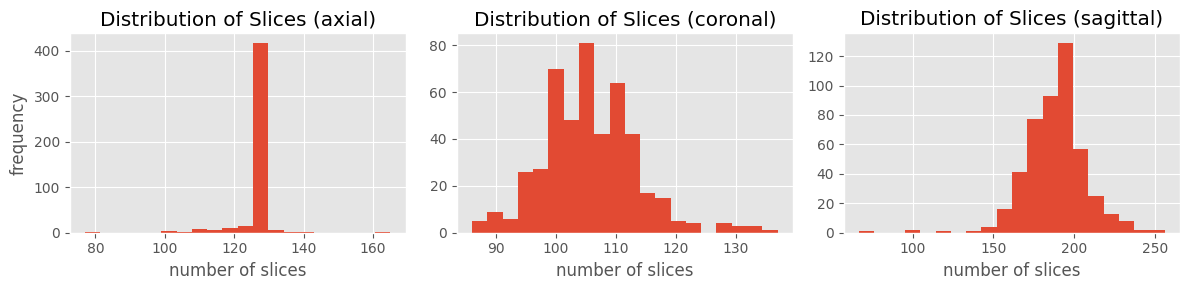

In [5]:
body_bboxes = np.array(filtered_metadata['Body_bbox'].tolist())

fig, axes = plt.subplots(1, 3, figsize=(FIG_WIDTH, 3))
for i, ax, label in zip(range(3), axes, ['axial', 'coronal', 'sagittal']):
  ax.hist(body_bboxes[:, 3 + i], cumulative=False, density=False, bins=20)
  ax.set_title(f'Distribution of Slices ({label})')
  ax.set_xlabel('number of slices')

axes[0].set_ylabel('frequency')
fig.tight_layout()
plt.savefig('../imgs/body-bbox-histograms.svg', bbox_inches='tight')

In [6]:
def rename_organs(series):
  series = series.str.replace('-PTV', '')
  series = series.str.replace('_05', '')
  series = series.str.replace('_03', '')
  series = series.str.replace('_', ' ')
  series = series.str.replace('SpinalCord', 'Spinal Cord')
  series = series.str.replace('BrainStem', 'Brain Stem')
  series = series.str.replace('ParotidCon', 'Parotid Contralateral')
  series = series.str.replace('ParotidIps', 'Parotid Ipsilateral')
  series = series.str.replace('OCavity', 'Oral Cavity')
  series = series.str.replace('PharConst', 'Pharynx Constrictor')
  series = series.str.replace('Cochlea L', 'Cochlea Left')
  series = series.str.replace('Cochlea R', 'Cochlea Right')
  series = series.str.replace('OpticNerve L', 'Optic Nerve Left')
  series = series.str.replace('OpticNerve R', 'Optic Nerve Right')
  series = series.str.replace('Submand', 'Submandibular')
  series = series.str.replace('SubmandibularR', 'Submandibular Right')
  series = series.str.replace('SubmandibularL', 'Submandibular Left')
  series = series.str.replace('Lens L', 'Lens Left')
  series = series.str.replace('Lens R', 'Lens Right')
  series = series.str.replace('Chiasm', 'Chiasma opticum')
  return series

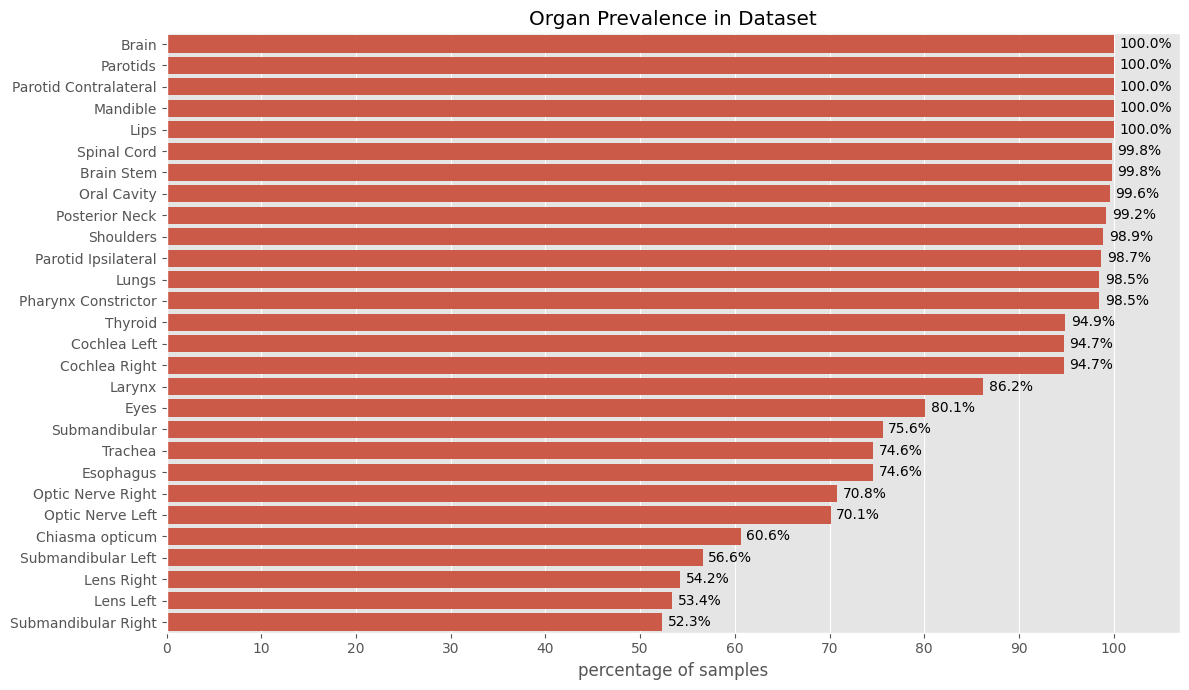

In [7]:
organ_counts = {}
for organ in GDPHMM_OAR_V3:
  organ_counts[organ] = organ_counts.get(organ, 0) + filtered_metadata[f'{organ}_range'].explode().sum()

organ_counts = pd.Series(organ_counts).sort_values(ascending=False) / len(filtered_metadata) * 100
organ_counts = organ_counts.round(1)
organ_counts.index = rename_organs(organ_counts.index)

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 7))
sns.barplot(x=organ_counts.values, y=organ_counts.index, ax=ax)
for container in ax.containers:
  ax.bar_label(container, fmt='%.1f%%', padding=4)
ax.set_xlabel('percentage of samples')
ax.set_ylabel('')
ax.set_title('Organ Prevalence in Dataset')
ax.set_xticks(np.arange(0, 101, 10))
ax.set_xlim(0, 107)
fig.tight_layout()
plt.savefig('../imgs/organ-prevalence.svg', bbox_inches='tight')

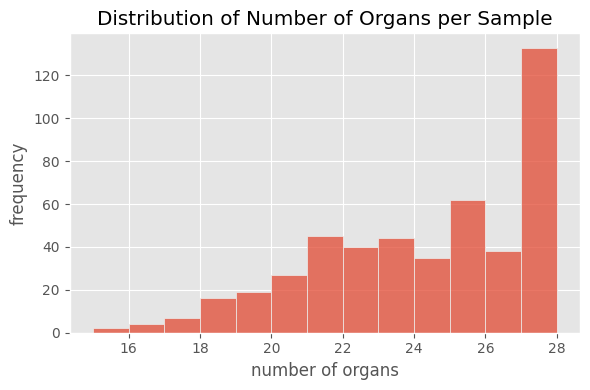

In [8]:
col_names = [f'{organ}_range' for organ in GDPHMM_OAR_V3]
number_of_organs = filtered_metadata[col_names].map(lambda x: x[1] if x is not None else 0).sum(axis=1)

fig, ax = plt.subplots(figsize=(FIG_WIDTH / 2, 4))
sns.histplot(number_of_organs, binwidth=1, ax=ax)
ax.set_xlabel('number of organs')
ax.set_ylabel('frequency')
ax.set_title('Distribution of Number of Organs per Sample')
fig.tight_layout()
plt.savefig('../imgs/number-of-organs-distribution.svg', bbox_inches='tight')

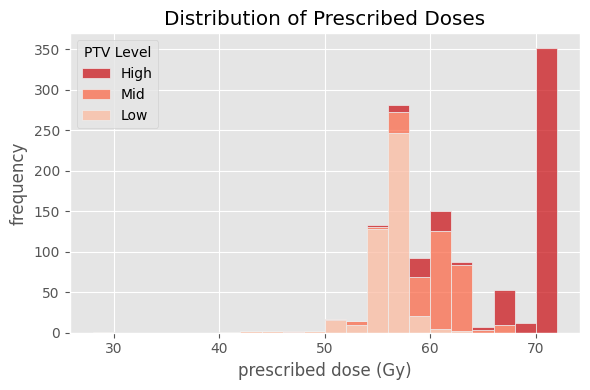

In [9]:
ptv_path = GDPHMM_DATA_BASE_PATH / 'gdphmm-hn' / 'incoming' / 'PTV_DICT.json'
with open(ptv_path, 'r') as f:
  ptv_dict = json.load(f)

ptv_doses = []
for sample_name in filtered_metadata['sample_name']:
  subject_id = sample_name.split('+')[0]
  if subject_id in ptv_dict:
    for level in ['PTV_High', 'PTV_Mid', 'PTV_Low']:
      if level in ptv_dict[subject_id]:
        dose = ptv_dict[subject_id][level]['PDose']
        ptv_doses.append({'dose': dose, 'level': level})

ptv_doses = pd.DataFrame(ptv_doses)
ptv_doses['level'] = ptv_doses['level'].str.replace('PTV_', '')
ptv_doses['level'] = pd.Categorical(ptv_doses['level'], categories=['High', 'Mid', 'Low'], ordered=True)

fig, ax = plt.subplots(figsize=(FIG_WIDTH / 2, 4))
sns.histplot(ptv_doses, x='dose', hue='level', multiple='stack', palette='Reds_r', binwidth=2, ax=ax)
ax.get_legend().set_title('PTV Level')
ax.set_xlabel('prescribed dose (Gy)')
ax.set_ylabel('frequency')
ax.set_title('Distribution of Prescribed Doses')
fig.tight_layout()
plt.savefig('../imgs/ptv-dose-distribution.svg', bbox_inches='tight')

## Background

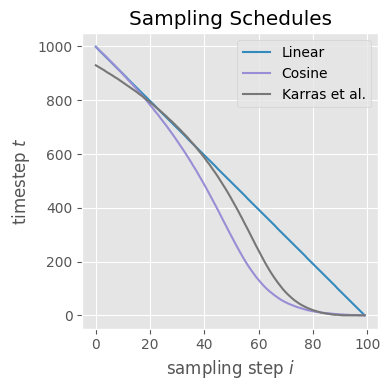

In [10]:
linear_sampler = DDIMSampler(None, 0.0001, 0.02, 1000, None, 100, 0, 'linear')
cosine_sampler = DDIMSampler(None, 0.0001, 0.02, 1000, None, 100, 0, 'cosine')
karras_sampler = DDIMSampler(None, 0.0001, 0.02, 1000, None, 100, 0, 'karras')

colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
fig, ax = plt.subplots(figsize=(FIG_WIDTH / 3, 4))
ax.plot(linear_sampler.sampling_indices, label='Linear', color=colors[1])
ax.plot(cosine_sampler.sampling_indices, label='Cosine', color=colors[2])
ax.plot(karras_sampler.sampling_indices, label='Karras et al.', color=colors[3])
ax.legend(title='', loc='upper right')
ax.set_title('Sampling Schedules')
ax.set_xlabel('sampling step $i$')
ax.set_ylabel('timestep $t$')
fig.tight_layout()
plt.savefig('../imgs/sampling-schedules.svg', bbox_inches='tight')
plt.show()

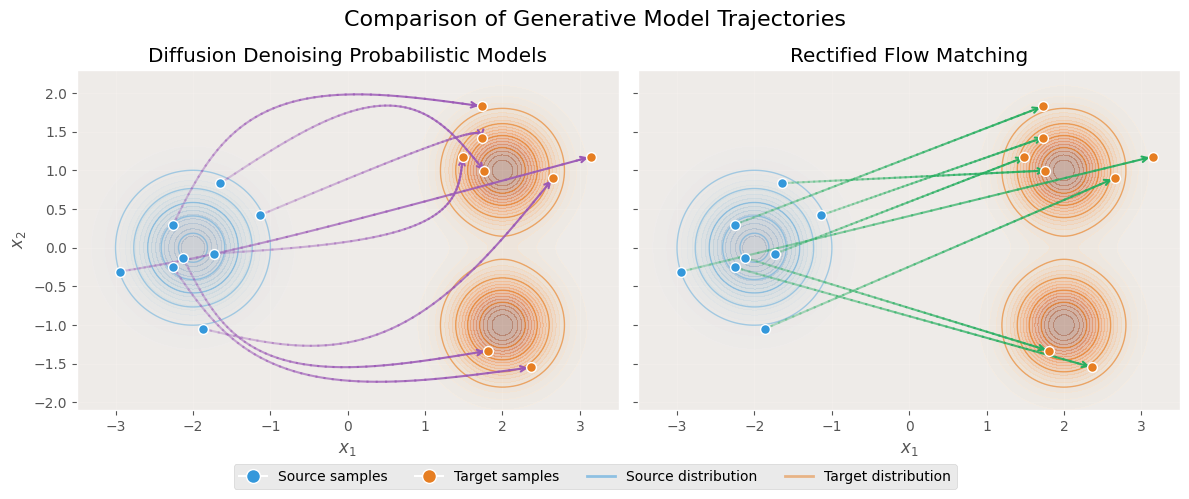

In [11]:
from scipy.stats import multivariate_normal
from scipy.spatial.distance import cdist

np.random.seed(42)

# Define source and target distributions
# Source: Standard Gaussian at origin
source_mean = np.array([-2.0, 0.0])
source_cov = np.array([[0.3, 0.0], [0.0, 0.3]])

# Target: Two-mode Gaussian (mixture)
target_means = [np.array([2.0, 1.0]), np.array([2.0, -1.0])]
target_covs = [np.array([[0.2, 0.0], [0.0, 0.2]]), np.array([[0.2, 0.0], [0.0, 0.2]])]

def sample_source(n):
    return np.random.multivariate_normal(source_mean, source_cov, n)

def sample_target(n):
    # Sample from mixture
    samples = []
    for _ in range(n):
        if np.random.rand() < 0.5:
            samples.append(np.random.multivariate_normal(target_means[0], target_covs[0]))
        else:
            samples.append(np.random.multivariate_normal(target_means[1], target_covs[1]))
    return np.array(samples)

def source_pdf(x, y):
    pos = np.dstack((x, y))
    return multivariate_normal(source_mean, source_cov).pdf(pos)

def target_pdf(x, y):
    pos = np.dstack((x, y))
    pdf1 = multivariate_normal(target_means[0], target_covs[0]).pdf(pos)
    pdf2 = multivariate_normal(target_means[1], target_covs[1]).pdf(pos)
    return 0.5 * (pdf1 + pdf2)

# Grid for plotting
x_grid = np.linspace(-4, 4, 200)
y_grid = np.linspace(-3, 3, 150)
X, Y = np.meshgrid(x_grid, y_grid)

# Compute PDFs
source_Z = source_pdf(X, Y)
target_Z = target_pdf(X, Y)

def ddpm_trajectory(x0, x1, t_steps=50):
    """
    DDPM: Forward process adds noise, reverse process denoises.
    Trajectory goes through high-noise intermediate states (curved path).
    x_t = sqrt(alpha_bar_t) * x_0 + sqrt(1 - alpha_bar_t) * epsilon
    """
    t = np.linspace(0, 1, t_steps)
    trajectory = []

    # Random noise direction for this trajectory
    noise_dir = np.random.randn(2)
    noise_dir = noise_dir / (np.linalg.norm(noise_dir) + 1e-6)

    for ti in t:
        # Base interpolation
        point = (1 - ti) * x0 + ti * x1

        # DDPM curves outward through noisy states
        # Curvature peaks in middle, zero at endpoints
        curve_magnitude = np.sin(ti * np.pi) * 1.0

        # Add noise-direction offset (simulates diffusion through noise space)
        point += noise_dir * curve_magnitude
        trajectory.append(point)

    return np.array(trajectory)

def flow_matching_trajectory(x0, x1, t_steps=50):
    """
    Rectified Flow Matching: Learns straight-line trajectories.
    x_t = (1 - t) * x_0 + t * x_1
    """
    t = np.linspace(0, 1, t_steps)
    trajectory = []

    for ti in t:
        # Perfectly straight interpolation
        point = (1 - ti) * x0 + ti * x1
        trajectory.append(point)

    return np.array(trajectory)

# =============================================================================
# Create the comparison plot
# =============================================================================

fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH, 4.5), sharey=True)
axes = axes.flatten()

models = [
    ('Diffusion Denoising Probabilistic Models', ddpm_trajectory, '#9B59B6'),
    ('Rectified Flow Matching', flow_matching_trajectory, '#27AE60'),
]

# Sample some source points and their corresponding targets
n_trajectories = 8
source_samples = sample_source(n_trajectories)
target_samples = sample_target(n_trajectories)

# Match source to nearest target for better visualization
distances = cdist(source_samples, target_samples)
target_indices = []
used = set()
for i in range(n_trajectories):
    min_idx = np.argmin(distances[i])
    while min_idx in used and len(used) < n_trajectories:
        distances[i, min_idx] = np.inf
        min_idx = np.argmin(distances[i])
    used.add(min_idx)
    target_indices.append(min_idx)
target_samples_matched = target_samples[target_indices]

for ax_idx, (name, traj_func, color) in enumerate(models):
    ax = axes[ax_idx]

    # Plot source distribution (light blue contours)
    ax.contour(X, Y, source_Z, levels=5, colors='#3498DB', alpha=0.4, linewidths=1)
    ax.contourf(X, Y, source_Z, levels=20, cmap='Blues', alpha=0.2)

    # Plot target distribution (light orange contours)
    ax.contour(X, Y, target_Z, levels=5, colors='#E67E22', alpha=0.6, linewidths=1)
    ax.contourf(X, Y, target_Z, levels=20, cmap='Oranges', alpha=0.3)

    # Plot trajectories
    np.random.seed(42 + ax_idx)  # Different but reproducible noise per model
    for i in range(n_trajectories):
        x0 = source_samples[i]
        x1 = target_samples_matched[i]

        traj = traj_func(x0, x1, t_steps=50)

        # Plot trajectory with gradient color
        for j in range(len(traj) - 1):
            alpha = 0.3 + 0.7 * (j / len(traj))
            ax.plot(traj[j:j+2, 0], traj[j:j+2, 1], color=color, alpha=alpha, linewidth=1.5)

        # Plot start point (source)
        ax.scatter(x0[0], x0[1], c='#3498DB', s=50, zorder=5, edgecolors='white', linewidth=1)

        # Plot end point (target)
        ax.scatter(x1[0], x1[1], c='#E67E22', s=50, zorder=5, edgecolors='white', linewidth=1)

        # Add arrow at end
        if len(traj) > 2:
            dx = traj[-1, 0] - traj[-3, 0]
            dy = traj[-1, 1] - traj[-3, 1]
            ax.annotate('', xy=(traj[-1, 0], traj[-1, 1]),
                       xytext=(traj[-1, 0] - dx*0.5, traj[-1, 1] - dy*0.5),
                       arrowprops=dict(arrowstyle='->', color=color, lw=1.5))

    ax.set_xlim(-3.5, 3.5)
    ax.set_ylim(-2.1, 2.3)
    ax.set_aspect('equal')
    ax.set_title(name)
    ax.set_xlabel('$x_1$')
    ax.grid(True, alpha=0.2)

axes[0].set_ylabel('$x_2$')

# Add legend
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#3498DB', markersize=10, label='Source samples'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='#E67E22', markersize=10, label='Target samples'),
    Line2D([0], [0], color='#3498DB', alpha=0.5, linewidth=2, label='Source distribution'),
    Line2D([0], [0], color='#E67E22', alpha=0.5, linewidth=2, label='Target distribution'),
]
fig.legend(handles=legend_elements, loc='lower center', ncol=4, fontsize=10, bbox_to_anchor=(0.5, -0.10))

plt.suptitle('Comparison of Generative Model Trajectories')
plt.tight_layout()
plt.savefig('../imgs/generative-models-trajectories.svg', bbox_inches='tight')
plt.show()

## Evaluation

In [12]:
def compute_dvh(dose, mask, bins):
  """Compute differential DVH (volume fraction ≥ dose)."""
  masked_dose = dose[mask > 0] if mask is not None else dose

  if masked_dose.size == 0:
    return bins[:-1], np.zeros_like(bins[:-1])

  hist, bin_edges = np.histogram(masked_dose, bins=bins)
  cdf = np.cumsum(hist[::-1])[::-1] / np.sum(hist)
  return bin_edges[:-1], cdf




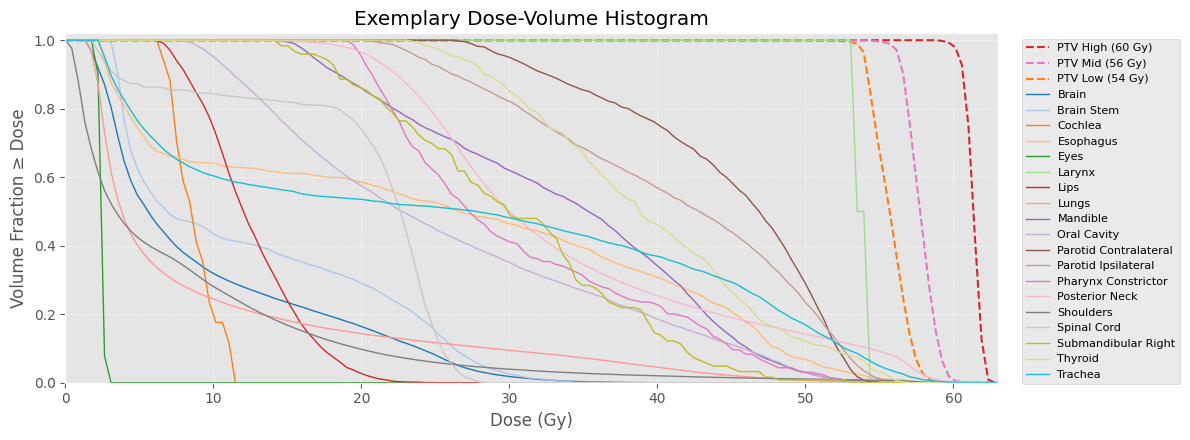

In [13]:
volume_name = 'HNSCC-01-0006+A4Ac+MOS_15521'
subject_id = volume_name.split('+')[0]

# Load volume data
volume_data = np.load(GDPHMM_DATA_BASE_PATH / 'gdphmm-hn' / 'incoming' / 'train' / f'{volume_name}.npz', allow_pickle=True)['arr_0'].item()
dose = volume_data['dose'].astype(np.float64) * volume_data['dose_scale']

# Load PTV prescribed doses
with open(GDPHMM_DATA_BASE_PATH / 'gdphmm-hn' / 'incoming' / 'PTV_DICT.json') as f:
  ptv_info = json.load(f)[subject_id]

# Map volume structure names to PTV_DICT levels
ptv_level_map = {'PTV70': 'PTV_High', 'PTVMid': 'PTV_Mid', 'PTVLow': 'PTV_Low'}
ptv_labels = {}
for struct_name, level in ptv_level_map.items():
  if level in ptv_info:
    ptv_labels[struct_name] = f'{level.replace("PTV_", "PTV ")} ({ptv_info[level]["PDose"]:.0f} Gy)'

# Select structures to plot (only those with voxels present), merging Cochlea_L and Cochlea_R
ptv_names = ['PTV70', 'PTVMid', 'PTVLow']
merge_groups = {'Cochlea': ['Cochlea_L', 'Cochlea_R']}
merged_keys = {name for names in merge_groups.values() for name in names}
oar_names = [o for o in GDPHMM_UNIQUE_OAR if o not in merged_keys and o in volume_data and volume_data[o].sum() > 0]
# Insert merged organs at the position of the first constituent
for merged_name, constituents in merge_groups.items():
  for i, o in enumerate(GDPHMM_UNIQUE_OAR):
    if o == constituents[0]:
      oar_names.insert(min(i, len(oar_names)), merged_name)
      break

# Color palettes: warm reds for PTVs, cool blues/greens for OARs
ptv_colors = ['#D62728', '#E377C2', '#FF7F0E']
oar_cmap = plt.cm.tab20
oar_colors = [oar_cmap(i) for i in range(len(oar_names))]

bins = np.linspace(0, GDPHMM_DOSE_MAX, 200)

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 4.5))

for name, color in zip(ptv_names, ptv_colors):
    mask = volume_data[name]
    if mask.sum() == 0:
        continue
    x, y = compute_dvh(dose, mask, bins)
    label = ptv_labels.get(name, name)
    ax.plot(x, y, color=color, linewidth=1.5, linestyle='--', label=label)

oar_names = sorted(oar_names)
for name, color in zip(oar_names, oar_colors):
    if name in merge_groups:
        mask = np.any([volume_data[c] for c in merge_groups[name] if c in volume_data], axis=0)
    else:
        mask = volume_data[name]
    if mask.sum() == 0:
        continue
    x, y = compute_dvh(dose, mask, bins)
    label = rename_organs(pd.Series([name])).values[0]
    ax.plot(x, y, color=color, linewidth=1, linestyle='-', label=label)

ax.set_xlabel('Dose (Gy)')
ax.set_ylabel('Volume Fraction ≥ Dose')
ax.set_title(f'Exemplary Dose-Volume Histogram')
ax.set_xlim(0, 63)
ax.set_ylim(0, 1.02)
ax.grid(True, linestyle=':')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.02, 1), ncol=1)
fig.tight_layout()
plt.savefig('../imgs/dvh-example.svg', bbox_inches='tight')
plt.show()

## Results

In [14]:
dataset = build_dataset('test')

In [15]:
mamba_199_pred = ModelResults('100-mamba', 'ddpm-1000', 199, 'test', dataset)
beamdiff_199_pred = ModelResults('101-beamdiff', 'ddpm-1000', 199, 'test', dataset)
spdiffdose_199_pred = ModelResults('102-spdiffdose', 'ddpm-1000', 199, 'test', dataset)
dosediff_199_pred = ModelResults('103-dosediff', 'ddpm-1000', 199, 'test', dataset)
diffdp_199_pred = ModelResults('104-diffdp', 'ddpm-1000', 199, 'test', dataset)

c3d_2d_199_pred = ModelResults('105-c3d-2d', 'unet', 199, 'test', dataset)
mednext_m_199_pred = ModelResults('152-mednext-m-l2', 'unet', 199, 'test', dataset)
deeplabv3plus_199_pred = ModelResults('147-deeplabv3plus-l2', 'unet', 199, 'test', dataset)
hdunet_199_pred = ModelResults('153-hdunet-l2', 'unet', 199, 'test', dataset)
mednext_v2_m_199_pred = ModelResults('154-mednext-v2-m-l2', 'unet', 199, 'test', dataset)

In [16]:
pred_baseline_comparison = ModelComparison(
  [mamba_199_pred, beamdiff_199_pred, spdiffdose_199_pred, dosediff_199_pred, diffdp_199_pred, c3d_2d_199_pred, mednext_m_199_pred, deeplabv3plus_199_pred, hdunet_199_pred, mednext_v2_m_199_pred],
  ['MD-Dose', 'BeamDiff', 'SP-DiffDose', 'DoseDiff', 'DiffDP', 'C3D', 'MedNeXt', 'DeepLabv3+', 'HD-UNet', 'MedNeXt v2'],
  ['DDPM'] * 5 + ['U-Net'] * 5
)

pred_baseline_unet_comparison = ModelComparison(
  [c3d_2d_199_pred, mednext_m_199_pred, deeplabv3plus_199_pred, hdunet_199_pred, mednext_v2_m_199_pred],
  ['C3D', 'MedNeXt', 'DeepLabv3+', 'HD-UNet', 'MedNeXt v2'],
  ['U-Net'] * 5
)

pred_baseline_ddpm_comparison = ModelComparison(
  [mamba_199_pred, beamdiff_199_pred, spdiffdose_199_pred, dosediff_199_pred, diffdp_199_pred],
  ['MD-Dose', 'BeamDiff', 'SP-DiffDose', 'DoseDiff', 'DiffDP'],
  ['DDPM'] * 5
)

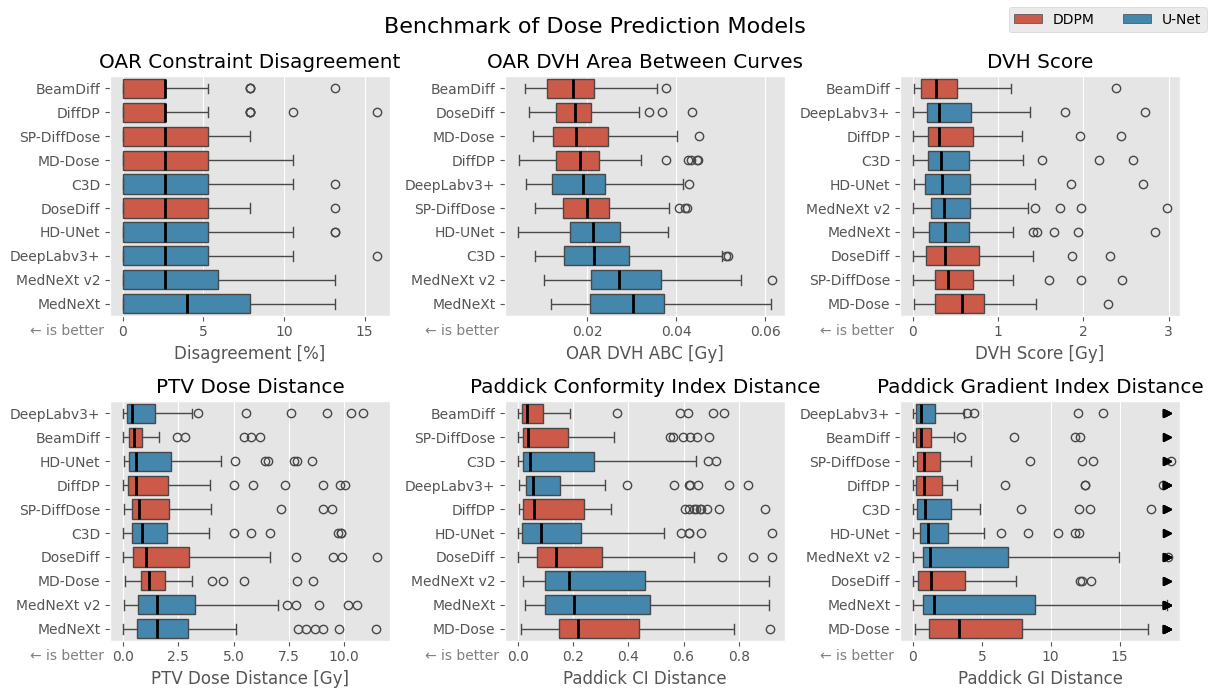

In [17]:
fig, axes = pred_baseline_comparison.plot_metric_distributions(METRICS_PRED, sort=True, outliers=METRICS_PRED[0:5])

fig.suptitle("Benchmark of Dose Prediction Models")
plt.savefig('../imgs/pred-benchmark-metrics.svg', bbox_inches='tight')
plt.show()

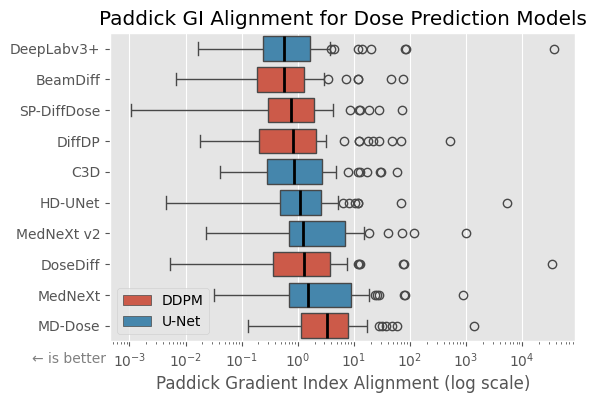

In [18]:
ax = pred_baseline_comparison.plot_metric_distribution(METRICS_PRED[-1], sort=True, outliers=True)
ax.get_figure().set_size_inches(FIG_WIDTH / 2, 4)
ax.set_xscale('log')
ax.set_xlabel('Paddick Gradient Index Alignment (log scale)')
ax.set_title('Paddick GI Alignment for Dose Prediction Models')
plt.savefig('../imgs/pred-benchmark-gi-alignment.svg', bbox_inches='tight')
plt.show()

In [19]:
# Find subjects with highest variance across METRICS_PRED
vm = pred_baseline_comparison.volume_metrics.copy()

# For each subject, compute the std of each metric across models
subject_variance = (
    vm.groupby('file_name')[METRICS_PRED]
    .std()
)

# Normalize each metric by its overall std to make them comparable, then average
normalized = subject_variance / vm[METRICS_PRED].std()
normalized['mean_normalized_std'] = normalized.mean(axis=1)

top_subjects = normalized.sort_values('mean_normalized_std', ascending=False)
top_subjects[['mean_normalized_std']].head(20)

,mean_normalized_std
file_name,
HN-CHUM-003+S2A4Ac+MOS_20285,1.837016
HNSCC-01-0078+A4Ac+MOS_12319,1.221841
HNSCC-01-0035+A4Ac+MOS_49150,0.645656
HNC_169+A4Ac+MOS_33719,0.540136
HNC_199+A4Ac+MOS_357,0.534252
HNC_152+A4Ac+MOS_25955,0.512581
HNC_053+A4Ac+MOS_6535,0.512161
HN-CHUM-007+S2A4Ac+MOS_28117,0.509134
HNC_140+A4Ac+MOS_9927,0.503472


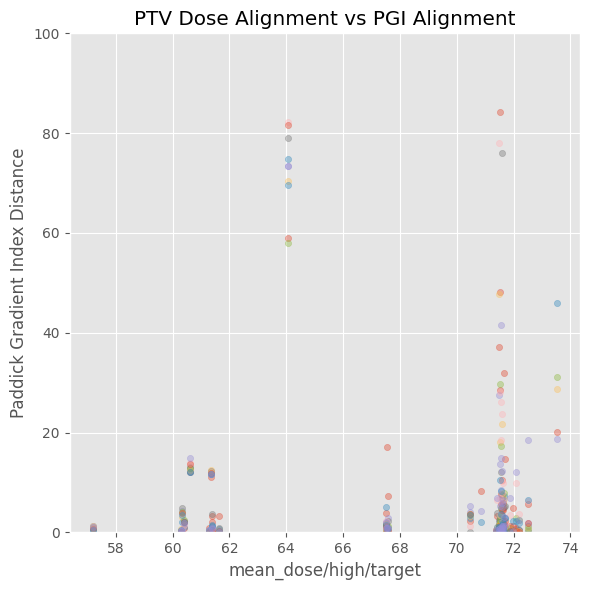

In [20]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH / 2, FIG_WIDTH / 2))

for label in pred_baseline_comparison.result_labels:
    vm = pred_baseline_comparison.volume_metrics[pred_baseline_comparison.volume_metrics['label'] == label]
    ax.scatter(
        vm['vol_mean_dose/high/target'],
        vm['vol_gradient_index/high/abs_diff'],
        label=label, alpha=0.4, s=20
    )

ax.set_xlabel(get_metric_label('mean_dose/high/target'))
ax.set_ylabel(get_metric_label('gradient_index/high/abs_diff'))
ax.set_title('PTV Dose Alignment vs PGI Alignment')
ax.set_ylim(0, 100)
# ax.legend(fontsize=8, loc='upper right')
fig.tight_layout()
plt.show()

In [21]:
pgi_col = 'vol_gradient_index/high/abs_diff'

top_pgi = (
    pred_baseline_comparison.volume_metrics
    .sort_values(pgi_col, ascending=False)
    [['file_name', 'label', pgi_col]]
    .tail(20)
)
top_pgi

,file_name,label,vol_gradient_index/high/abs_diff
404,HNC_031+A4Ac+MOS_58298,HD-UNet,0.023775
469,HN-HGJ-064+S2A4Ac+MOS_40817,MedNeXt v2,0.022919
164,HNC_031+A4Ac+MOS_58298,DoseDiff,0.021931
378,HN-CHUM-007+S2A4Ac+MOS_28117,DeepLabv3+,0.021585
91,HN-HGJ-074+S2A4Ac+MOS_10993,BeamDiff,0.018733
230,HNC_095+A4Ac+MOS_22308,DiffDP,0.017933
367,HN-HGJ-009+S2A4Ac+MOS_16685,DeepLabv3+,0.017609
371,HNSCC-01-0187+A4Ac+MOS_3237,DeepLabv3+,0.016984
59,HNSCC-01-0084+A4Ac+MOS_44704,BeamDiff,0.012367
152,HNC_004+A4Ac+MOS_11506,DoseDiff,0.008505


In [22]:
pred_baseline_comparison.volume_metrics[pred_baseline_comparison.volume_metrics['file_name'] == 'HNSCC-01-0078+A4Ac+MOS_12319'][['label', pgi_col, 'vol_mean_dose/high/pred', 'vol_mean_dose/high/abs_diff']]

,label,vol_gradient_index/high/abs_diff,vol_mean_dose/high/pred,vol_mean_dose/high/abs_diff
5,MD-Dose,1387.851685,69.469254,4.045143
53,BeamDiff,45.949638,71.068520,2.445877
101,SP-DiffDose,18.717632,71.615814,1.898582
149,DoseDiff,34834.210938,67.954445,5.559952
197,DiffDP,28.716866,71.560303,1.954094
245,C3D,31.152660,71.541687,1.972710
293,MedNeXt,904.096313,68.700775,4.813622
341,DeepLabv3+,20.162735,71.660759,1.853638
389,HD-UNet,5302.634277,69.822845,3.691551
437,MedNeXt v2,1021.183105,69.356354,4.158043


HNSCC-01-0078+A4Ac+MOS_12319, 110
HNC_004+A4Ac+MOS_11506, 105
0522c0723+A4Ac+MOS_2890, 80

In [23]:
# sample = 'HNSCC-01-0078+A4Ac+MOS_12319'
# slice_index = 110

# sample = 'HNC_004+A4Ac+MOS_11506'
# slice_index = 105

# sample = '0522c0723+A4Ac+MOS_2890'
# slice_index = 80

sample = 'HNSCC-01-0078+A4Ac+MOS_12319'
slice_index = 110

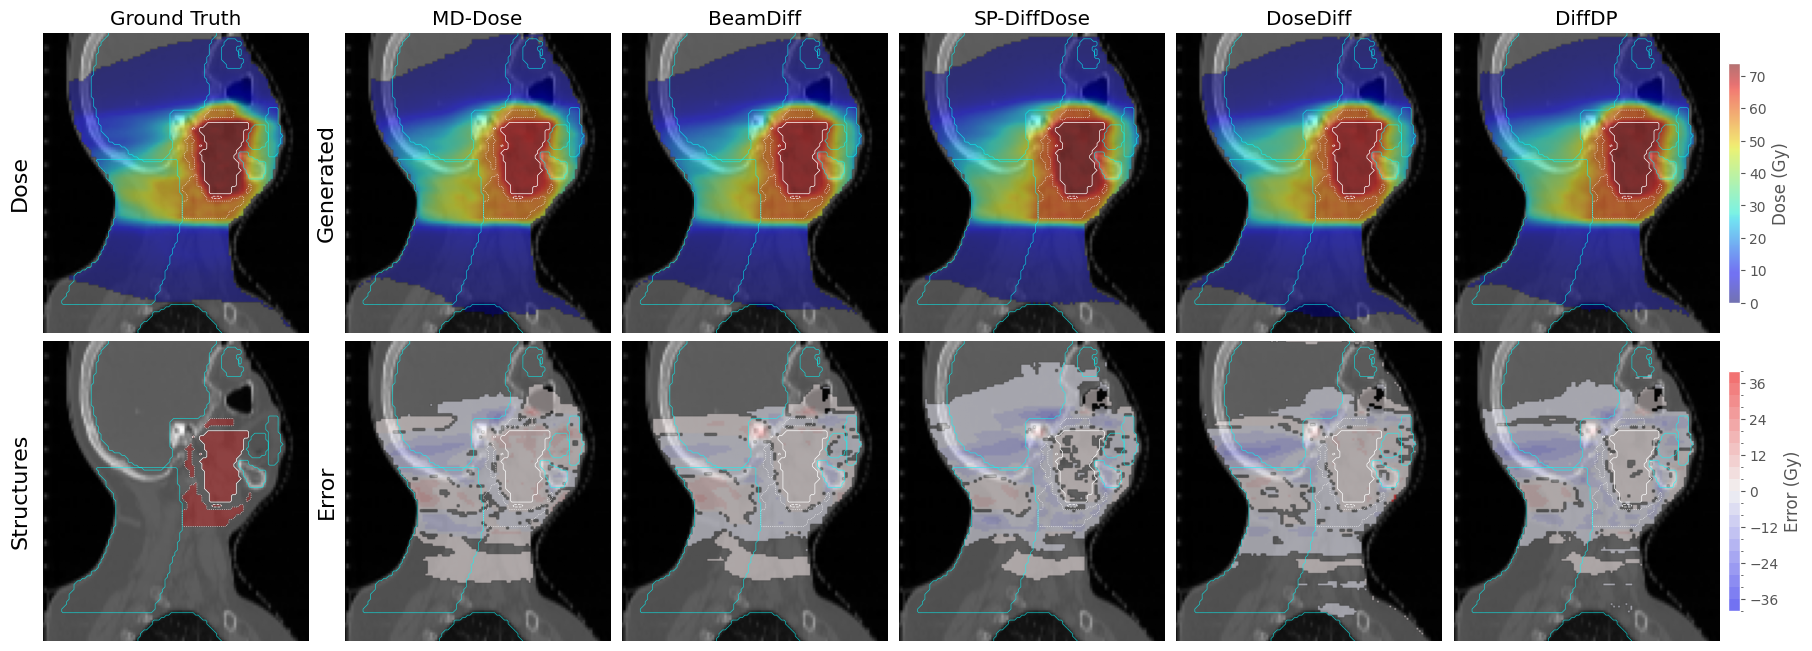

In [24]:
_ = pred_baseline_ddpm_comparison.visualise_slice_comparison_with_ct(
  sample,
  slice_index=slice_index,
  crop_to_body=True,
  crop_padding=0,
  max_error=40,
  dose_range=(0, 74),
  n_error_levels=20,
)
# plt.savefig('../imgs/pred-benchmark-ddpm-slice-3.svg', bbox_inches='tight')
plt.show()

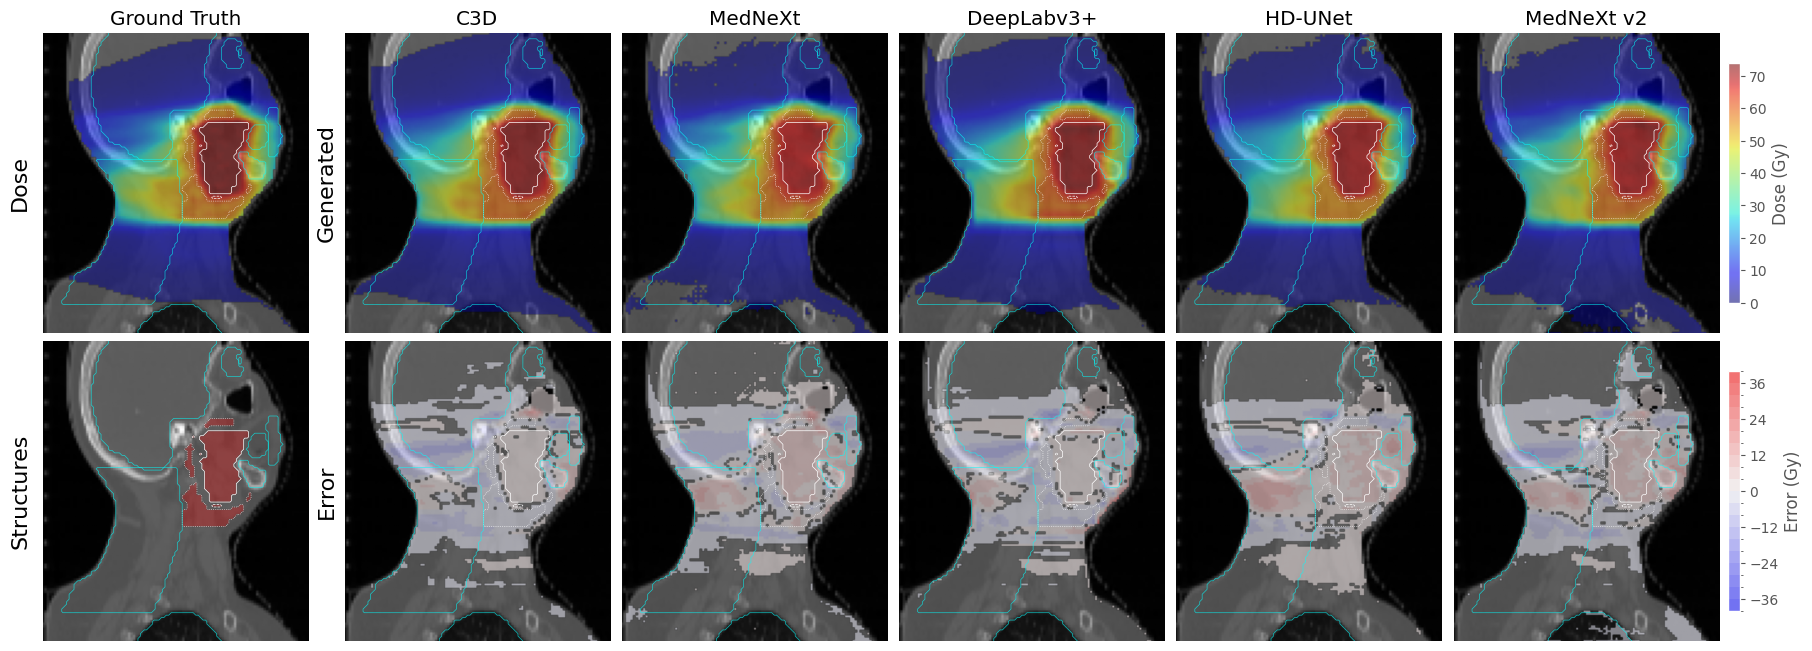

In [25]:
_ = pred_baseline_unet_comparison.visualise_slice_comparison_with_ct(
  sample,
  slice_index=slice_index,
  crop_to_body=True,
  crop_padding=0,
  max_error=40,
  dose_range=(0, 74),
  n_error_levels=20,
)
# plt.savefig('../imgs/pred-benchmark-unet-slice-3.svg', bbox_inches='tight')
plt.show()

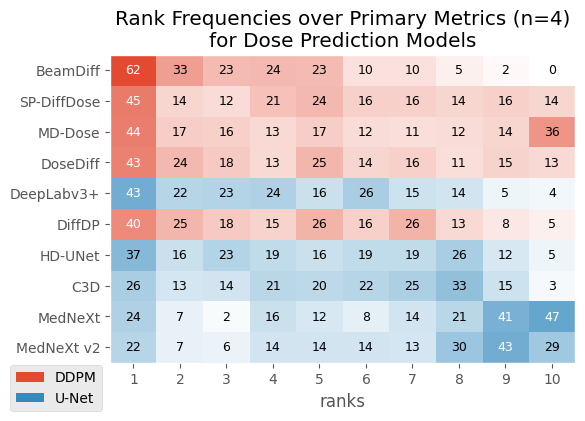

In [26]:
ax = pred_baseline_comparison.plot_rank_frequencies(METRICS_PRED[0:4])
ax.get_figure().set_size_inches(FIG_WIDTH / 2, 4)
ax.set_title('Rank Frequencies over Primary Metrics (n=4)\nfor Dose Prediction Models')
legend = ax.get_legend()
ax.legend(handles=legend.legend_handles, labels=[t.get_text() for t in legend.get_texts()], loc='lower left', bbox_to_anchor=(-0.23, -0.18), ncol=1)
plt.savefig('../imgs/pred-benchmark-rank-freq.svg', bbox_inches='tight')
plt.show()

/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/src/results.py:2172: RuntimeWarning: invalid value encountered in cast
  sample_ranks[:, s] = rankdata(col, method='min').astype(int)


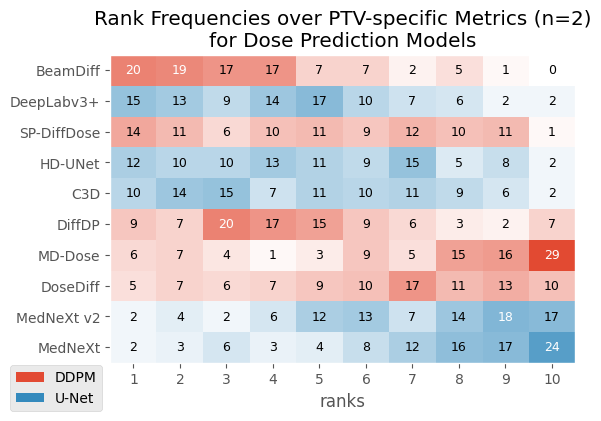

In [27]:
ax = pred_baseline_comparison.plot_rank_frequencies(METRICS_PRED[4:6])
ax.get_figure().set_size_inches(FIG_WIDTH / 2, 4)
ax.set_title('Rank Frequencies over PTV-specific Metrics (n=2)\nfor Dose Prediction Models')
legend = ax.get_legend()
ax.legend(handles=legend.legend_handles, labels=[t.get_text() for t in legend.get_texts()], loc='lower left', bbox_to_anchor=(-0.23, -0.18), ncol=1)
plt.savefig('../imgs/pred-benchmark-ptv-rank-freq.svg', bbox_inches='tight')
plt.show()

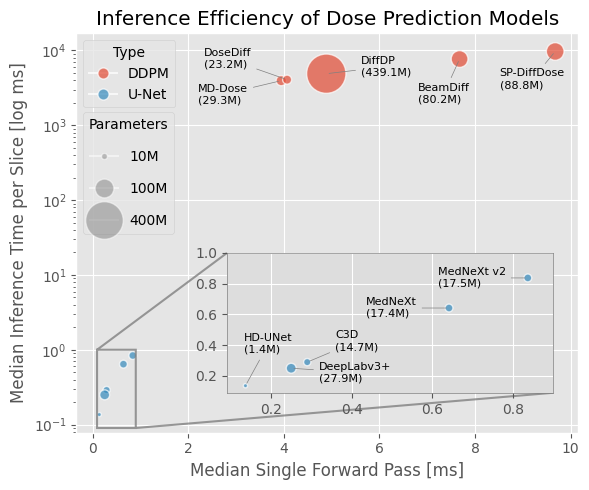

In [28]:
# Build inference time per slice data
data = []
for result, label, group in zip(pred_baseline_comparison.results_list, pred_baseline_comparison.result_labels, pred_baseline_comparison.result_groups):
  durations = result.slice_metrics['duration']
  data.append({'model': label, 'group': group, 'inference_time': durations.median()})

df = pd.DataFrame(data)

# Forward pass time: same for U-Net, /1000 for DDPM
df['forward_pass_time'] = df.apply(
  lambda r: r['inference_time'] / 1000 if r['group'] == 'DDPM' else r['inference_time'], axis=1
)
df['inference_time'] = df['inference_time'] * 1000
df['forward_pass_ms'] = df['forward_pass_time'] * 1000

# Parameter counts (mapped to model labels)
param_counts = {
  'MD-Dose':      29287392,
  'BeamDiff':     80201345,
  'SP-DiffDose':  88770801,
  'DoseDiff':     23240001,
  'DiffDP':      439128385,
  'C3D':          14725282,
  'MedNeXt':      17419202,
  'DeepLabv3+':   27913505,
  'HD-UNet':       1427815,
  'MedNeXt v2':   17474946,
}
df['params'] = df['model'].map(param_counts)
df['params_M'] = df['params'] / 1e6

size_scale = 800 / df['params_M'].max()

# Manual label offsets (x, y) in points per model
ddpm_offsets = {
  'MD-Dose':      (-60, -10),
  'BeamDiff':     (-30, -25),
  'SP-DiffDose':  (-40, -20),
  'DoseDiff':     (-60, 15),
  'DiffDP':       (25, 5),
}

inset_offsets = {
  'C3D':          (20, 15),
  'MedNeXt':      (-60, 0),
  'DeepLabv3+':   (20, -3),
  'HD-UNet':      (-1, 30),
  'MedNeXt v2':   (-65, 0),
}

def plot_scatter(ax, df, annotate=True, offsets=None, skip_groups=None):
  for group, color in [('DDPM', '#E24A33'), ('U-Net', '#348ABD')]:
    mask = df['group'] == group
    sub = df[mask]
    ax.scatter(
      sub['forward_pass_ms'], sub['inference_time'],
      s=sub['params_M'].clip(5) * size_scale, c=color, alpha=0.7,
      edgecolors='white', linewidth=1, label=group, zorder=3
    )
  if annotate:
    for _, row in df.iterrows():
      if skip_groups and row['group'] in skip_groups:
        continue
      ofs = (offsets or {}).get(row['model'], (8, 0))
      ax.annotate(
        f"{row['model']}\n({row['params_M']:.1f}M)",
        (row['forward_pass_ms'], row['inference_time']),
        textcoords='offset points', xytext=ofs, fontsize=8, va='center',
        arrowprops=dict(arrowstyle='-', color='gray', lw=0.5) if abs(ofs[0]) > 8 or abs(ofs[1]) > 8 else None
      )

fig, ax = plt.subplots(figsize=(FIG_WIDTH / 2, 5))
ax.set_yscale('log')
plot_scatter(ax, df, annotate=True, offsets=ddpm_offsets, skip_groups={'U-Net'})
ax.set_xlabel('Median Single Forward Pass [ms]')
ax.set_ylabel('Median Inference Time per Slice [log ms]')
ax.set_title('Inference Efficiency of Dose Prediction Models')

# Color legend with equal-sized markers
from matplotlib.lines import Line2D
color_handles = [
  Line2D([0], [0], marker='o', color='w', markerfacecolor='#E24A33', markersize=8, alpha=0.7, label='DDPM'),
  Line2D([0], [0], marker='o', color='w', markerfacecolor='#348ABD', markersize=8, alpha=0.7, label='U-Net'),
]

# Size legend for parameter count
size_legend_values = [10, 100, 400]
size_handles = [
  Line2D([0], [0], marker='o', color='w', markerfacecolor='gray', alpha=0.5,
         markersize=np.sqrt(v * size_scale), label=f'{v:.0f}M')
  for v in size_legend_values
]

leg1 = ax.legend(handles=color_handles, loc='upper left', title='Type')
ax.add_artist(leg1)
ax.legend(handles=size_handles, loc='center left', title='Parameters', labelspacing=1.3, bbox_to_anchor=(0, 0.65))

# Inset zoom for U-Net region
unet = df[df['group'] == 'U-Net']

axins = ax.inset_axes([0.3, 0.1, 0.65, 0.35])
axins.patch.set_facecolor('#ddd')
# axins.patch.set_alpha(0.5)
for spine in axins.spines.values():
  spine.set_edgecolor('gray')
  spine.set_linewidth(0.5)
plot_scatter(axins, unet, annotate=True, offsets=inset_offsets)
axins.set_xlim(0.09, 0.9)
axins.set_ylim(0.09, 1)
axins.set_xlabel('')
axins.set_ylabel('')
ax.indicate_inset_zoom(axins, edgecolor='gray', alpha=0.8, linewidth=1.5)

fig.tight_layout()
plt.savefig('../imgs/pred-benchmark-efficiency.svg', bbox_inches='tight')
plt.show()

### Training Quantization

In [29]:
beamdiff_amp_199_pred = ModelResults('139-beamdiff-bf16-5', 'ddpm-1000', 199, 'test', dataset)
pred_amp_comparison = ModelComparison(
  [beamdiff_199_pred, beamdiff_amp_199_pred, deeplabv3plus_199_pred],
  ['BeamDiff\n(FP32)', 'BeamDiff\nAMP (BF16)', 'DeepLabv3+\n(FP32)'],
  ['DDPM', 'DDPM', 'U-Net']
)

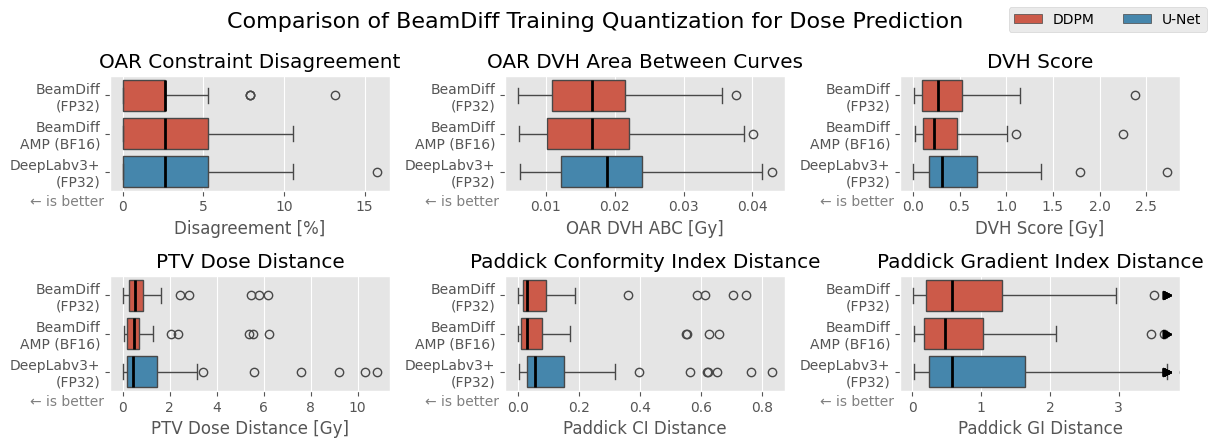

In [30]:
fig, ax = pred_amp_comparison.plot_metric_distributions(METRICS_PRED, sort=False, outliers=METRICS_PRED[0:5])
fig.set_size_inches(FIG_WIDTH, 4.5)
fig.tight_layout()
fig.suptitle("Comparison of BeamDiff Training Quantization for Dose Prediction")
plt.savefig('../imgs/pred-beamdiff-amp.svg', bbox_inches='tight')
plt.show()

### Uncertainty

In [31]:
pred_baseline_results = []

for seed in range(1, 11):
  sampling_name = f'ddpm-seed{seed}-1000' if seed > 1 else 'ddpm-1000'
  pred_baseline_results.append(ModelResults('112-beamdiff-bf16', sampling_name, 199, 'test', dataset))
  pred_baseline_results.append(ModelResults('136-beamdiff-bf16-2', sampling_name, 199, 'test', dataset))
  pred_baseline_results.append(ModelResults('137-beamdiff-bf16-3', sampling_name, 199, 'test', dataset))
  pred_baseline_results.append(ModelResults('138-beamdiff-bf16-4', sampling_name, 199, 'test', dataset))
  pred_baseline_results.append(ModelResults('139-beamdiff-bf16-5', sampling_name, 199, 'test', dataset))

pred_beamdiff_baseline_comparison = ModelComparison(pred_baseline_results, ['Model 1'] * 10 + ['Model 2'] * 10 + ['Model 3'] * 10 + ['Model 4'] * 10 + ['Model 5'] * 10, ['DDPM'] * 50)

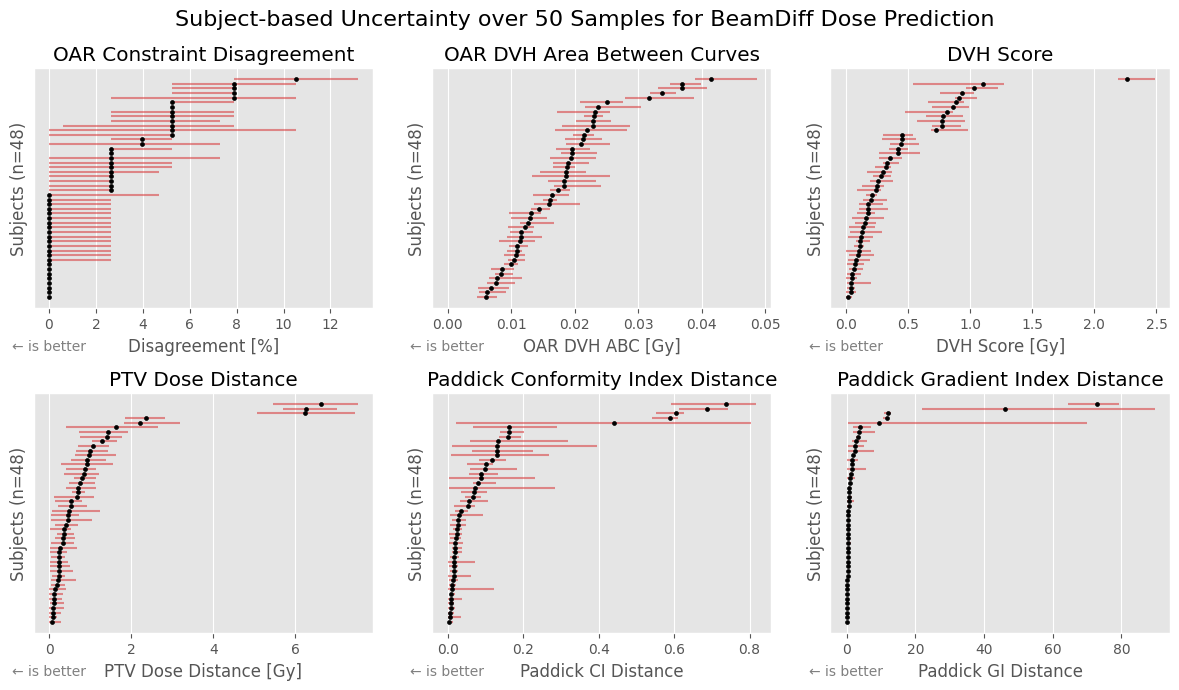

In [32]:
# Build a long-form DataFrame with all runs pooled, keyed by subject
rows = []
for result in pred_beamdiff_baseline_comparison.results_list:
  for _, row in result.volume_metrics.iterrows():
    rows.append(row)

all_volumes = pd.DataFrame(rows)

# Per-subject statistics for each metric
per_subject = {}
for metric in METRICS_PRED:
  grouped = all_volumes.groupby('file_name')[metric]
  per_subject[metric] = pd.DataFrame({
    'median': grouped.median(),
    'iqr': grouped.quantile(0.75) - grouped.quantile(0.25),
    'range': grouped.max() - grouped.min(),
    'q025': grouped.quantile(0.025),
    'q975': grouped.quantile(0.975),
    'width': grouped.quantile(0.975) - grouped.quantile(0.025),
    'max': grouped.max(),
  })

fig, axes = plt.subplots(2, 3, figsize=(FIG_WIDTH, 7))
axes = axes.flatten()

for i, metric in enumerate(METRICS_PRED):
  stats = per_subject[metric].sort_values(['median', 'q025', 'q975'])
  label = get_metric_label(metric)
  abbr = get_metric_abbr(metric)
  ax = axes[i]

  # Plot each subject as a horizontal bar from q025 to q975, with median dot
  y = np.arange(len(stats))
  ax.hlines(y, stats['q025'], stats['q975'], color='tab:red', alpha=0.5, linewidth=1.5)
  ax.scatter(stats['median'], y, color='black', s=8, zorder=3)

  dir_symbol = '→' if is_higher_better(metric) else '←'
  ax.set_title(f'{label}')
  ax.set_xlabel(abbr)
  ax.set_ylabel('Subjects (n=48)')
  ax.set_yticks([])
  ax.set_xlim(-0.05 * stats['max'].max())
  ax.text(0.18, -0.132, f'{dir_symbol} is better  ', transform=ax.transAxes,
    ha='right', va='top', fontsize='medium', color='gray')

fig.suptitle('Subject-based Uncertainty over 50 Samples for BeamDiff Dose Prediction')
fig.tight_layout()
plt.savefig('../imgs/pred-beamdiff-uncertainty.svg', bbox_inches='tight')
plt.show()

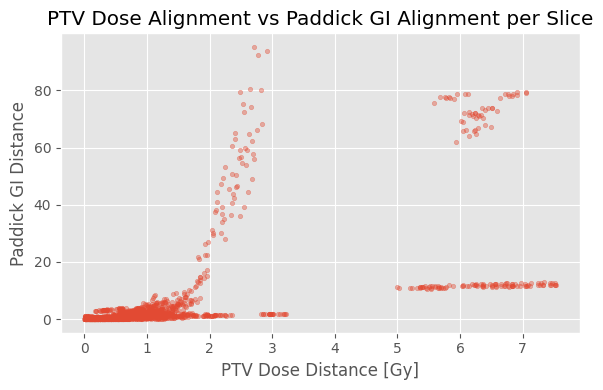

In [33]:
vm = pred_beamdiff_baseline_comparison.volume_metrics.copy()
x_col = 'vol_mean_dose/high/abs_diff'
y_col = 'vol_gradient_index/high/abs_diff'

fig, ax = plt.subplots(figsize=(FIG_WIDTH / 2, 4))

ax.scatter(vm[x_col], vm[y_col], alpha=0.4, s=10)

ax.set_xlabel(get_metric_abbr('mean_dose/high/abs_diff'))
ax.set_ylabel(get_metric_abbr('gradient_index/high/abs_diff'))
ax.set_title('PTV Dose Alignment vs Paddick GI Alignment per Slice')
fig.tight_layout()
plt.savefig('../imgs/pred-beamdiff-ptv-dose-vs-pgi.svg', bbox_inches='tight')
plt.show()


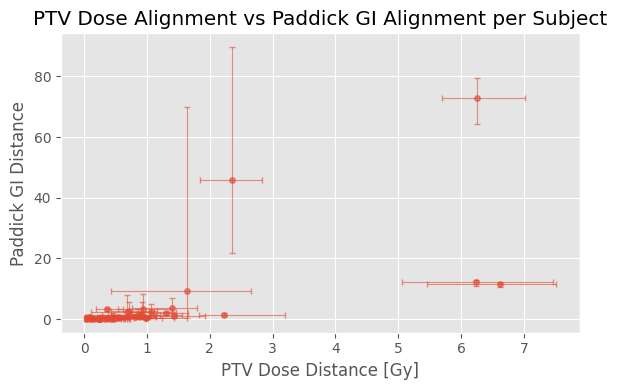

In [34]:
vm = pred_beamdiff_baseline_comparison.volume_metrics.copy()
x_col = 'vol_mean_dose/high/abs_diff'
y_col = 'vol_gradient_index/high/abs_diff'

# Aggregate per subject: median and 95% CI
per_subj = vm.groupby('file_name').agg(
    x_median=(x_col, 'median'),
    x_q025=(x_col, lambda s: s.quantile(0.025)),
    x_q975=(x_col, lambda s: s.quantile(0.975)),
    y_median=(y_col, 'median'),
    y_q025=(y_col, lambda s: s.quantile(0.025)),
    y_q975=(y_col, lambda s: s.quantile(0.975)),
).dropna()

fig, ax = plt.subplots(figsize=(FIG_WIDTH / 2, 4))

ax.errorbar(
    per_subj['x_median'], per_subj['y_median'],
    xerr=[per_subj['x_median'] - per_subj['x_q025'], per_subj['x_q975'] - per_subj['x_median']],
    yerr=[per_subj['y_median'] - per_subj['y_q025'], per_subj['y_q975'] - per_subj['y_median']],
    fmt='o', ms=4, alpha=0.6, elinewidth=0.8, capsize=2, color='#E24A33'
)

ax.set_xlabel(get_metric_abbr('mean_dose/high/abs_diff'))
ax.set_ylabel(get_metric_abbr('gradient_index/high/abs_diff'))
ax.set_title('PTV Dose Alignment vs Paddick GI Alignment per Subject')
fig.tight_layout()
plt.savefig('../imgs/pred-beamdiff-ptv-dose-vs-pgi-volumes.svg', bbox_inches='tight')
plt.show()

In [35]:
x_thresh = 2
y_thresh = 7

outliers = per_subj[(per_subj['x_median'] >= x_thresh) | (per_subj['y_median'] >= y_thresh)].copy()
outliers['subject'] = outliers.index.map(lambda f: f.split('+')[0])
outliers[['subject', 'x_median', 'y_median']].sort_values('x_median', ascending=False)

,subject,x_median,y_median
file_name,,,
HNSCC-01-0006+A4Ac+MOS_15521,HNSCC-01-0006,6.618286,11.614330
HNSCC-01-0164+A4Ac+MOS_52248,HNSCC-01-0164,6.249130,72.847473
HN-CHUS-102+S2A4Ac+MOS_51735,HN-CHUS-102,6.244923,12.087406
HNSCC-01-0078+A4Ac+MOS_12319,HNSCC-01-0078,2.360264,45.970358
HNSCC-01-0195+A4Ac+MOS_58481,HNSCC-01-0195,2.224365,1.393198
HNSCC-01-0060+A4Ac+MOS_19273,HNSCC-01-0060,1.634567,9.260739


In [36]:
with open(GDPHMM_DATA_BASE_PATH / 'gdphmm-hn' / 'incoming' / 'PTV_DICT.json') as f:
    ptv_dict = json.load(f)

rows = []
for file_name in outliers.index:
    subject_id = file_name.split('+')[0]
    target_dose = vm.loc[vm['file_name'] == file_name, 'vol_mean_dose/high/target'].median()
    pred_dose = vm.loc[vm['file_name'] == file_name, 'vol_mean_dose/high/pred'].median()
    prescribed = ptv_dict.get(subject_id, {}).get('PTV_High', {}).get('PDose', None)
    rows.append({
        'subject': subject_id,
        'file_name': file_name,
        'mean_dose_target': target_dose,
        'mean_dose_pred': pred_dose,
        'prescribed_dose': prescribed,
        'difference': target_dose - prescribed if prescribed is not None else None,
        'pred_difference': pred_dose - prescribed if prescribed is not None else None,
    })

outlier_doses = pd.DataFrame(rows).sort_values('difference', ascending=False)
outlier_doses

,subject,file_name,mean_dose_target,mean_dose_pred,prescribed_dose,difference,pred_difference
2,HNSCC-01-0060,HNSCC-01-0060+A4Ac+MOS_19273,71.660477,70.025909,70.0,1.660477,0.025909
0,HN-CHUS-102,HN-CHUS-102+S2A4Ac+MOS_51735,60.620892,66.865814,59.0,1.620892,7.865814
5,HNSCC-01-0195,HNSCC-01-0195+A4Ac+MOS_58481,67.519722,69.744087,66.0,1.519722,3.744087
3,HNSCC-01-0078,HNSCC-01-0078+A4Ac+MOS_12319,73.514397,71.154133,72.0,1.514397,-0.845867
1,HNSCC-01-0006,HNSCC-01-0006+A4Ac+MOS_15521,61.360386,67.978672,60.0,1.360386,7.978672
4,HNSCC-01-0164,HNSCC-01-0164+A4Ac+MOS_52248,64.048485,70.297615,63.0,1.048485,7.297615


In [37]:
dvh_per_subj = vm.groupby('file_name')['vol_dvh'].median()
high_dvh = dvh_per_subj[dvh_per_subj > 2].sort_values(ascending=False)
high_dvh.index = high_dvh.index.map(lambda f: f.split('+')[0])
high_dvh.rename('median_dvh_score').reset_index()

,file_name,median_dvh_score
0,HN-CHUS-102,2.265667


HN-CHUS-102, HNSCC-01-0006, HNSCC-01-0164: 
- over-predicted PTV (too high value/mean compared to prescription) + 7.2-8
- have high PTV Dose Alignment
- have also high PGIA


HNSCC-01-0078:
- under-predicted PTV (too low value/mean compared to prescription) - 0.84
- not so high PTV Dose Alignment

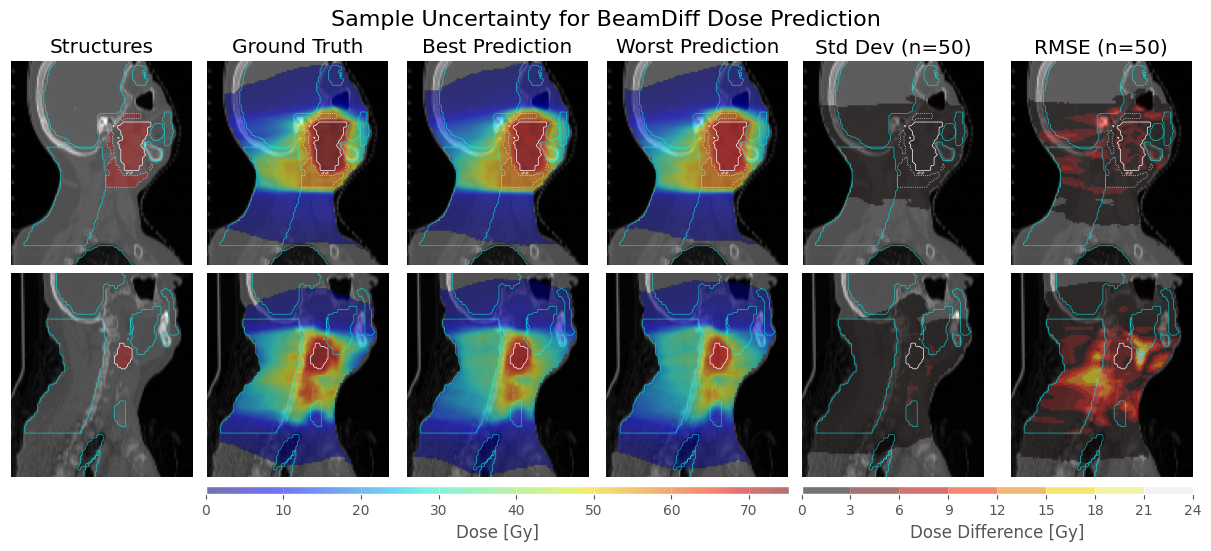

In [38]:
fig, axes = pred_beamdiff_baseline_comparison.visualise_uncertainty_with_ct([
	('HNSCC-01-0078+A4Ac+MOS_12319', 110),
	('HN-CHUM-003+S2A4Ac+MOS_20285', 90),

], crop_to_body=True, crop_padding=0, n_error_levels=8, max_error=24)

fig.suptitle('Sample Uncertainty for BeamDiff Dose Prediction')
plt.savefig('../imgs/pred-beamdiff-sample-uncertainty.svg', bbox_inches='tight')
plt.show()

### Sampling Quantization

In [39]:
beamdiff_samp_bf16_199_pred = ModelResults('112-beamdiff-bf16', 'ddpm-1000-bf16-amp', 199, 'test', dataset)
beamdiff_samp_fp16_199_pred = ModelResults('112-beamdiff-bf16', 'ddpm-1000-fp16-amp', 199, 'test', dataset)

In [40]:
pred_samp_quant_comparison = ModelComparison(
  [beamdiff_amp_199_pred, beamdiff_samp_bf16_199_pred, beamdiff_samp_fp16_199_pred],
  ['FP32', 'BF16', 'FP16'],
  ['DDPM', 'DDPM', 'DDPM']
)

pred_samp_quant_bf16_comparison = ModelComparison(
  [beamdiff_amp_199_pred, beamdiff_samp_bf16_199_pred],
  ['FP32', 'BF16'],
  ['DDPM', 'DDPM']
)

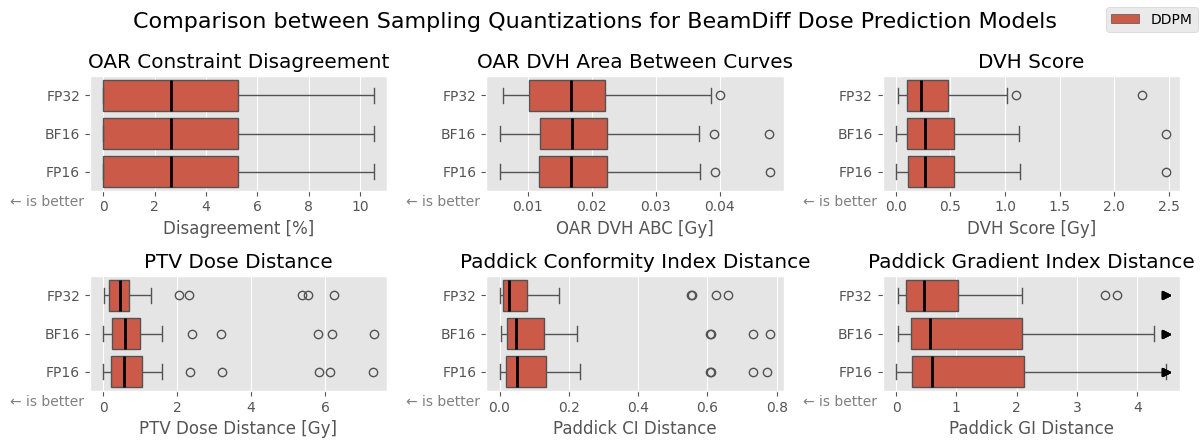

In [41]:
fig, axes = pred_samp_quant_comparison.plot_metric_distributions(METRICS_PRED, sort=False, outliers=METRICS_PRED[0:5])

fig.set_size_inches(FIG_WIDTH, 4.5)
fig.tight_layout()
fig.suptitle("Comparison between Sampling Quantizations for BeamDiff Dose Prediction Models")
plt.savefig('../imgs/pred-beamdiff-sampling-quantization.svg', bbox_inches='tight')
plt.show()

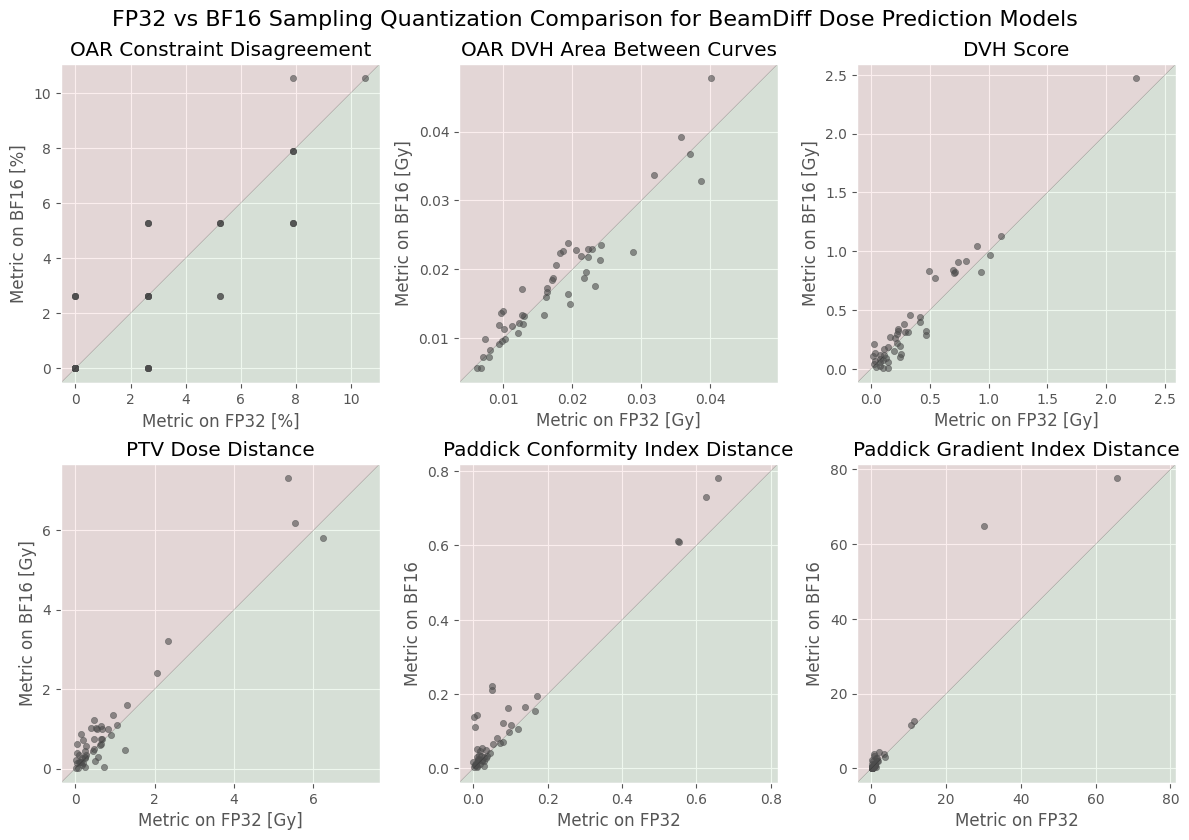

In [42]:
# Scatter plots: FP32 vs BF16 per metric
from matplotlib.patches import Polygon

fp32_vm = pred_samp_quant_comparison.volume_metrics[pred_samp_quant_comparison.volume_metrics['label'] == 'FP32'].set_index('file_name')
bf16_vm = pred_samp_quant_comparison.volume_metrics[pred_samp_quant_comparison.volume_metrics['label'] == 'BF16'].set_index('file_name')

n_metrics = len(METRICS_PRED)
n_cols = min(3, n_metrics)
n_rows = (n_metrics + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(FIG_WIDTH, 8.5), squeeze=False)
axes = axes.flatten()

for i, metric in enumerate(METRICS_PRED):
    ax = axes[i]
    x = fp32_vm[metric]
    y = bf16_vm.reindex(x.index)[metric]
    mask = ~(x.isna() | y.isna())
    x, y = x[mask], y[mask]

    all_vals = pd.concat([x, y])
    lo, hi = all_vals.min(), all_vals.max()
    margin = (hi - lo) * 0.05
    lo, hi = lo - margin, hi + margin

    # Background triangles: green = BF16 better, red = BF16 worse
    higher_better = is_higher_better(metric)
    if higher_better:
        better_verts = [(lo, lo), (lo, hi), (hi, hi)]
        worse_verts = [(lo, lo), (hi, hi), (hi, lo)]
    else:
        better_verts = [(lo, lo), (hi, hi), (hi, lo)]
        worse_verts = [(lo, lo), (lo, hi), (hi, hi)]

    ax.add_patch(Polygon(better_verts, closed=True, facecolor='#2ca02c', alpha=0.08))
    ax.add_patch(Polygon(worse_verts, closed=True, facecolor='#d62728', alpha=0.08))

    # Diagonal line
    ax.plot([lo, hi], [lo, hi], 'k', linewidth=0.2, alpha=0.5)

    ax.scatter(x, y, s=20, alpha=0.6, c='0.3')

    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_aspect('equal')

    # Sync ticks between x and y
    ax.set_yticks(ax.get_xticks())
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)

    unit = get_metric_unit(metric)
    unit_suffix = f' [{unit}]' if unit else ''
    ax.set_xlabel(f'Metric on FP32{unit_suffix}')
    ax.set_ylabel(f'Metric on BF16{unit_suffix}')
    ax.set_title(get_metric_label(metric))

# Hide unused axes
for j in range(n_metrics, len(axes)):
    axes[j].set_visible(False)

fig.suptitle('FP32 vs BF16 Sampling Quantization Comparison for BeamDiff Dose Prediction Models')
fig.tight_layout()
plt.savefig('../imgs/pred-beamdiff-sampling-quantization-volumes.svg', bbox_inches='tight')
plt.show()

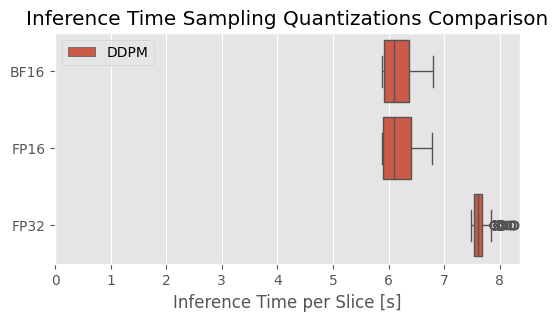

In [43]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH / 2, 3))
pred_samp_quant_comparison.plot_inference_times('slice', 'seconds', ax=ax)
ax.set_xlim(0)
ax.set_title('Inference Time Sampling Quantizations Comparison')
ax.set_xlabel('Inference Time per Slice [s]')
plt.savefig('../imgs/pred-beamdiff-sampling-quantization-inference-times.svg', bbox_inches='tight')
plt.show()

In [44]:
for result, label in zip(pred_samp_quant_comparison.results_list, pred_samp_quant_comparison.result_labels):
    median_duration = result.slice_metrics['duration'].median()
    print(f'{label}: {median_duration:.4f} s')


FP32: 7.6064 s
BF16: 6.0915 s
FP16: 6.1054 s


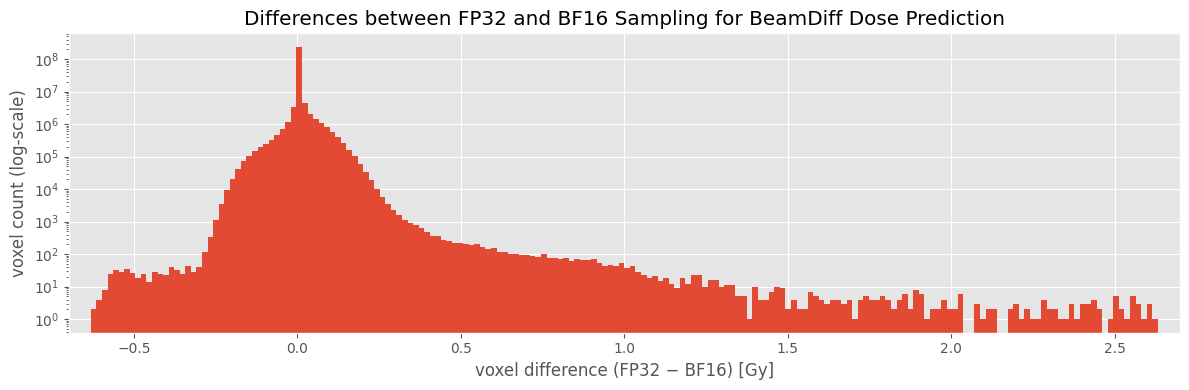

Total voxels: 256,171,520
Mean difference: 0.001786
Std difference: 0.017477
Max absolute difference: 2.629750


In [45]:
beamdiff_samp_fp32_199_pred = ModelResults('112-beamdiff-bf16', 'ddpm-1000', 199, 'test', dataset)

n_bins = 200
bin_edges = np.linspace(-0.7, 2.7, n_bins + 1)
counts = np.zeros(n_bins, dtype=np.int64)

stats_sum = 0.0
stats_sq_sum = 0.0
stats_max = 0.0
stats_n = 0

for sample_file in beamdiff_samp_fp32_199_pred.volume_metrics['file_name']:
    sample_name = sample_file.replace('.npz', '')
    fp32_vol = beamdiff_samp_fp32_199_pred.for_sample(sample_name).load_pred_volume()
    bf16_vol = beamdiff_samp_bf16_199_pred.for_sample(sample_name).load_pred_volume()
    diff = (fp32_vol - bf16_vol).ravel()

    counts += np.histogram(diff, bins=bin_edges)[0]
    stats_sum += diff.sum()
    stats_sq_sum += (diff ** 2).sum()
    stats_max = max(stats_max, np.abs(diff).max())
    stats_n += len(diff)

mean_diff = stats_sum / stats_n
std_diff = np.sqrt(stats_sq_sum / stats_n - mean_diff ** 2)

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 4))
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
ax.bar(bin_centers, counts, width=bin_edges[1] - bin_edges[0], edgecolor='none')
ax.set_yscale('log')
ax.set_xlim(bin_edges[0], bin_edges[-1])
ax.set_xlabel('voxel difference (FP32 − BF16) [Gy]')
ax.set_ylabel('voxel count (log-scale)')
ax.set_title('Differences between FP32 and BF16 Sampling for BeamDiff Dose Prediction')
fig.tight_layout()
plt.savefig('../imgs/pred-beamdiff-sampling-quantization-differences.svg', bbox_inches='tight')
plt.show()

print(f'Total voxels: {stats_n:,}')
print(f'Mean difference: {mean_diff:.6f}')
print(f'Std difference: {std_diff:.6f}')
print(f'Max absolute difference: {stats_max:.6f}')

### Reduction of T

- Inference Time per Number of Iterations
- Reducing T in Training vs. Sampling (Appendix)
- DDPM Heatmap
- DDPM vs. DDIM vs. DEIS (Appendix) 
- DDIM: Linear vs. Cosine vs. Karras (Appendix)
- Distillation: DDPM vs. Distillation Heatmap or Metrics over T (Appendix)

In [46]:
beamdiff_train_500_pred = ModelResults('113-t-500', 'ddpm-500', 199, 'test', dataset)
beamdiff_train_100_pred = ModelResults('114-t-100', 'ddpm-100', 199, 'test', dataset)
beamdiff_train_50_pred = ModelResults('115-t-50', 'ddpm-50', 199, 'test', dataset)
beamdiff_train_10_pred = ModelResults('116-t-10', 'ddpm-10', 199, 'test', dataset)
beamdiff_train_5_pred = ModelResults('117-t-5', 'ddpm-5', 199, 'test', dataset)
beamdiff_train_1_pred = ModelResults('118-t-1', 'ddpm-1', 199, 'test', dataset)

beamdiff_ddpm_500_pred = ModelResults('112-beamdiff-bf16', 'ddpm-500', 199, 'test', dataset)
beamdiff_ddpm_100_pred = ModelResults('112-beamdiff-bf16', 'ddpm-100', 199, 'test', dataset)
beamdiff_ddpm_50_pred = ModelResults('112-beamdiff-bf16', 'ddpm-50', 199, 'test', dataset)
beamdiff_ddpm_10_pred = ModelResults('112-beamdiff-bf16', 'ddpm-10', 199, 'test', dataset)
beamdiff_ddpm_5_pred = ModelResults('112-beamdiff-bf16', 'ddpm-5', 199, 'test', dataset)
beamdiff_ddpm_4_pred = ModelResults('112-beamdiff-bf16', 'ddpm-4', 199, 'test', dataset)
beamdiff_ddpm_3_pred = ModelResults('112-beamdiff-bf16', 'ddpm-3', 199, 'test', dataset)
beamdiff_ddpm_2_pred = ModelResults('112-beamdiff-bf16', 'ddpm-2', 199, 'test', dataset)
beamdiff_ddpm_1_pred = ModelResults('112-beamdiff-bf16', 'ddpm-1', 199, 'test', dataset)

beamdiff_ddim_1000_pred = ModelResults('112-beamdiff-bf16', 'ddim-1000', 199, 'test', dataset)
beamdiff_ddim_500_pred = ModelResults('112-beamdiff-bf16', 'ddim-500', 199, 'test', dataset)
beamdiff_ddim_100_pred = ModelResults('112-beamdiff-bf16', 'ddim-100', 199, 'test', dataset)
beamdiff_ddim_50_pred = ModelResults('112-beamdiff-bf16', 'ddim-50', 199, 'test', dataset)
beamdiff_ddim_10_pred = ModelResults('112-beamdiff-bf16', 'ddim-10', 199, 'test', dataset)
beamdiff_ddim_5_pred = ModelResults('112-beamdiff-bf16', 'ddim-5', 199, 'test', dataset)
beamdiff_ddim_4_pred = ModelResults('112-beamdiff-bf16', 'ddim-4', 199, 'test', dataset)
beamdiff_ddim_3_pred = ModelResults('112-beamdiff-bf16', 'ddim-3', 199, 'test', dataset)
beamdiff_ddim_2_pred = ModelResults('112-beamdiff-bf16', 'ddim-2', 199, 'test', dataset)
beamdiff_ddim_1_pred = ModelResults('112-beamdiff-bf16', 'ddim-1', 199, 'test', dataset)

beamdiff_ddim_cosine_1000_pred = ModelResults('112-beamdiff-bf16', 'ddim-cosine-1000', 199, 'test', dataset)
beamdiff_ddim_cosine_500_pred = ModelResults('112-beamdiff-bf16', 'ddim-cosine-500', 199, 'test', dataset)
beamdiff_ddim_cosine_100_pred = ModelResults('112-beamdiff-bf16', 'ddim-cosine-100', 199, 'test', dataset)
beamdiff_ddim_cosine_50_pred = ModelResults('112-beamdiff-bf16', 'ddim-cosine-50', 199, 'test', dataset)
beamdiff_ddim_cosine_10_pred = ModelResults('112-beamdiff-bf16', 'ddim-cosine-10', 199, 'test', dataset)
beamdiff_ddim_cosine_5_pred = ModelResults('112-beamdiff-bf16', 'ddim-cosine-5', 199, 'test', dataset)
beamdiff_ddim_cosine_4_pred = ModelResults('112-beamdiff-bf16', 'ddim-cosine-4', 199, 'test', dataset)
beamdiff_ddim_cosine_3_pred = ModelResults('112-beamdiff-bf16', 'ddim-cosine-3', 199, 'test', dataset)
beamdiff_ddim_cosine_2_pred = ModelResults('112-beamdiff-bf16', 'ddim-cosine-2', 199, 'test', dataset)
beamdiff_ddim_cosine_1_pred = ModelResults('112-beamdiff-bf16', 'ddim-cosine-1', 199, 'test', dataset)

beamdiff_ddim_karras_1000_pred = ModelResults('112-beamdiff-bf16', 'ddim-karras-1000', 199, 'test', dataset)
beamdiff_ddim_karras_500_pred = ModelResults('112-beamdiff-bf16', 'ddim-karras-500', 199, 'test', dataset)
beamdiff_ddim_karras_100_pred = ModelResults('112-beamdiff-bf16', 'ddim-karras-100', 199, 'test', dataset)
beamdiff_ddim_karras_50_pred = ModelResults('112-beamdiff-bf16', 'ddim-karras-50', 199, 'test', dataset)
beamdiff_ddim_karras_10_pred = ModelResults('112-beamdiff-bf16', 'ddim-karras-10', 199, 'test', dataset)
beamdiff_ddim_karras_5_pred = ModelResults('112-beamdiff-bf16', 'ddim-karras-5', 199, 'test', dataset)
beamdiff_ddim_karras_4_pred = ModelResults('112-beamdiff-bf16', 'ddim-karras-4', 199, 'test', dataset)
beamdiff_ddim_karras_3_pred = ModelResults('112-beamdiff-bf16', 'ddim-karras-3', 199, 'test', dataset)
beamdiff_ddim_karras_2_pred = ModelResults('112-beamdiff-bf16', 'ddim-karras-2', 199, 'test', dataset)
beamdiff_ddim_karras_1_pred = ModelResults('112-beamdiff-bf16', 'ddim-karras-1', 199, 'test', dataset)

beamdiff_deis_1_1000_pred = ModelResults('112-beamdiff-bf16', 'deis-1-1000', 199, 'test', dataset)
beamdiff_deis_1_500_pred = ModelResults('112-beamdiff-bf16', 'deis-1-500', 199, 'test', dataset)
beamdiff_deis_1_100_pred = ModelResults('112-beamdiff-bf16', 'deis-1-100', 199, 'test', dataset)
beamdiff_deis_1_50_pred = ModelResults('112-beamdiff-bf16', 'deis-1-50', 199, 'test', dataset)
beamdiff_deis_1_10_pred = ModelResults('112-beamdiff-bf16', 'deis-1-10', 199, 'test', dataset)
beamdiff_deis_1_5_pred = ModelResults('112-beamdiff-bf16', 'deis-1-5', 199, 'test', dataset)
beamdiff_deis_1_4_pred = ModelResults('112-beamdiff-bf16', 'deis-1-4', 199, 'test', dataset)
beamdiff_deis_1_3_pred = ModelResults('112-beamdiff-bf16', 'deis-1-3', 199, 'test', dataset)
beamdiff_deis_1_2_pred = ModelResults('112-beamdiff-bf16', 'deis-1-2', 199, 'test', dataset)
beamdiff_deis_1_1_pred = ModelResults('112-beamdiff-bf16', 'deis-1-1', 199, 'test', dataset)

beamdiff_deis_2_1000_pred = ModelResults('112-beamdiff-bf16', 'deis-2-1000', 199, 'test', dataset)
beamdiff_deis_2_500_pred = ModelResults('112-beamdiff-bf16', 'deis-2-500', 199, 'test', dataset)
beamdiff_deis_2_100_pred = ModelResults('112-beamdiff-bf16', 'deis-2-100', 199, 'test', dataset)
beamdiff_deis_2_50_pred = ModelResults('112-beamdiff-bf16', 'deis-2-50', 199, 'test', dataset)
beamdiff_deis_2_10_pred = ModelResults('112-beamdiff-bf16', 'deis-2-10', 199, 'test', dataset)
beamdiff_deis_2_5_pred = ModelResults('112-beamdiff-bf16', 'deis-2-5', 199, 'test', dataset)
beamdiff_deis_2_4_pred = ModelResults('112-beamdiff-bf16', 'deis-2-4', 199, 'test', dataset)
beamdiff_deis_2_3_pred = ModelResults('112-beamdiff-bf16', 'deis-2-3', 199, 'test', dataset)
beamdiff_deis_2_2_pred = ModelResults('112-beamdiff-bf16', 'deis-2-2', 199, 'test', dataset)
beamdiff_deis_2_1_pred = ModelResults('112-beamdiff-bf16', 'deis-2-1', 199, 'test', dataset)

beamdiff_deis_3_1000_pred = ModelResults('112-beamdiff-bf16', 'deis-3-1000', 199, 'test', dataset)
beamdiff_deis_3_500_pred = ModelResults('112-beamdiff-bf16', 'deis-3-500', 199, 'test', dataset)
beamdiff_deis_3_100_pred = ModelResults('112-beamdiff-bf16', 'deis-3-100', 199, 'test', dataset)
beamdiff_deis_3_50_pred = ModelResults('112-beamdiff-bf16', 'deis-3-50', 199, 'test', dataset)
beamdiff_deis_3_10_pred = ModelResults('112-beamdiff-bf16', 'deis-3-10', 199, 'test', dataset)
beamdiff_deis_3_5_pred = ModelResults('112-beamdiff-bf16', 'deis-3-5', 199, 'test', dataset)
beamdiff_deis_3_4_pred = ModelResults('112-beamdiff-bf16', 'deis-3-4', 199, 'test', dataset)
beamdiff_deis_3_3_pred = ModelResults('112-beamdiff-bf16', 'deis-3-3', 199, 'test', dataset)
beamdiff_deis_3_2_pred = ModelResults('112-beamdiff-bf16', 'deis-3-2', 199, 'test', dataset)
beamdiff_deis_3_1_pred = ModelResults('112-beamdiff-bf16', 'deis-3-1', 199, 'test', dataset)

beamdiff_distill_ddpm_1024_pred = ModelResults('119-t-1024', 'ddpm-1024', 199, 'test', dataset)
beamdiff_distill_ddpm_512_pred = ModelResults('119-t-1024', 'ddpm-512', 99, 'test', dataset, 'progressive-v1', '0-1024-to-512')
beamdiff_distill_ddpm_256_pred = ModelResults('119-t-1024', 'ddpm-256', 99, 'test', dataset, 'progressive-v1', '1-512-to-256')
beamdiff_distill_ddpm_128_pred = ModelResults('119-t-1024', 'ddpm-128', 99, 'test', dataset, 'progressive-v1', '2-256-to-128')
beamdiff_distill_ddpm_64_pred = ModelResults('119-t-1024', 'ddpm-64', 99, 'test', dataset, 'progressive-v1', '3-128-to-64')
beamdiff_distill_ddpm_32_pred = ModelResults('119-t-1024', 'ddpm-32', 99, 'test', dataset, 'progressive-v1', '4-64-to-32')
beamdiff_distill_ddpm_16_pred = ModelResults('119-t-1024', 'ddpm-16', 99, 'test', dataset, 'progressive-v1', '5-32-to-16')
beamdiff_distill_ddpm_8_pred = ModelResults('119-t-1024', 'ddpm-8', 99, 'test', dataset, 'progressive-v1', '6-16-to-8')
beamdiff_distill_ddpm_4_pred = ModelResults('119-t-1024', 'ddpm-4', 99, 'test', dataset, 'progressive-v1', '7-8-to-4')
beamdiff_distill_ddpm_2_pred = ModelResults('119-t-1024', 'ddpm-2', 99, 'test', dataset, 'progressive-v1', '8-4-to-2')

In [47]:
beamdiff_ddpm_sampler_comparison = ModelComparison(
  [
    beamdiff_amp_199_pred, beamdiff_ddpm_500_pred, beamdiff_ddpm_100_pred, beamdiff_ddpm_50_pred, beamdiff_ddpm_10_pred, beamdiff_ddpm_5_pred, beamdiff_ddpm_4_pred, beamdiff_ddpm_3_pred, beamdiff_ddpm_2_pred, beamdiff_ddpm_1_pred
  ],
  [
    'T=1000', 'T=500', 'T=100', 'T=50', 'T=10', 'T=5', 'T=4', 'T=3', 'T=2', 'T=1'
  ],
  ['DDPM'] * 10
)

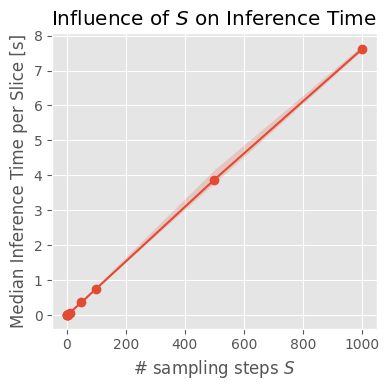

In [48]:
filtered_comparison = beamdiff_ddpm_sampler_comparison #- beamdiff_ddpm_500_pred - beamdiff_ddpm_50_pred - beamdiff_ddpm_5_pred - beamdiff_ddpm_4_pred - beamdiff_ddpm_3_pred - beamdiff_ddpm_2_pred

t_values = []
median_times = []
q25_times = []
q75_times = []
for result, label in zip(filtered_comparison.results_list, filtered_comparison.result_labels):
    t_values.append(int(label.split('=')[1]))
    durations = result.slice_metrics['duration']
    median_times.append(durations.median())
    q25_times.append(durations.quantile(0.25))
    q75_times.append(durations.quantile(0.75))

t_values, median_times, q25_times, q75_times = zip(*sorted(zip(t_values, median_times, q25_times, q75_times)))
median_times = np.array(median_times)
q25_times = np.array(q25_times)
q75_times = np.array(q75_times)

fig, ax = plt.subplots(figsize=(FIG_WIDTH / 3, 4))
ax.plot(t_values, median_times, marker='o')
ax.fill_between(t_values, q25_times, q75_times, alpha=0.2)
ax.set_title('Influence of $S$ on Inference Time')
ax.set_xlabel('# sampling steps $S$')
ax.set_ylabel('Median Inference Time per Slice [s]')
# ax.set_xscale('log')
fig.tight_layout()
plt.savefig('../imgs/pred-beamdiff-s-inference-times.svg', bbox_inches='tight')
plt.show()

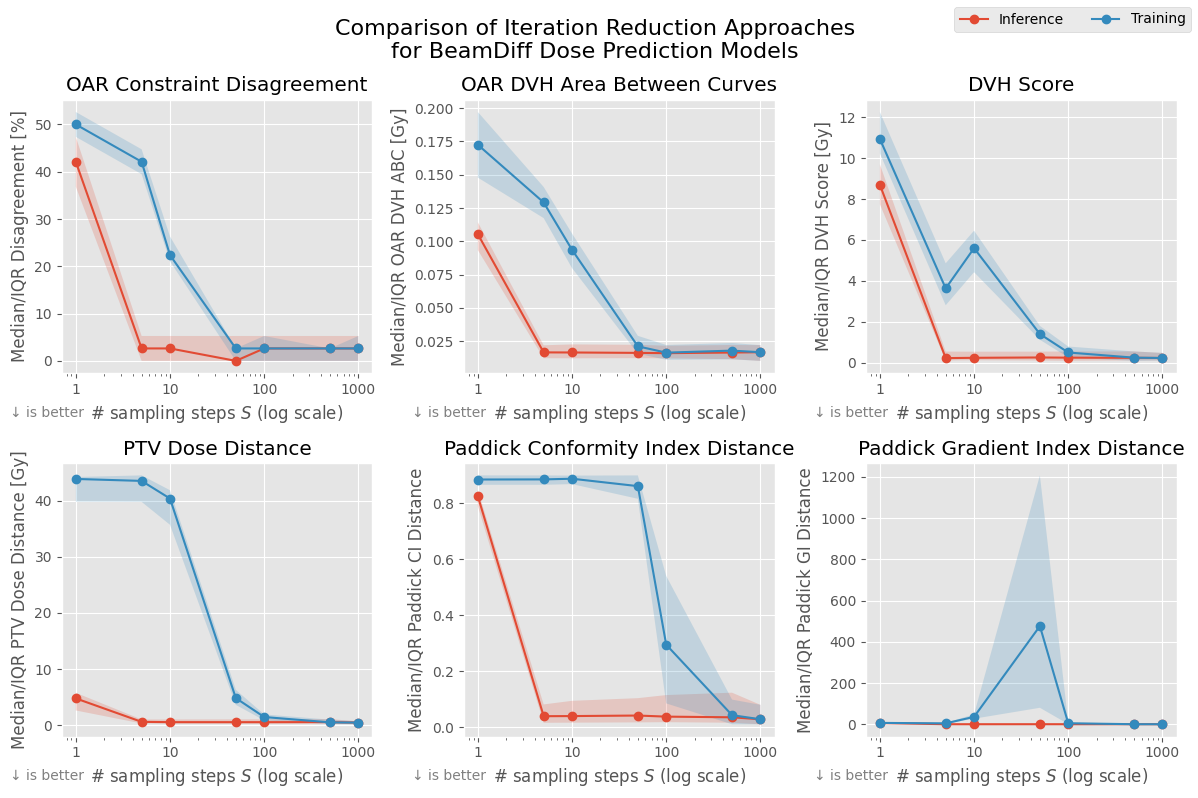

In [49]:
beamdiff_train_ddpm_comparison = ModelComparison(
  [beamdiff_amp_199_pred, beamdiff_ddpm_500_pred, beamdiff_ddpm_100_pred, beamdiff_ddpm_50_pred, beamdiff_ddpm_10_pred, beamdiff_ddpm_5_pred, beamdiff_ddpm_1_pred] +
  [beamdiff_amp_199_pred, beamdiff_train_500_pred, beamdiff_train_100_pred, beamdiff_train_50_pred, beamdiff_train_10_pred, beamdiff_train_5_pred, beamdiff_train_1_pred],
  ['Inference S=1000', 'Inference S=500', 'Inference S=100', 'Inference S=50', 'Inference S=10', 'Inference S=5', 'Inference S=1'] +
  ['Training T=S=1000', 'Training T=S=500', 'Training T=S=100', 'Training T=S=50', 'Training T=S=10', 'Training T=S=5', 'Training T=S=1'],
  ['DDPM-Sampling'] * 7 + ['DDPM-Training'] * 7
)
fig, axes = beamdiff_train_ddpm_comparison.plot_quality_over_T(METRICS_PRED, agg='median', xscale='log')
fig.set_size_inches(FIG_WIDTH, 8)

for ax in axes:
    ax.set_xlabel('# sampling steps $S$ (log scale)')
    ax.set_xticks([1, 10, 100, 1000])

fig.suptitle('Comparison of Iteration Reduction Approaches\nfor BeamDiff Dose Prediction Models')
fig.tight_layout()
plt.savefig('../imgs/pred-beamdiff-training-vs-sampling-metrics.svg', bbox_inches='tight')
plt.show()


In [50]:
beamdiff_ddpm_samp_comparison = ModelComparison(
  [beamdiff_amp_199_pred, beamdiff_ddpm_500_pred, beamdiff_ddpm_100_pred, beamdiff_ddpm_50_pred, beamdiff_ddpm_10_pred, beamdiff_ddpm_5_pred, beamdiff_ddpm_4_pred, beamdiff_ddpm_3_pred, beamdiff_ddpm_2_pred, beamdiff_ddpm_1_pred],
  ['S=1000', 'S=500', 'S=100', 'S=50', 'S=10', 'S=5', 'S=4', 'S=3', 'S=2', 'S=1'],
  ['DDPM'] * 10
)

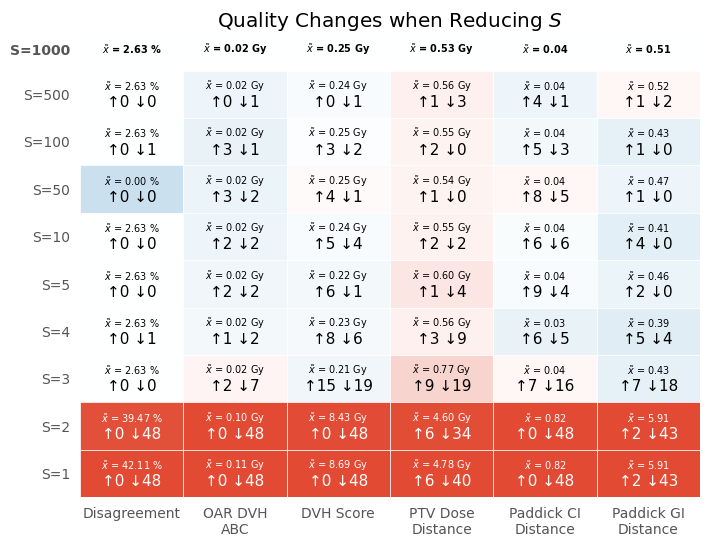

In [51]:
filtered_comparison = beamdiff_ddpm_samp_comparison - beamdiff_amp_199_pred

fig, ax = plt.subplots(figsize=(FIG_WIDTH/3*2, 6))
_ = filtered_comparison.plot_metric_heatmap(
  METRICS_PRED,
  baseline=pred_beamdiff_baseline_comparison,
  improved_q=0.975,
  worsened_q=0.025,
  sort=False,
  baseline_label='S=1000',
  ax=ax
)

ax.set_title('Quality Changes when Reducing $S$')
plt.savefig('../imgs/pred-beamdiff-ddpm-s-heatmap.svg', bbox_inches='tight')
plt.show()

In [52]:
beamdiff_sampler_comparison = ModelComparison(
  [beamdiff_amp_199_pred, beamdiff_ddpm_500_pred, beamdiff_ddpm_100_pred, beamdiff_ddpm_50_pred, beamdiff_ddpm_10_pred, beamdiff_ddpm_5_pred, beamdiff_ddpm_4_pred, beamdiff_ddpm_3_pred, beamdiff_ddpm_2_pred, beamdiff_ddpm_1_pred,
   beamdiff_ddim_1000_pred, beamdiff_ddim_500_pred, beamdiff_ddim_100_pred, beamdiff_ddim_50_pred, beamdiff_ddim_10_pred, beamdiff_ddim_5_pred, beamdiff_ddim_4_pred, beamdiff_ddim_3_pred, beamdiff_ddim_2_pred, beamdiff_ddim_1_pred,
   beamdiff_deis_1_1000_pred, beamdiff_deis_1_500_pred, beamdiff_deis_1_100_pred, beamdiff_deis_1_50_pred, beamdiff_deis_1_10_pred, beamdiff_deis_1_5_pred, beamdiff_deis_1_4_pred, beamdiff_deis_1_3_pred, beamdiff_deis_1_2_pred, beamdiff_deis_1_1_pred,
   beamdiff_deis_2_1000_pred, beamdiff_deis_2_500_pred, beamdiff_deis_2_100_pred, beamdiff_deis_2_50_pred, beamdiff_deis_2_10_pred, beamdiff_deis_2_5_pred, beamdiff_deis_2_4_pred, beamdiff_deis_2_3_pred, beamdiff_deis_2_2_pred, beamdiff_deis_2_1_pred,
   beamdiff_deis_3_1000_pred, beamdiff_deis_3_500_pred, beamdiff_deis_3_100_pred, beamdiff_deis_3_50_pred, beamdiff_deis_3_10_pred, beamdiff_deis_3_5_pred, beamdiff_deis_3_4_pred, beamdiff_deis_3_3_pred, beamdiff_deis_3_2_pred, beamdiff_deis_3_1_pred],
  ['DDPM S=1000', 'DDPM S=500', 'DDPM S=100', 'DDPM S=50', 'DDPM S=10', 'DDPM S=5', 'DDPM S=4', 'DDPM S=3', 'DDPM S=2', 'DDPM S=1',
   'DDIM S=1000', 'DDIM S=500', 'DDIM S=100', 'DDIM S=50', 'DDIM S=10', 'DDIM S=5', 'DDIM S=4', 'DDIM S=3', 'DDIM S=2', 'DDIM S=1',
   'DEIS-1 S=1000', 'DEIS-1 S=500', 'DEIS-1 S=100', 'DEIS-1 S=50', 'DEIS-1 S=10', 'DEIS-1 S=5', 'DEIS-1 S=4', 'DEIS-1 S=3', 'DEIS-1 S=2', 'DEIS-1 S=1',
   'DEIS-2 S=1000', 'DEIS-2 S=500', 'DEIS-2 S=100', 'DEIS-2 S=50', 'DEIS-2 S=10', 'DEIS-2 S=5', 'DEIS-2 S=4', 'DEIS-2 S=3', 'DEIS-2 S=2', 'DEIS-2 S=1',
   'DEIS-3 S=1000', 'DEIS-3 S=500', 'DEIS-3 S=100', 'DEIS-3 S=50', 'DEIS-3 S=10', 'DEIS-3 S=5', 'DEIS-3 S=4', 'DEIS-3 S=3', 'DEIS-3 S=2', 'DEIS-3 S=1'],
  ['DDPM'] * 13 + ['DDIM'] * 13 + ['DEIS-1'] * 13 + ['DEIS-2'] * 13 + ['DEIS-3'] * 13
)

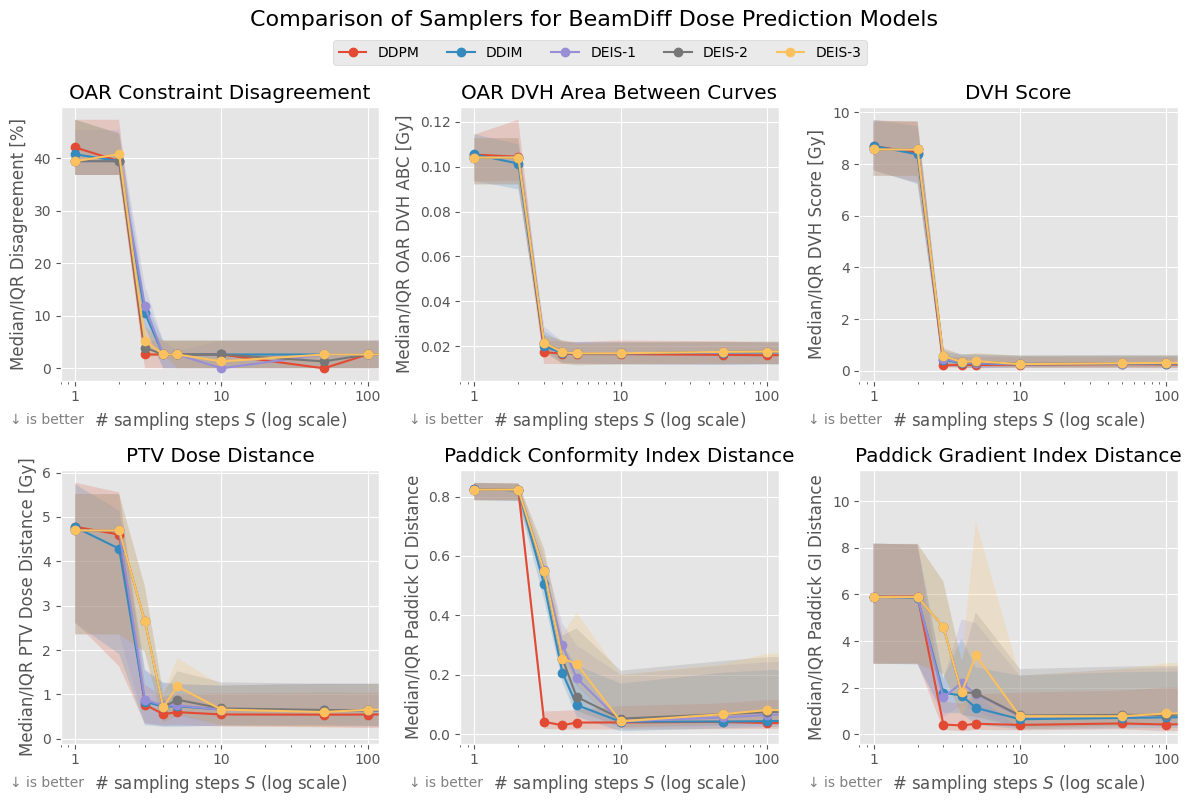

In [53]:
fig, axes = beamdiff_sampler_comparison.plot_quality_over_T(METRICS_PRED, agg='median', xscale='log')
fig.set_size_inches(FIG_WIDTH, 8)

for ax in axes:
    ax.set_xlabel('# sampling steps $S$ (log scale)')
    ax.set_xticks([1, 10, 100, 1000])
    ax.set_xlim(0.8, 120)

fig.suptitle('Comparison of Samplers for BeamDiff Dose Prediction Models', fontsize=16, y=1.0)
legend = fig.legends[0]
legend.set_bbox_to_anchor((0.5, 0.965))
legend.set_loc('upper center')
fig.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig('../imgs/pred-beamdiff-samplers-metrics.svg', bbox_inches='tight')
plt.show()

In [54]:
for result, label in zip(beamdiff_sampler_comparison.results_list, beamdiff_sampler_comparison.result_labels):
    median_duration = result.slice_metrics['duration'].median()
    print(f'{label}: {median_duration:.4f} s')


DDPM S=1000: 7.6064 s
DDPM S=500: 3.8746 s
DDPM S=100: 0.7566 s
DDPM S=50: 0.3706 s
DDPM S=10: 0.0666 s
DDPM S=5: 0.0292 s
DDPM S=4: 0.0217 s
DDPM S=3: 0.0142 s
DDPM S=2: 0.0068 s
DDPM S=1: 0.0007 s
DDIM S=1000: 7.5718 s
DDIM S=500: 3.8230 s
DDIM S=100: 0.7506 s
DDIM S=50: 0.3731 s
DDIM S=10: 0.0689 s
DDIM S=5: 0.0307 s
DDIM S=4: 0.0234 s
DDIM S=3: 0.0158 s
DDIM S=2: 0.0082 s
DDIM S=1: 0.0007 s
DEIS-1 S=1000: 7.7610 s
DEIS-1 S=500: 3.7812 s
DEIS-1 S=100: 0.7591 s
DEIS-1 S=50: 0.3719 s
DEIS-1 S=10: 0.0684 s
DEIS-1 S=5: 0.0310 s
DEIS-1 S=4: 0.0233 s
DEIS-1 S=3: 0.0158 s
DEIS-1 S=2: 0.0083 s
DEIS-1 S=1: 0.0007 s
DEIS-2 S=1000: 7.5795 s
DEIS-2 S=500: 3.8726 s
DEIS-2 S=100: 0.7503 s
DEIS-2 S=50: 0.3711 s
DEIS-2 S=10: 0.0683 s
DEIS-2 S=5: 0.0307 s
DEIS-2 S=4: 0.0234 s
DEIS-2 S=3: 0.0157 s
DEIS-2 S=2: 0.0083 s
DEIS-2 S=1: 0.0007 s
DEIS-3 S=1000: 7.6243 s
DEIS-3 S=500: 3.8877 s
DEIS-3 S=100: 0.7545 s
DEIS-3 S=50: 0.3751 s
DEIS-3 S=10: 0.0683 s
DEIS-3 S=5: 0.0310 s
DEIS-3 S=4: 0.0233 s
DEIS-3 S

In [55]:
beamdiff_ddim_schedule_comparison = ModelComparison(
  [beamdiff_ddim_1000_pred, beamdiff_ddim_500_pred, beamdiff_ddim_100_pred, beamdiff_ddim_50_pred, beamdiff_ddim_10_pred, beamdiff_ddim_5_pred, beamdiff_ddim_4_pred, beamdiff_ddim_3_pred, beamdiff_ddim_2_pred, beamdiff_ddim_1_pred,
   beamdiff_ddim_cosine_1000_pred, beamdiff_ddim_cosine_500_pred, beamdiff_ddim_cosine_100_pred, beamdiff_ddim_cosine_50_pred, beamdiff_ddim_cosine_10_pred, beamdiff_ddim_cosine_5_pred, beamdiff_ddim_cosine_4_pred, beamdiff_ddim_cosine_3_pred, beamdiff_ddim_cosine_2_pred, beamdiff_ddim_cosine_1_pred,
   beamdiff_ddim_karras_1000_pred, beamdiff_ddim_karras_500_pred, beamdiff_ddim_karras_100_pred, beamdiff_ddim_karras_50_pred, beamdiff_ddim_karras_10_pred, beamdiff_ddim_karras_5_pred, beamdiff_ddim_karras_4_pred, beamdiff_ddim_karras_3_pred, beamdiff_ddim_karras_2_pred, beamdiff_ddim_karras_1_pred],
  ['Linear S=1000', 'Linear S=500', 'Linear S=100', 'Linear S=50', 'Linear S=10', 'Linear S=5', 'Linear S=4', 'Linear S=3', 'Linear S=2', 'Linear S=1',
   'Cosine S=1000', 'Cosine S=500', 'Cosine S=100', 'Cosine S=50', 'Cosine S=10', 'Cosine S=5', 'Cosine S=4', 'Cosine S=3', 'Cosine S=2', 'Cosine S=1',
   'Karras S=1000', 'Karras S=500', 'Karras S=100', 'Karras S=50', 'Karras S=10', 'Karras S=5', 'Karras S=4', 'Karras S=3', 'Karras S=2', 'Karras S=1'],
  ['Linear Schedule'] * 10 + ['Cosine Schedule'] * 10 + ['Karras Schedule'] * 10
)

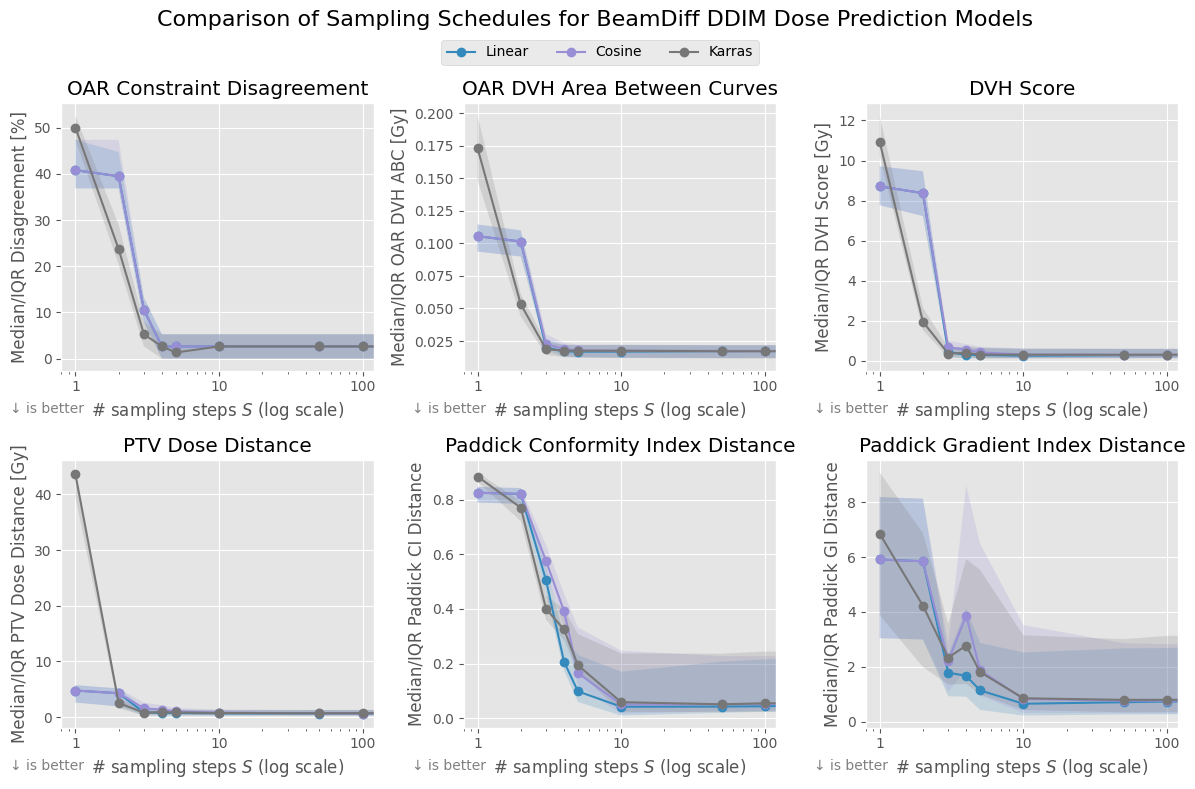

In [56]:
fig, axes = beamdiff_ddim_schedule_comparison.plot_quality_over_T(METRICS_PRED, agg='median', xscale='log', skip_colors=1)
fig.set_size_inches(FIG_WIDTH, 8)

for ax in axes:
    ax.set_xlabel('# sampling steps $S$ (log scale)')
    ax.set_xticks([1, 10, 100, 1000])
    ax.set_xlim(0.8, 120)

fig.suptitle('Comparison of Sampling Schedules for BeamDiff DDIM Dose Prediction Models')
legend = fig.legends[0]
legend.set_bbox_to_anchor((0.5, 0.945))
legend.set_loc('upper center')
fig.tight_layout(rect=[0, 0, 1, 0.955])
plt.savefig('../imgs/pred-beamdiff-schedules-metrics.svg', bbox_inches='tight')
plt.show()

In [57]:
beamdiff_ddpm_distill_comparison = ModelComparison(
  [beamdiff_amp_199_pred, beamdiff_ddpm_500_pred, beamdiff_ddpm_100_pred, beamdiff_ddpm_50_pred, beamdiff_ddpm_10_pred, beamdiff_ddpm_5_pred, beamdiff_ddpm_4_pred, beamdiff_ddpm_3_pred, beamdiff_ddpm_2_pred, beamdiff_ddpm_1_pred,
   beamdiff_distill_ddpm_1024_pred, beamdiff_distill_ddpm_512_pred, beamdiff_distill_ddpm_256_pred, beamdiff_distill_ddpm_128_pred, beamdiff_distill_ddpm_64_pred, beamdiff_distill_ddpm_32_pred, beamdiff_distill_ddpm_16_pred, beamdiff_distill_ddpm_8_pred, beamdiff_distill_ddpm_4_pred, beamdiff_distill_ddpm_2_pred],
  ['DDPM S=1000', 'DDPM S=500', 'DDPM S=100', 'DDPM S=50', 'DDPM S=10', 'DDPM S=5', 'DDPM S=4', 'DDPM S=3', 'DDPM S=2', 'DDPM S=1',
   'Distillation S=1024', 'Distillation S=512', 'Distillation S=256', 'Distillation S=128', 'Distillation S=64', 'Distillation S=32', 'Distillation S=16', 'Distillation S=8', 'Distillation S=4', 'Distillation S=2'],
  ['DDPM'] * 10 + ['Distilled DDPM'] * 10
)

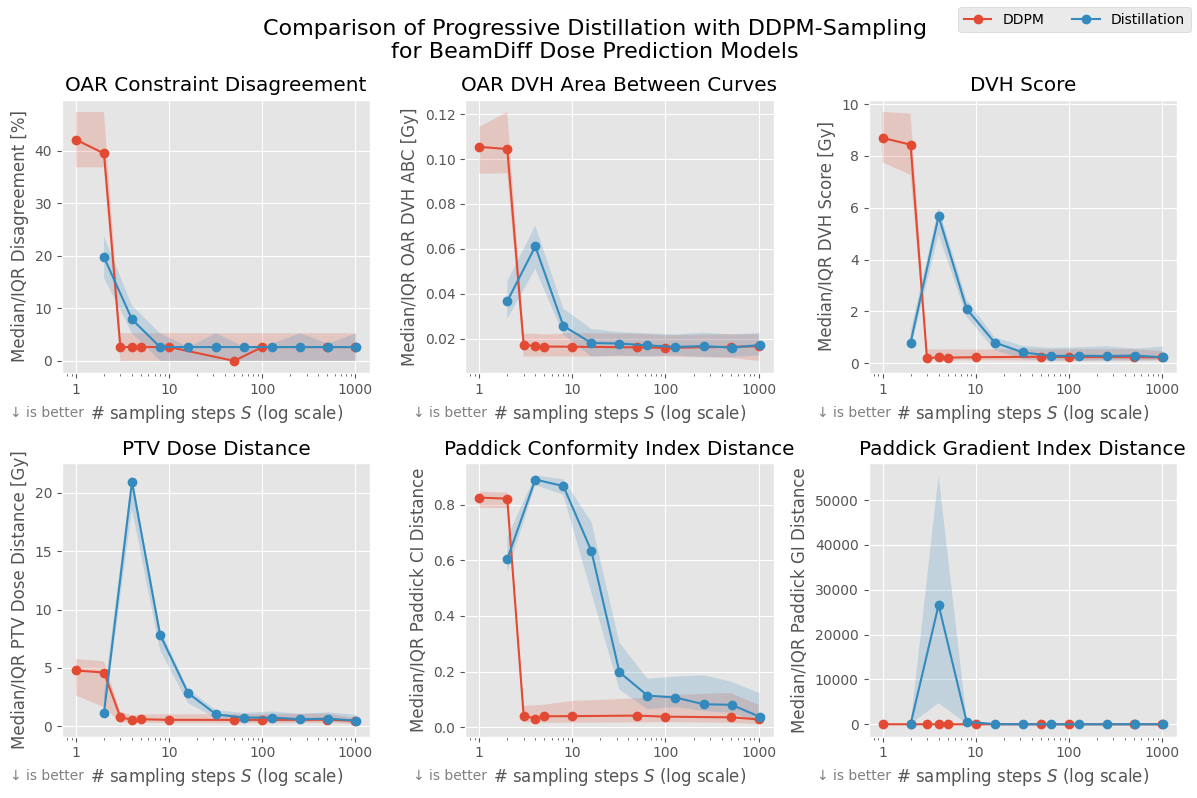

In [58]:
fig, axes = beamdiff_ddpm_distill_comparison.plot_quality_over_T(METRICS_PRED, agg='median', xscale='log')
fig.set_size_inches(FIG_WIDTH, 8)

for ax in axes:
    ax.set_xlabel('# sampling steps $S$ (log scale)')
    ax.set_xticks([1, 10, 100, 1000])

fig.suptitle('Comparison of Progressive Distillation with DDPM-Sampling\nfor BeamDiff Dose Prediction Models')
fig.tight_layout()
plt.savefig('../imgs/pred-beamdiff-ddpm-vs-distill-metrics.svg', bbox_inches='tight')
plt.show()

### Making each step faster

- Caching Heatmaps for all Enc-Levels (Appendix)
- Arch Changes Heatmap
- Channel Heatmap
- Optimised Arch Metrics with U-Net Comparison (Appendix)
- Time Reduction Plot of Optimised Versions

In [59]:
beamdiff_caching_enc1_int3_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc1-interval3-1000', 199, 'test', dataset)
beamdiff_caching_enc1_int5_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc1-interval5-1000', 199, 'test', dataset)
beamdiff_caching_enc1_int10_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc1-interval10-1000', 199, 'test', dataset)
beamdiff_caching_enc1_int20_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc1-interval20-1000', 199, 'test', dataset)
beamdiff_caching_enc1_int50_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc1-interval50-1000', 199, 'test', dataset)
beamdiff_caching_enc1_int100_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc1-interval100-1000', 199, 'test', dataset)
beamdiff_caching_enc1_int200_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc1-interval200-1000', 199, 'test', dataset)
beamdiff_caching_enc1_inf_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc1-1000', 199, 'test', dataset)

beamdiff_caching_enc2_int3_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc2-interval3-1000', 199, 'test', dataset)
beamdiff_caching_enc2_int5_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc2-interval5-1000', 199, 'test', dataset)
beamdiff_caching_enc2_int10_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc2-interval10-1000', 199, 'test', dataset)
beamdiff_caching_enc2_int20_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc2-interval20-1000', 199, 'test', dataset)
beamdiff_caching_enc2_int50_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc2-interval50-1000', 199, 'test', dataset)
beamdiff_caching_enc2_int100_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc2-interval100-1000', 199, 'test', dataset)
beamdiff_caching_enc2_int200_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc2-interval200-1000', 199, 'test', dataset)
beamdiff_caching_enc2_inf_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc2-1000', 199, 'test', dataset)

beamdiff_caching_enc3_int3_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc3-interval3-1000', 199, 'test', dataset)
beamdiff_caching_enc3_int5_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc3-interval5-1000', 199, 'test', dataset)
beamdiff_caching_enc3_int10_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc3-interval10-1000', 199, 'test', dataset)
beamdiff_caching_enc3_int20_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc3-interval20-1000', 199, 'test', dataset)
beamdiff_caching_enc3_int50_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc3-interval50-1000', 199, 'test', dataset)
beamdiff_caching_enc3_int100_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc3-interval100-1000', 199, 'test', dataset)
beamdiff_caching_enc3_int200_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc3-interval200-1000', 199, 'test', dataset)
beamdiff_caching_enc3_inf_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc3-1000', 199, 'test', dataset)

beamdiff_caching_enc4_int3_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc4-interval3-1000', 199, 'test', dataset)
beamdiff_caching_enc4_int5_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc4-interval5-1000', 199, 'test', dataset)
beamdiff_caching_enc4_int10_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc4-interval10-1000', 199, 'test', dataset)
beamdiff_caching_enc4_int20_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc4-interval20-1000', 199, 'test', dataset)
beamdiff_caching_enc4_int50_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc4-interval50-1000', 199, 'test', dataset)
beamdiff_caching_enc4_int100_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc4-interval100-1000', 199, 'test', dataset)
beamdiff_caching_enc4_int200_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc4-interval200-1000', 199, 'test', dataset)
beamdiff_caching_enc4_inf_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc4-1000', 199, 'test', dataset)

beamdiff_caching_enc5_int3_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc5-interval3-1000', 199, 'test', dataset)
beamdiff_caching_enc5_int5_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc5-interval5-1000', 199, 'test', dataset)
beamdiff_caching_enc5_int10_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc5-interval10-1000', 199, 'test', dataset)
beamdiff_caching_enc5_int20_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc5-interval20-1000', 199, 'test', dataset)
beamdiff_caching_enc5_int50_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc5-interval50-1000', 199, 'test', dataset)
beamdiff_caching_enc5_int100_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc5-interval100-1000', 199, 'test', dataset)
beamdiff_caching_enc5_int200_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc5-interval200-1000', 199, 'test', dataset)
beamdiff_caching_enc5_inf_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc5-1000', 199, 'test', dataset)

beamdiff_caching_optimised_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc2-interval5-20-200-inf-1000', 199, 'test', dataset)
beamdiff_caching_optimised2_pred = ModelResults('112-beamdiff-bf16', 'ddpm-cache-beamdiff-enc2-interval5-20-200-200-1000', 199, 'test', dataset)

In [60]:
beamdiff_caching_optimised_comparison = ModelComparison(
  [beamdiff_amp_199_pred, beamdiff_caching_optimised_pred, beamdiff_caching_optimised2_pred, deeplabv3plus_199_pred],
  ['BeamDiff\nBaseline', 'BeamDiff\nOptimised', 'BeamDiff\nOptimised', 'DeepLabv3+'],
  ['DDPM'] * 3 + ['U-Net']
)

/Users/joseph.weibel@fhnw.ch/dev/dose-prediction-thesis/.venv/lib/python3.13/site-packages/numpy/lib/_nanfunctions_impl.py:1214: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


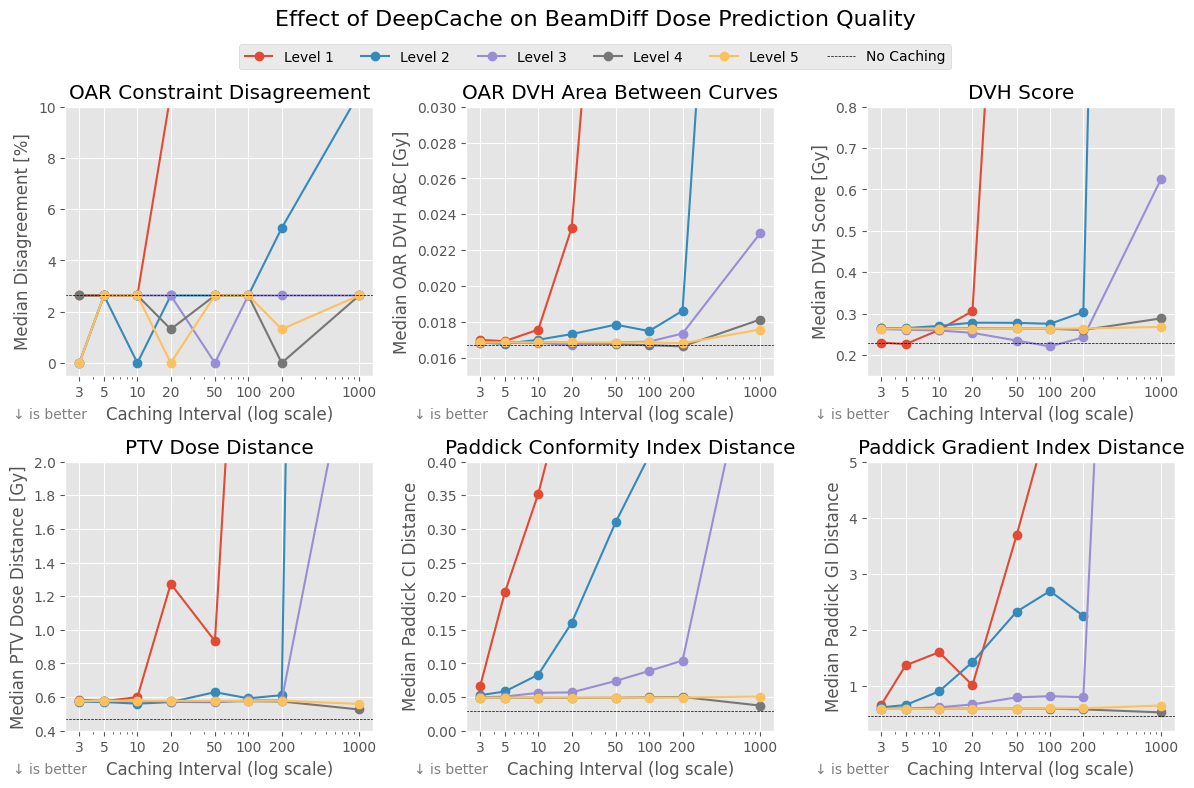

In [61]:

# Organize caching results by encoder level
caching_by_encoder = {
    'Level 1': [
        (3, beamdiff_caching_enc1_int3_pred),
        (5, beamdiff_caching_enc1_int5_pred),
        (10, beamdiff_caching_enc1_int10_pred),
        (20, beamdiff_caching_enc1_int20_pred),
        (50, beamdiff_caching_enc1_int50_pred),
        (100, beamdiff_caching_enc1_int100_pred),
        (200, beamdiff_caching_enc1_int200_pred),
        (1000, beamdiff_caching_enc1_inf_pred),
    ],
    'Level 2': [
        (3, beamdiff_caching_enc2_int3_pred),
        (5, beamdiff_caching_enc2_int5_pred),
        (10, beamdiff_caching_enc2_int10_pred),
        (20, beamdiff_caching_enc2_int20_pred),
        (50, beamdiff_caching_enc2_int50_pred),
        (100, beamdiff_caching_enc2_int100_pred),
        (200, beamdiff_caching_enc2_int200_pred),
        (1000, beamdiff_caching_enc2_inf_pred),
    ],
    'Level 3': [
        (3, beamdiff_caching_enc3_int3_pred),
        (5, beamdiff_caching_enc3_int5_pred),
        (10, beamdiff_caching_enc3_int10_pred),
        (20, beamdiff_caching_enc3_int20_pred),
        (50, beamdiff_caching_enc3_int50_pred),
        (100, beamdiff_caching_enc3_int100_pred),
        (200, beamdiff_caching_enc3_int200_pred),
        (1000, beamdiff_caching_enc3_inf_pred),
    ],
    'Level 4': [
        (3, beamdiff_caching_enc4_int3_pred),
        (5, beamdiff_caching_enc4_int5_pred),
        (10, beamdiff_caching_enc4_int10_pred),
        (20, beamdiff_caching_enc4_int20_pred),
        (50, beamdiff_caching_enc4_int50_pred),
        (100, beamdiff_caching_enc4_int100_pred),
        (200, beamdiff_caching_enc4_int200_pred),
        (1000, beamdiff_caching_enc4_inf_pred),
    ],
    'Level 5': [
        (3, beamdiff_caching_enc5_int3_pred),
        (5, beamdiff_caching_enc5_int5_pred),
        (10, beamdiff_caching_enc5_int10_pred),
        (20, beamdiff_caching_enc5_int20_pred),
        (50, beamdiff_caching_enc5_int50_pred),
        (100, beamdiff_caching_enc5_int100_pred),
        (200, beamdiff_caching_enc5_int200_pred),
        (1000, beamdiff_caching_enc5_inf_pred),
    ],
}

fig, axes = setup_fig_axes(METRICS_PRED)
fig.set_size_inches(FIG_WIDTH, 8)

for metric, ax in zip(METRICS_PRED, axes):
    for enc_label, entries in caching_by_encoder.items():
        xs, ys, y_los, y_his = [], [], [], []
        for interval, result in entries:
            df = result.volume_metrics
            y = df[metric].median()
            y_lo = df[metric].quantile(0.25)
            y_hi = df[metric].quantile(0.75)
            xs.append(interval)
            ys.append(y)
            y_los.append(y_lo)
            y_his.append(y_hi)

        ax.plot(xs, ys, marker='o', label=enc_label)
        # ax.fill_between(xs, y_los, y_his, alpha=0.2)

    # Add baseline (no caching)
    y_base = beamdiff_amp_199_pred.volume_metrics[metric].median()
    ax.axhline(y_base, color='black', linestyle='--', linewidth=0.5, label='No Caching')

    dir_symbol = '↑' if is_higher_better(metric) else '↓'
    ax.set_title(get_metric_label(metric))
    ax.text(0.1, -0.17, f'{dir_symbol} is better  ', transform=ax.transAxes,
            ha='right', va='bottom', fontsize='medium', color='gray')
    ax.set_xlabel('Caching Interval (log scale)')
    ax.set_xscale('log')
    ax.set_xticks([3, 5, 10, 20, 50, 100, 200, 1000])
    ax.xaxis.set_major_formatter(plt.ScalarFormatter())
    ax.set_ylabel(f'Median {get_metric_abbr(metric)}')

axes[0].set_ylim(-0.5, 10)
axes[1].set_ylim(0.015, 0.03)
axes[2].set_ylim(0.15, 0.8)
axes[3].set_ylim(0.4, 2)
axes[4].set_ylim(0, 0.4)
axes[5].set_ylim(0.2, 5)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.945), ncol=6)
fig.suptitle('Effect of DeepCache on BeamDiff Dose Prediction Quality')
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('../imgs/pred-beamdiff-caching-interval-metrics.svg', bbox_inches='tight')
plt.show()


1 -> no caching
2 -> 5
3 -> 20
4 -> 200
5 -> inf



In [62]:
# beamdiff_no_mam_pred = ModelResults('120-no-mam', 'ddpm-1000', 199, 'test', dataset)
beamdiff_no_afm_pred = ModelResults('121-no-afm', 'ddpm-1000', 199, 'test', dataset)
beamdiff_no_self_attn_pred = ModelResults('122-no-self-attn', 'ddpm-1000', 199, 'test', dataset)
beamdiff_base_channels_64_pred = ModelResults('123-base-channels-64', 'ddpm-1000', 199, 'test', dataset)
beamdiff_res_blocks_1_pred = ModelResults('124-res-blocks-1', 'ddpm-1000', 199, 'test', dataset)
beamdiff_channels_1123_pred = ModelResults('126-channels-1123', 'ddpm-1000', 199, 'test', dataset)
beamdiff_channels_11223_pred = ModelResults('128-channels-11223', 'ddpm-1000', 199, 'test', dataset)
beamdiff_channels_11123_pred = ModelResults('129-channels-11123', 'ddpm-1000', 199, 'test', dataset)
beamdiff_channels_11122_pred = ModelResults('130-channels-11122', 'ddpm-1000', 199, 'test', dataset)
beamdiff_merged_encoders_pred = ModelResults('131-merged-encoders', 'ddpm-1000', 199, 'test', dataset)
beamdiff_optimised_arch_pred = ModelResults('134-optimised-arch', 'ddpm-1000', 199, 'test', dataset)
beamdiff_optimised_arch2_pred = ModelResults('135-optimised-arch-2', 'ddpm-1000', 199, 'test', dataset)

In [63]:
beamdiff_arch_changes_comparison = ModelComparison(
  [beamdiff_no_afm_pred, beamdiff_no_self_attn_pred, beamdiff_base_channels_64_pred, beamdiff_res_blocks_1_pred, beamdiff_merged_encoders_pred],
  ['without AFM', 'without Encoder\nSelf-Attention', '64 Base\nChannels', 'Single\nResidual Block', 'Merged\nEncoder'],
  ['DDPM'] * 6
)

beamdiff_arch_channels_comparison = ModelComparison(
  [beamdiff_channels_1123_pred, beamdiff_channels_11223_pred, beamdiff_channels_11123_pred, beamdiff_channels_11122_pred],
  ['1123', '11223', '11123', '11122'],
  ['DDPM'] * 4
)

beamdiff_arch_optimisation_comparison = ModelComparison(
  [beamdiff_amp_199_pred, beamdiff_optimised_arch2_pred, deeplabv3plus_199_pred],
  ['BeamDiff\nBaseline', 'BeamDiff\nOptimised', 'DeepLabv3+'],
  ['DDPM'] * 2 + ['U-Net']
)

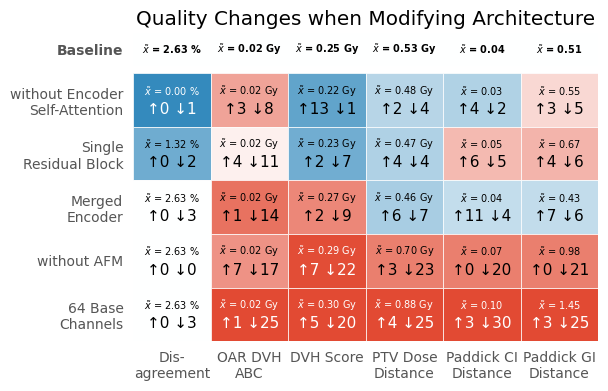

In [64]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH/2, 4))

_ = beamdiff_arch_changes_comparison.plot_metric_heatmap(
  METRICS_PRED,
  baseline=pred_beamdiff_baseline_comparison,
  improved_q=0.975,
  worsened_q=0.025,
  sort=True,
  baseline_label='Baseline',
  ax=ax,
)

ax.set_title('Quality Changes when Modifying Architecture')
xticklabels = ax.get_xticklabels()
xticklabels[0].set_text('Dis-\nagreement')
ax.set_xticklabels(xticklabels)
plt.savefig('../imgs/pred-beamdiff-arch-changes-heatmap.svg', bbox_inches='tight')
plt.show()

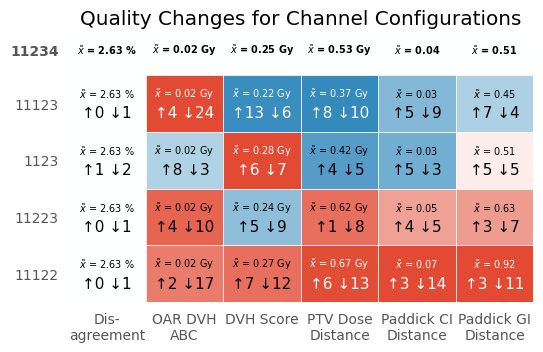

In [65]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH/2, 3.5))

_ = beamdiff_arch_channels_comparison.plot_metric_heatmap(
  METRICS_PRED,
  baseline=pred_beamdiff_baseline_comparison,
  improved_q=0.975,
  worsened_q=0.025,
  sort=True,
  baseline_label='11234',
  ax=ax,
)

ax.set_title('Quality Changes for Channel Configurations')
xticklabels = ax.get_xticklabels()
xticklabels[0].set_text('Dis-\nagreement')
ax.set_xticklabels(xticklabels)
plt.savefig('../imgs/pred-beamdiff-channel-changes-heatmap.svg', bbox_inches='tight')
plt.show()

In [66]:
beamdiff_step_optimization_comparison = ModelComparison(
  [beamdiff_amp_199_pred, beamdiff_optimised_arch2_pred, beamdiff_caching_optimised_pred, deeplabv3plus_199_pred],
  ['Baseline', 'Architecture\nOptimised', 'Caching\nOptimised', 'DeepLabv3+'],
  ['DDPM'] * 3 + ['U-Net']
)

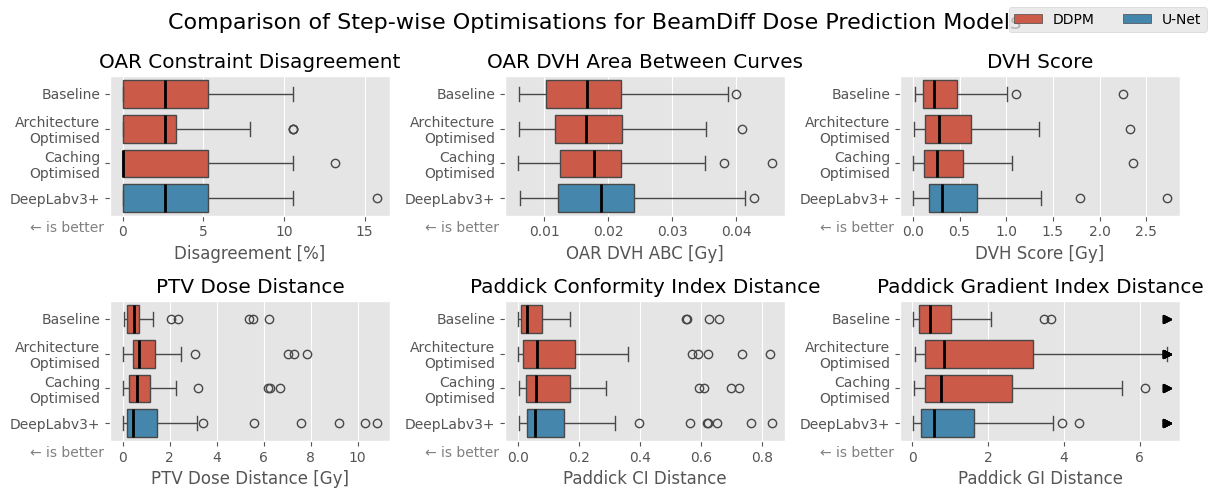

In [67]:
fig, axes = beamdiff_step_optimization_comparison.plot_metric_distributions(METRICS_PRED, sort=False, outliers=METRICS_PRED[0:5])

fig.set_size_inches(FIG_WIDTH, 5)
fig.tight_layout()
fig.suptitle("Comparison of Step-wise Optimisations for BeamDiff Dose Prediction Models")
plt.savefig('../imgs/pred-beamdiff-step-opt-metrics.svg', bbox_inches='tight')
plt.show()

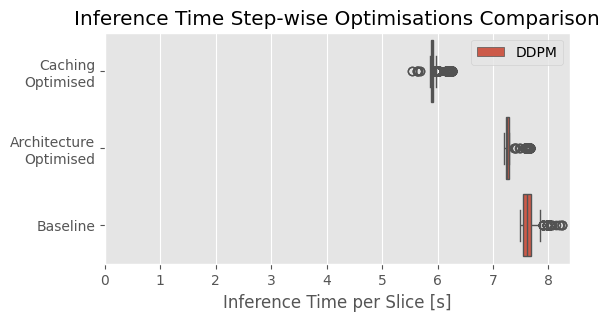

In [68]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH / 2, 3))
(beamdiff_step_optimization_comparison - deeplabv3plus_199_pred).plot_inference_times('slice', 'seconds', ax=ax)
ax.set_xlim(0)
ax.set_title('Inference Time Step-wise Optimisations Comparison')
ax.set_xlabel('Inference Time per Slice [s]')
plt.savefig('../imgs/pred-beamdiff-step-opt-inference-times.svg', bbox_inches='tight')
plt.show()

In [69]:
for result, label in zip(beamdiff_step_optimization_comparison.results_list, beamdiff_step_optimization_comparison.result_labels):
    median_duration = result.slice_metrics['duration'].median()
    print(f'{label}: {median_duration:.4f} s')


Baseline: 7.6064 s
Architecture
Optimised: 7.2537 s
Caching
Optimised: 5.9048 s
DeepLabv3+: 0.0002 s


In [70]:
arch_variant_sizes = pd.Series({
  'Baseline': 80201345,
  # 'without MAM': 80201345,
  'without AFM': 73183361,
  'without Self-Attention\nEncoder': 77832833,
  '64 Base Channels': 20083521,
  'Single Residual Block': 52051073,
  '1123x Channels': 40817665,
  '11223x Channels': 51970305,
  '11123x Channels': 43082881,
  '11122x Channels': 33539969,
  'Merged Encoders': 59219329,
  # '134-optimised-arch': 25027585,
  'Optimised Architecture': 38449153,
})

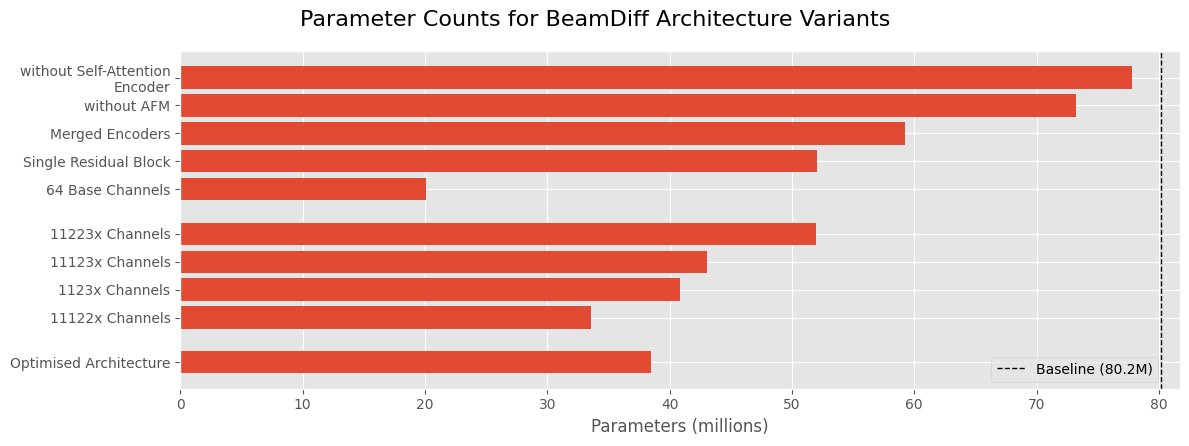

In [71]:
baseline = arch_variant_sizes['Baseline']

channel_keys = ['1123x Channels', '11223x Channels', '11123x Channels', '11122x Channels']
optimised_keys = ['Optimised Architecture']
other_keys = [k for k in arch_variant_sizes.index if k != 'Baseline' and k not in channel_keys and k not in optimised_keys]

groups = [
    arch_variant_sizes[other_keys].sort_values(ascending=False),
    arch_variant_sizes[channel_keys].sort_values(ascending=False),
    arch_variant_sizes[optimised_keys],
]

gap = 0.6
y_positions = []
labels = []
values = []
pos = 0
for i, group in enumerate(groups):
    if i > 0:
        pos += gap
    for label, val in group.items():
        y_positions.append(pos)
        labels.append(label)
        values.append(val / 1e6)
        pos += 1

fig, ax = plt.subplots(figsize=(FIG_WIDTH, 4.5))
ax.barh(y_positions, values)
ax.axvline(baseline / 1e6, color='black', linestyle='--', linewidth=1, label=f'Baseline ({baseline / 1e6:.1f}M)')
fig.suptitle('Parameter Counts for BeamDiff Architecture Variants')
ax.set_yticks(y_positions)
ax.set_yticklabels(labels)
ax.set_xlabel('Parameters (millions)')
ax.legend(loc='lower right', bbox_to_anchor=(0.985, 0))
ax.invert_yaxis()
fig.tight_layout()
plt.savefig('../imgs/pred-beamdiff-arch-changes-params.svg', bbox_inches='tight')
plt.show()

### RFM

In [72]:
beamdiff_flow_1000_pred = ModelResults('140-rfm', 'flow-1000', 199, 'test', dataset)
beamdiff_flow_500_pred = ModelResults('140-rfm', 'flow-500', 199, 'test', dataset)
beamdiff_flow_100_pred = ModelResults('140-rfm', 'flow-100', 199, 'test', dataset)
beamdiff_flow_50_pred = ModelResults('140-rfm', 'flow-50', 199, 'test', dataset)
beamdiff_flow_10_pred = ModelResults('140-rfm', 'flow-10', 199, 'test', dataset)
beamdiff_flow_5_pred = ModelResults('140-rfm', 'flow-5', 199, 'test', dataset)
beamdiff_flow_4_pred = ModelResults('140-rfm', 'flow-4', 199, 'test', dataset)
beamdiff_flow_3_pred = ModelResults('140-rfm', 'flow-3', 199, 'test', dataset)
beamdiff_flow_2_pred = ModelResults('140-rfm', 'flow-2', 199, 'test', dataset)
beamdiff_flow_1_pred = ModelResults('140-rfm', 'flow-1', 199, 'test', dataset)

In [73]:
beamdiff_flow_comparison = ModelComparison(
  [beamdiff_flow_1000_pred, beamdiff_flow_500_pred, beamdiff_flow_100_pred, beamdiff_flow_50_pred, beamdiff_flow_10_pred, beamdiff_flow_5_pred, beamdiff_flow_4_pred, beamdiff_flow_3_pred, beamdiff_flow_2_pred, beamdiff_flow_1_pred],
  ['S=1000', 'S=500', 'S=100', 'S=50', 'S=10', 'S=5', 'S=4', 'S=3', 'S=2', 'S=1'],
  ['RFM'] * 10
)

In [74]:
beamdiff_ddpm_flow_comparison = ModelComparison(
  [beamdiff_amp_199_pred, beamdiff_ddpm_500_pred, beamdiff_ddpm_100_pred, beamdiff_ddpm_50_pred, beamdiff_ddpm_10_pred, beamdiff_ddpm_5_pred, beamdiff_ddpm_4_pred, beamdiff_ddpm_3_pred, beamdiff_ddpm_2_pred, beamdiff_ddpm_1_pred,
   beamdiff_flow_1000_pred, beamdiff_flow_500_pred, beamdiff_flow_100_pred, beamdiff_flow_50_pred, beamdiff_flow_10_pred, beamdiff_flow_5_pred, beamdiff_flow_4_pred, beamdiff_flow_3_pred, beamdiff_flow_2_pred, beamdiff_flow_1_pred],
  ['DDPM S=1000', 'DDPM S=500', 'DDPM S=100', 'DDPM S=50', 'DDPM S=10', 'DDPM S=5', 'DDPM S=4', 'DDPM S=3', 'DDPM S=2', 'DDPM S=1',
   'RFM S=1000', 'RFM S=500', 'RFM S=100', 'RFM S=50', 'RFM S=10', 'RFM S=5', 'RFM S=4', 'RFM S=3', 'RFM S=2', 'RFM S=1'],
  ['DDPM'] * 10 + ['Flow'] * 10
)

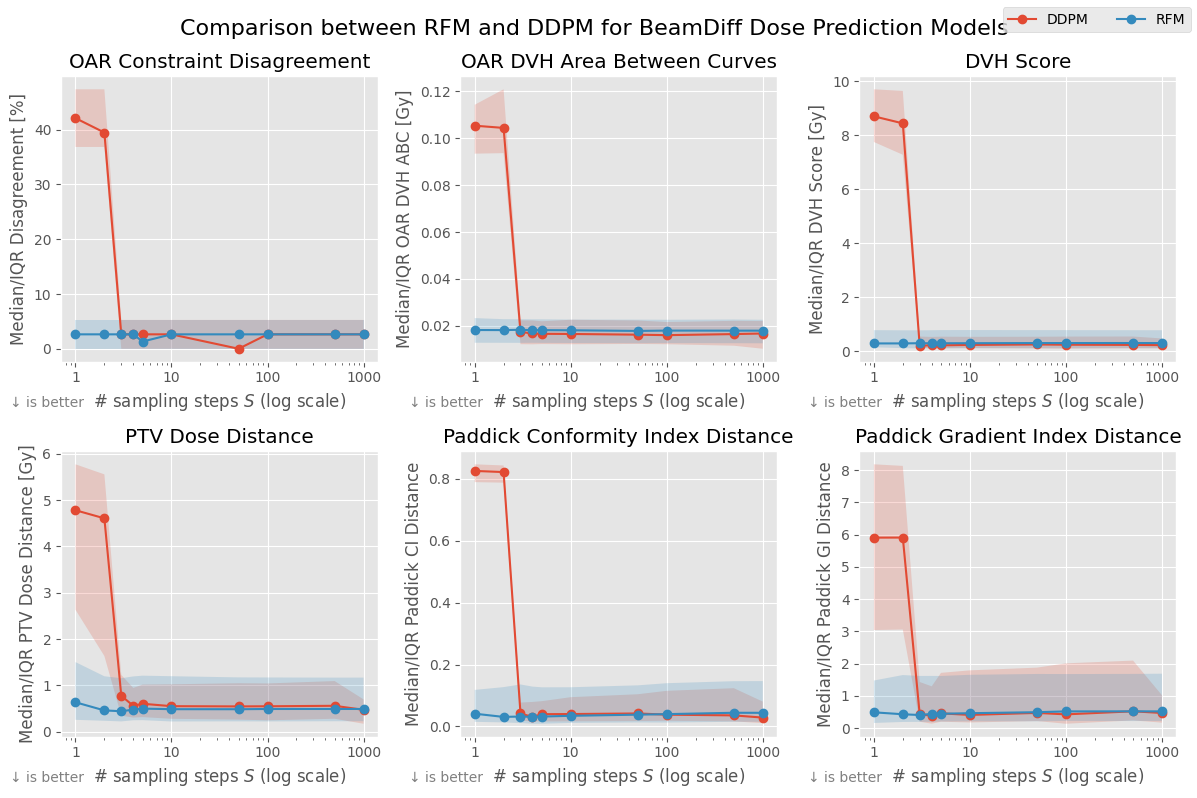

In [75]:
fig, axes = beamdiff_ddpm_flow_comparison.plot_quality_over_T(METRICS_PRED, agg='median', xscale='log')
fig.set_size_inches(FIG_WIDTH, 8)

for ax in axes:
    ax.set_xlabel('# sampling steps $S$ (log scale)')
    ax.set_xticks([1, 10, 100, 1000])

fig.suptitle('Comparison between RFM and DDPM for BeamDiff Dose Prediction Models')
fig.tight_layout()
plt.savefig('../imgs/pred-beamdiff-rfm-metrics.svg', bbox_inches='tight')
plt.show()

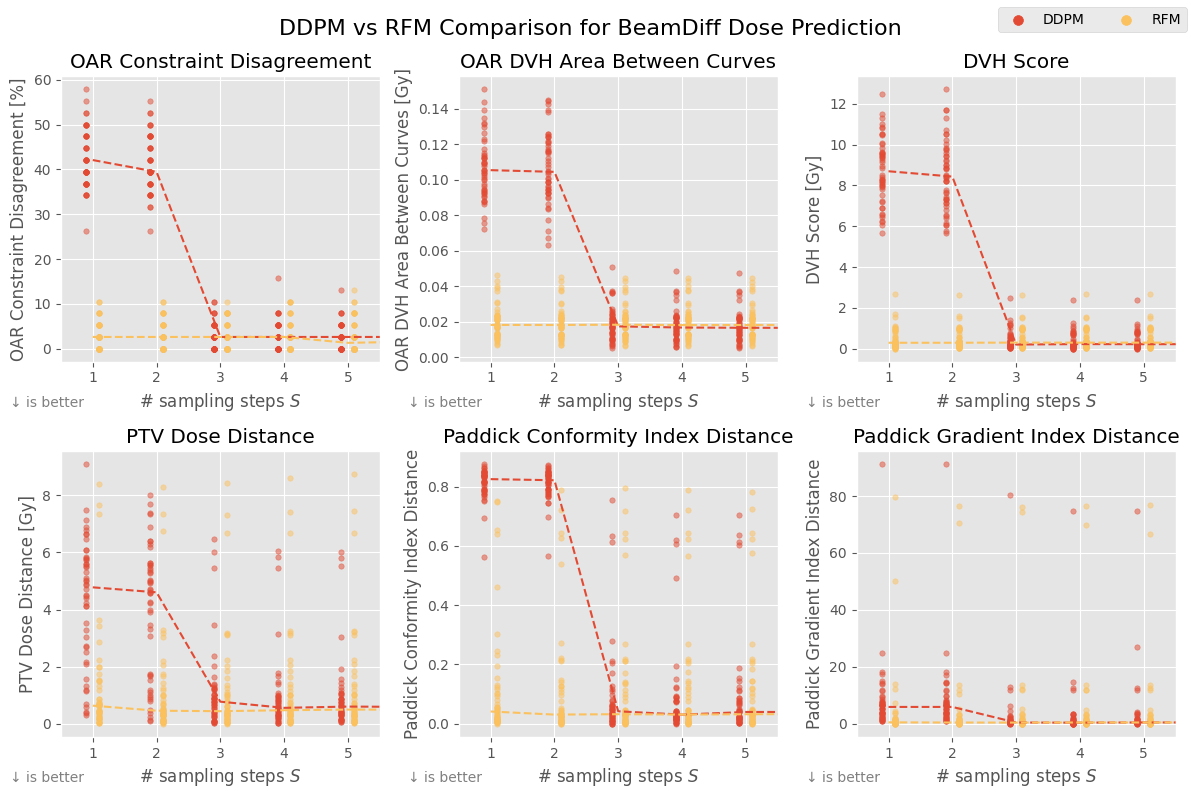

In [76]:
# Scatter plots: quality over S, DDPM vs RFM
import copy
vm = beamdiff_ddpm_flow_comparison.volume_metrics.copy()

vm['method'] = vm['label'].str.extract(r'^(DDPM|RFM)')[0]
vm['steps'] = vm['label'].str.extract(r'S=(\d+)')[0].astype(int)

# Compute medians per method and step count
medians = vm.groupby(['method', 'steps']).median(numeric_only=True)

n_metrics = len(METRICS_PRED)
n_cols = min(3, n_metrics)
n_rows = (n_metrics + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(FIG_WIDTH, 8), squeeze=False)
axes = axes.flatten()

for i, metric in enumerate(METRICS_PRED):
    ax = axes[i]

    for method, color, jitter_sign in [('DDPM', 'C0', -1), ('RFM', '#FBC15E', 1)]:
        subset = vm[vm['method'] == method]
        jittered_steps = subset['steps'] + jitter_sign * 0.1
        ax.scatter(jittered_steps, subset[metric], s=15, alpha=0.5, marker='o', c=color, label=method if i == 0 else None)

        # Median line
        med = medians.loc[method].sort_index()
        ax.plot(med.index, med[metric], color=color, linewidth=1.5, alpha=1, linestyle='dashed')

    ax.set_xlabel('# sampling steps $S$')
    ax.set_xlim(0.5, 5.5)
    ax.set_xticks(range(1, 6))

    unit = get_metric_unit(metric)
    unit_suffix = f' [{unit}]' if unit else ''
    ax.set_ylabel(f'{get_metric_label(metric)}{unit_suffix}')
    ax.set_title(get_metric_label(metric))

    dir_symbol = '↑' if is_higher_better(metric) else '↓'
    ax.text(0.1, -0.17, f'{dir_symbol} is better  ', transform=ax.transAxes,
            ha='right', va='bottom', fontsize='medium', color='gray')

# Hide unused axes
for j in range(n_metrics, len(axes)):
    axes[j].set_visible(False)

handles, labels = axes[0].get_legend_handles_labels()
legend_handles = [copy.copy(h) for h in handles]
for h in legend_handles:
    h.set_alpha(1)
    h.set_sizes([50])
fig.legend(legend_handles, labels, loc='upper right', title='', ncol=2)
fig.suptitle('DDPM vs RFM Comparison for BeamDiff Dose Prediction')
fig.tight_layout()
plt.savefig('../imgs/pred-beamdiff-ddpm-flow-volumes.svg', bbox_inches='tight')
plt.show()

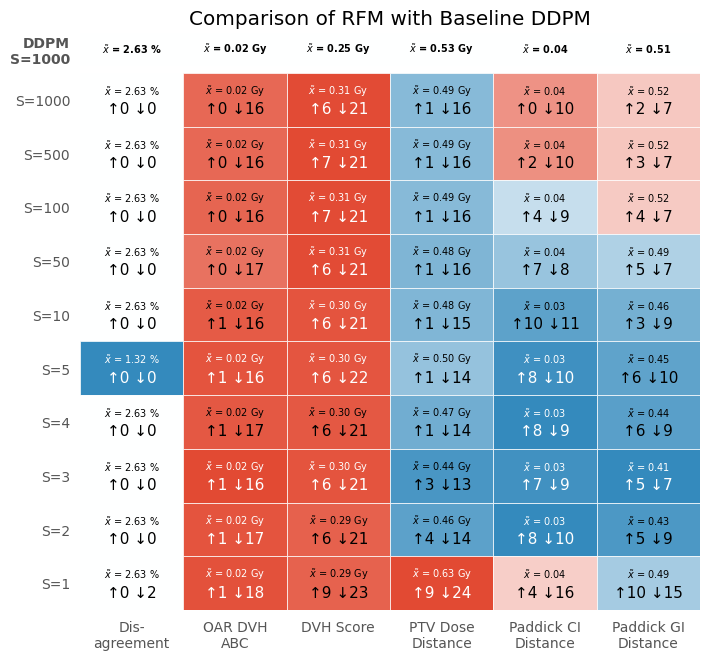

In [77]:
fig, ax = plt.subplots(figsize=(FIG_WIDTH/3*2, 7.5))
_ = beamdiff_flow_comparison.plot_metric_heatmap(
  METRICS_PRED,
  baseline=pred_beamdiff_baseline_comparison,
  improved_q=0.975,
  worsened_q=0.025,
  sort=False,
  baseline_label='DDPM\nS=1000',
  ax=ax,
)

ax.set_title('Comparison of RFM with Baseline DDPM')
xticklabels = ax.get_xticklabels()
xticklabels[0].set_text('Dis-\nagreement')
ax.set_xticklabels(xticklabels)
plt.savefig('../imgs/pred-beamdiff-flow-heatmap.svg', bbox_inches='tight')
plt.show()

In [78]:
beamdiff_amp_199_pred.volume_metrics['vol_mean_dose/high/abs_diff'].median()

np.float64(0.47035980224609375)

### Hybrid

- WS-Unet vs. Classic Unet (Appendix)
- WSD vs. DDPM
- WSFM vs. RFM
- InDI vs. WSD and WSFM (Appendix)
- WSD vs. DDPM Analytical Dose (Appendix)
- WSFM vs. RFM Analytical Dose (Appendix)
- Heatmap of Selection
- Example: which pixels have changed
- count voxel differences

+ LSDR

In [79]:
deeplabv3plus_ws_pred = ModelResults('132-warmstart-deeplabv3plus', 'warm-start-unet', 199, 'test', dataset)

In [80]:
deeplabv3plus_ws_comparison = ModelComparison(
  [deeplabv3plus_199_pred, deeplabv3plus_ws_pred],
  ['L2', 'Gaussian NLL'],
  ['U-Net'] * 2
)

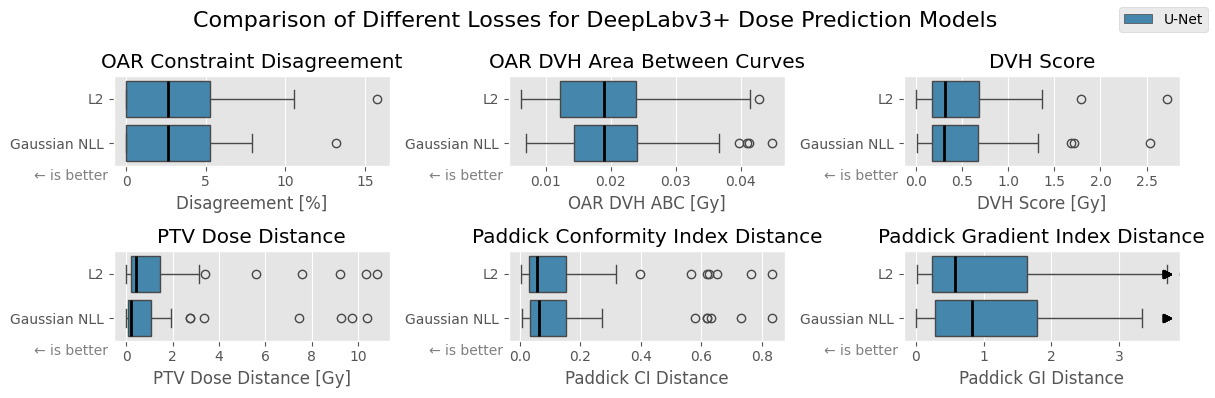

In [81]:
fig, axes = deeplabv3plus_ws_comparison.plot_metric_distributions(METRICS_PRED, sort=False, outliers=METRICS_PRED[0:5], skip_colors=1)

fig.set_size_inches(FIG_WIDTH, 4)
fig.tight_layout()
fig.suptitle("Comparison of Different Losses for DeepLabv3+ Dose Prediction Models")
plt.savefig('../imgs/pred-deeplabv3plus-ws-metrics.svg', bbox_inches='tight')
plt.show()

In [82]:
beamdiff_wsd_ddpm_1000_pred = ModelResults('133-wsd', 'ddpm-1000', 199, 'test', dataset)
beamdiff_wsd_ddpm_500_pred = ModelResults('133-wsd', 'ddpm-500', 199, 'test', dataset)
beamdiff_wsd_ddpm_100_pred = ModelResults('133-wsd', 'ddpm-100', 199, 'test', dataset)
beamdiff_wsd_ddpm_50_pred = ModelResults('133-wsd', 'ddpm-50', 199, 'test', dataset)
beamdiff_wsd_ddpm_10_pred = ModelResults('133-wsd', 'ddpm-10', 199, 'test', dataset)
beamdiff_wsd_ddpm_5_pred = ModelResults('133-wsd', 'ddpm-5', 199, 'test', dataset)
beamdiff_wsd_ddpm_4_pred = ModelResults('133-wsd', 'ddpm-4', 199, 'test', dataset)
beamdiff_wsd_ddpm_3_pred = ModelResults('133-wsd', 'ddpm-3', 199, 'test', dataset)
beamdiff_wsd_ddpm_2_pred = ModelResults('133-wsd', 'ddpm-2', 199, 'test', dataset)
beamdiff_wsd_ddpm_1_pred = ModelResults('133-wsd', 'ddpm-1', 199, 'test', dataset)

In [83]:
beamdiff_ddpm_wsd_comparison = ModelComparison(
  [beamdiff_amp_199_pred, beamdiff_ddpm_500_pred, beamdiff_ddpm_100_pred, beamdiff_ddpm_50_pred, beamdiff_ddpm_10_pred, beamdiff_ddpm_5_pred, beamdiff_ddpm_4_pred, beamdiff_ddpm_3_pred, beamdiff_ddpm_2_pred, beamdiff_ddpm_1_pred,
   beamdiff_wsd_ddpm_1000_pred, beamdiff_wsd_ddpm_500_pred, beamdiff_wsd_ddpm_100_pred, beamdiff_wsd_ddpm_50_pred, beamdiff_wsd_ddpm_10_pred, beamdiff_wsd_ddpm_5_pred, beamdiff_wsd_ddpm_4_pred, beamdiff_wsd_ddpm_3_pred, beamdiff_wsd_ddpm_2_pred, beamdiff_wsd_ddpm_1_pred],
  ['DDPM S=1000', 'DDPM S=500', 'DDPM S=100', 'DDPM S=50', 'DDPM S=10', 'DDPM S=5', 'DDPM S=4', 'DDPM S=3', 'DDPM S=2', 'DDPM S=1',
   'WSD S=1000', 'WSD S=500', 'WSD S=100', 'WSD S=50', 'WSD S=10', 'WSD S=5', 'WSD S=4', 'WSD S=3', 'WSD S=2', 'WSD S=1'],
  ['DDPM'] * 10 + ['WSD DDPM'] * 10
)

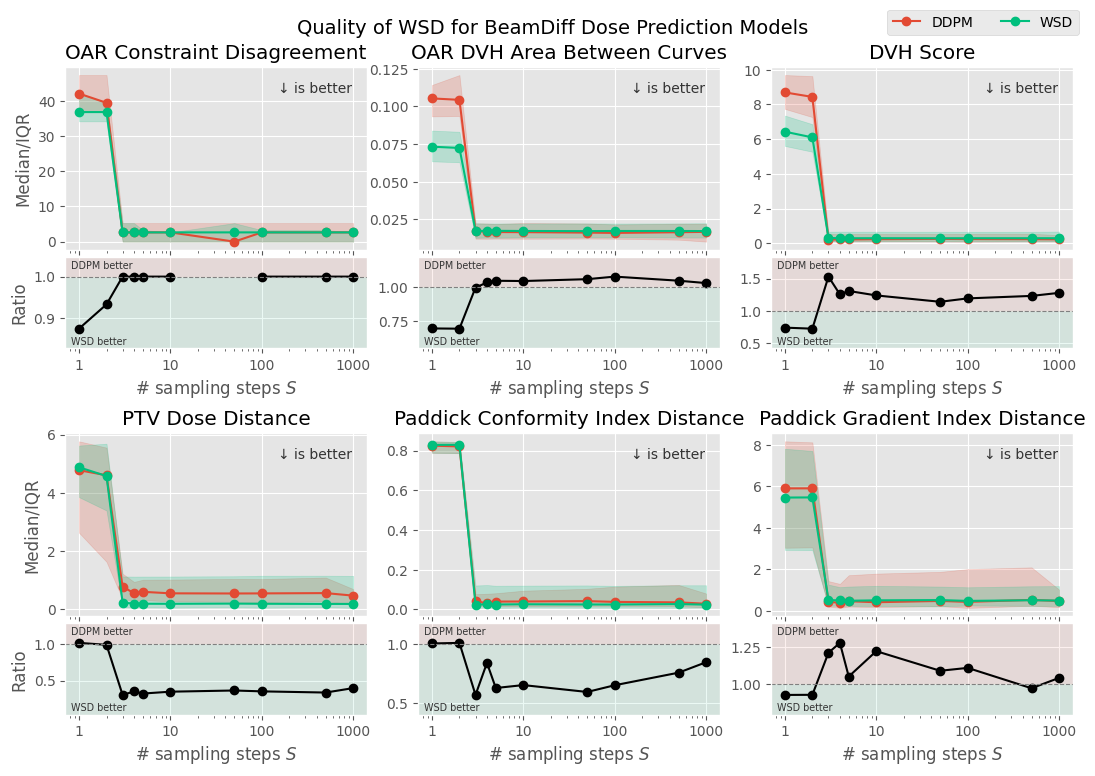

In [84]:
fig, all_axes = beamdiff_ddpm_wsd_comparison.plot_quality_over_T_paired(
    METRICS_PRED, agg='median', xscale='log',
    colors={'DDPM': '#E24A33', 'WSD': "#00BF7D"},
)
fig.set_size_inches(FIG_WIDTH + 1, 8)

for ax_top, ax_bot in all_axes:
    for ax in [ax_top, ax_bot]:
        ax.set_xticks([1, 10, 100, 1000])

fig.suptitle('Quality of WSD for BeamDiff Dose Prediction Models', fontsize=14)
plt.savefig('../imgs/pred-beamdiff-ddpm-vs-wsd-metrics.svg', bbox_inches='tight')
plt.show()

In [85]:
beamdiff_ws_flow_100_pred = ModelResults('145-rfm-deeplabv3plus', 'flow-100', 199, 'test', dataset)
beamdiff_ws_flow_50_pred = ModelResults('145-rfm-deeplabv3plus', 'flow-50', 199, 'test', dataset)
beamdiff_ws_flow_10_pred = ModelResults('145-rfm-deeplabv3plus', 'flow-10', 199, 'test', dataset)
beamdiff_ws_flow_5_pred = ModelResults('145-rfm-deeplabv3plus', 'flow-5', 199, 'test', dataset)
beamdiff_ws_flow_4_pred = ModelResults('145-rfm-deeplabv3plus', 'flow-4', 199, 'test', dataset)
beamdiff_ws_flow_3_pred = ModelResults('145-rfm-deeplabv3plus', 'flow-3', 199, 'test', dataset)
beamdiff_ws_flow_2_pred = ModelResults('145-rfm-deeplabv3plus', 'flow-2', 199, 'test', dataset)
beamdiff_ws_flow_1_pred = ModelResults('145-rfm-deeplabv3plus', 'flow-1', 199, 'test', dataset)

In [86]:
beamdiff_flow_ws_flow_comparison = ModelComparison(
  [beamdiff_flow_100_pred, beamdiff_flow_50_pred, beamdiff_flow_10_pred, beamdiff_flow_5_pred, beamdiff_flow_4_pred, beamdiff_flow_3_pred, beamdiff_flow_2_pred, beamdiff_flow_1_pred,
   beamdiff_ws_flow_100_pred, beamdiff_ws_flow_50_pred, beamdiff_ws_flow_10_pred, beamdiff_ws_flow_5_pred, beamdiff_ws_flow_4_pred, beamdiff_ws_flow_3_pred, beamdiff_ws_flow_2_pred, beamdiff_ws_flow_1_pred],
  ['RFM S=100', 'RFM S=50', 'RFM S=10', 'RFM S=5', 'RFM S=4', 'RFM S=3', 'RFM S=2', 'RFM S=1',
   'WS-RFM S=100', 'WS-RFM S=50', 'WS-RFM S=10', 'WS-RFM S=5', 'WS-RFM S=4', 'WS-RFM S=3', 'WS-RFM S=2', 'WS-RFM S=1'],
  ['RFM'] * 8 + ['WS-RFM'] * 8
)

In [87]:
beamdiff_ddpm_wsd_filtered_comparison = beamdiff_ddpm_wsd_comparison - beamdiff_amp_199_pred - beamdiff_ddpm_500_pred - beamdiff_wsd_ddpm_1000_pred - beamdiff_wsd_ddpm_500_pred

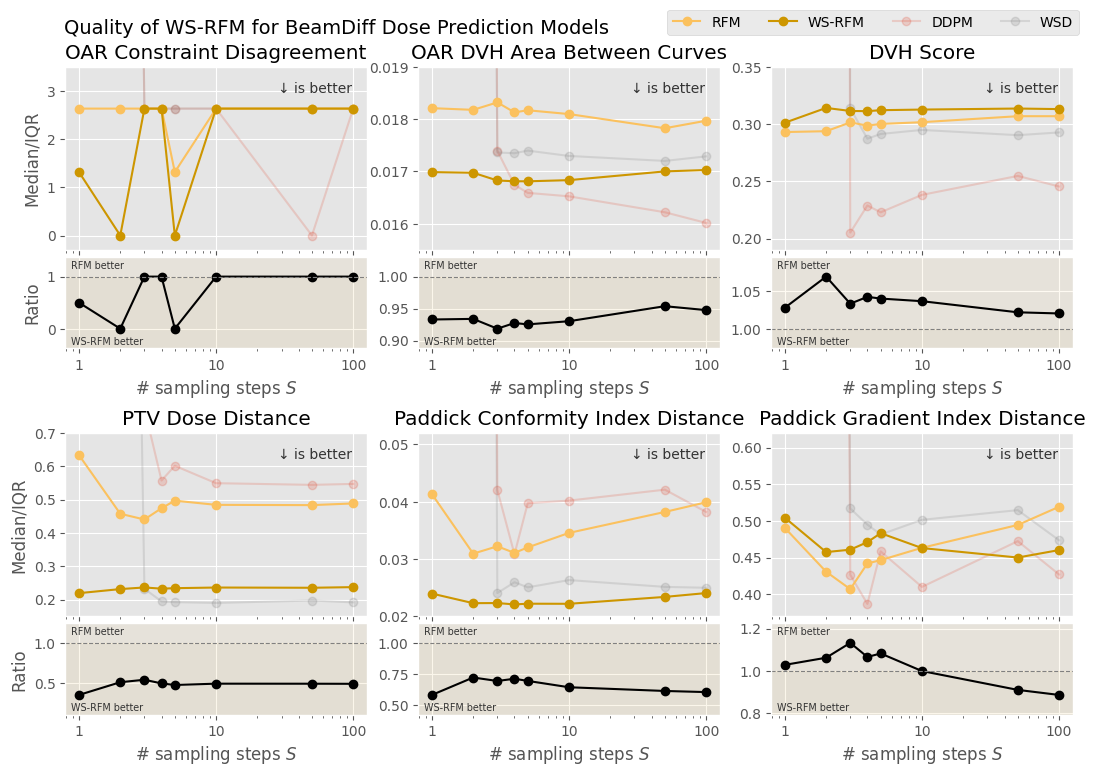

In [88]:
fig, all_axes = beamdiff_flow_ws_flow_comparison.plot_quality_over_T_paired(
    METRICS_PRED, agg='median', xscale='log', show_uncertainty=False, n_col_legend=4,
    colors={'RFM': '#FBC15E', 'WS-RFM': "#CD9600"},
    background=beamdiff_ddpm_wsd_filtered_comparison, bg_alpha=0.2,
    bg_colors={'DDPM': '#E24A33', 'WSD DDPM': '#2CA02C'},
)
fig.set_size_inches(FIG_WIDTH + 1, 8)

for ax_top, ax_bot in all_axes:
    for ax in [ax_top, ax_bot]:
        ax.set_xticks([1, 10, 100])

all_axes[0][0].set_ylim(-0.3, 3.5)
all_axes[1][0].set_ylim(0.0155, 0.019)
all_axes[2][0].set_ylim(0.19, 0.35)
all_axes[3][0].set_ylim(0.15, 0.7)
all_axes[4][0].set_ylim(0.02, 0.052)
all_axes[5][0].set_ylim(0.37, 0.62)

fig.suptitle(
    'Quality of WS-RFM for BeamDiff Dose Prediction Models',
    fontsize=14,
    horizontalalignment='right',
    x=0.543,
)
plt.savefig('../imgs/pred-beamdiff-flow-vs-ws-flow-metrics.svg', bbox_inches='tight')
plt.show()

In [89]:
beamdiff_indi_1000_pred = ModelResults('141-indi-deeplabv3plus', 'indi-1000', 199, 'test', dataset)
beamdiff_indi_500_pred = ModelResults('141-indi-deeplabv3plus', 'indi-500', 199, 'test', dataset)
beamdiff_indi_100_pred = ModelResults('141-indi-deeplabv3plus', 'indi-100', 199, 'test', dataset)
beamdiff_indi_50_pred = ModelResults('141-indi-deeplabv3plus', 'indi-50', 199, 'test', dataset)
beamdiff_indi_10_pred = ModelResults('141-indi-deeplabv3plus', 'indi-10', 199, 'test', dataset)
beamdiff_indi_5_pred = ModelResults('141-indi-deeplabv3plus', 'indi-5', 199, 'test', dataset)
beamdiff_indi_4_pred = ModelResults('141-indi-deeplabv3plus', 'indi-4', 199, 'test', dataset)
beamdiff_indi_3_pred = ModelResults('141-indi-deeplabv3plus', 'indi-3', 199, 'test', dataset)
beamdiff_indi_2_pred = ModelResults('141-indi-deeplabv3plus', 'indi-2', 199, 'test', dataset)
beamdiff_indi_1_pred = ModelResults('141-indi-deeplabv3plus', 'indi-1', 199, 'test', dataset)

In [90]:
beamdiff_hybrid_comparison = ModelComparison(
  [#beamdiff_wsd_ddpm_100_pred, beamdiff_wsd_ddpm_50_pred, beamdiff_wsd_ddpm_10_pred, beamdiff_wsd_ddpm_5_pred, beamdiff_wsd_ddpm_4_pred, beamdiff_wsd_ddpm_3_pred, beamdiff_wsd_ddpm_2_pred, beamdiff_wsd_ddpm_1_pred,
   beamdiff_ws_flow_100_pred, beamdiff_ws_flow_50_pred, beamdiff_ws_flow_10_pred, beamdiff_ws_flow_5_pred, beamdiff_ws_flow_4_pred, beamdiff_ws_flow_3_pred, beamdiff_ws_flow_2_pred, beamdiff_ws_flow_1_pred,
   beamdiff_indi_100_pred, beamdiff_indi_50_pred, beamdiff_indi_10_pred, beamdiff_indi_5_pred, beamdiff_indi_4_pred, beamdiff_indi_3_pred, beamdiff_indi_2_pred, beamdiff_indi_1_pred],
  [#'WSD S=100', 'WSD S=50', 'WSD S=10', 'WSD S=5', 'WSD S=4', 'WSD S=3', 'WSD S=2', 'WSD S=1',
   'WS-RFM S=100', 'WS-RFM S=50', 'WS-RFM S=10', 'WS-RFM S=5', 'WS-RFM S=4', 'WS-RFM S=3', 'WS-RFM S=2', 'WS-RFM S=1',
   'InDI S=100', 'InDI S=50', 'InDI S=10', 'InDI S=5', 'InDI S=4', 'InDI S=3', 'InDI S=2', 'InDI S=1'
])

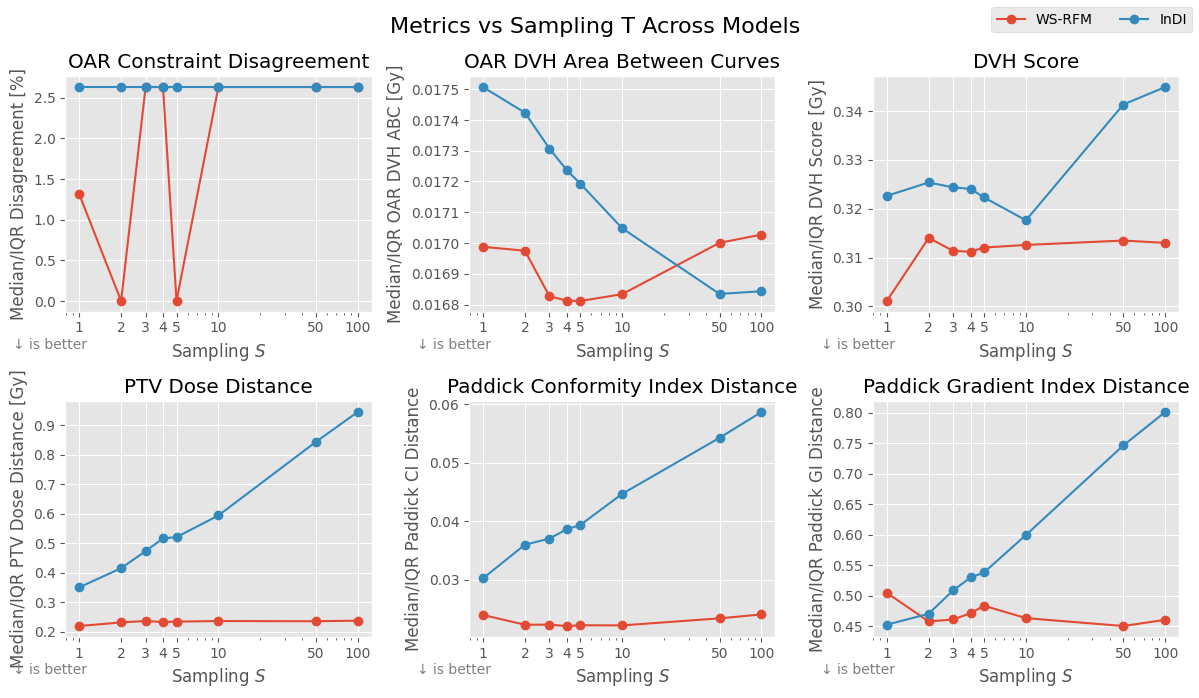

In [91]:
_ = beamdiff_hybrid_comparison.plot_quality_over_T(METRICS_PRED, agg='median', xscale='log', show_uncertainty=False)

In [92]:
beamdiff_best_hybrid_comparison = ModelComparison(
  [beamdiff_wsd_ddpm_3_pred, beamdiff_flow_2_pred, beamdiff_ws_flow_2_pred, beamdiff_ws_flow_1_pred, beamdiff_indi_1_pred],
  ['WSD\nS=3', 'RFM\nS=2', 'WS-RFM\nS=2', 'WS-RFM\nS=1', 'InDI\nS=1'],
  ['WSD DDPM', 'RFM', 'WS-RFM', 'WS-RFM', 'InDI']
)

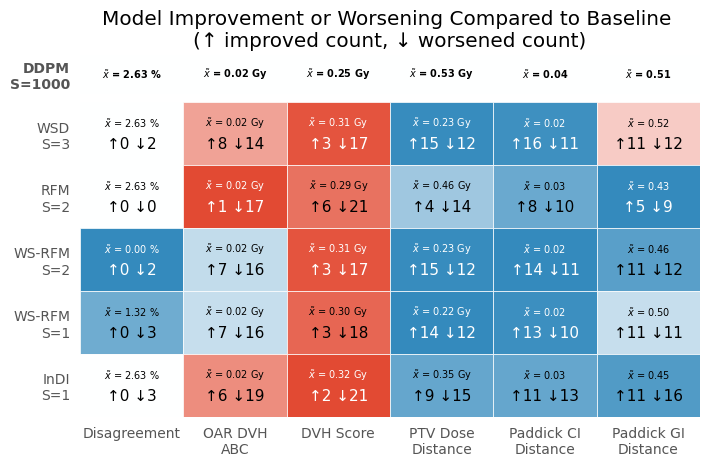

In [93]:
_ = beamdiff_best_hybrid_comparison.plot_metric_heatmap(
  METRICS_PRED,
  baseline=pred_beamdiff_baseline_comparison,
  improved_q=0.975,
  worsened_q=0.025,
  sort=False,
  baseline_label='DDPM\nS=1000',
)

- DDPM S=1000
- RFM S=2
- WSD S=3
- WS-RFM S=1
- WS-RFM S=2
- InDI S=1

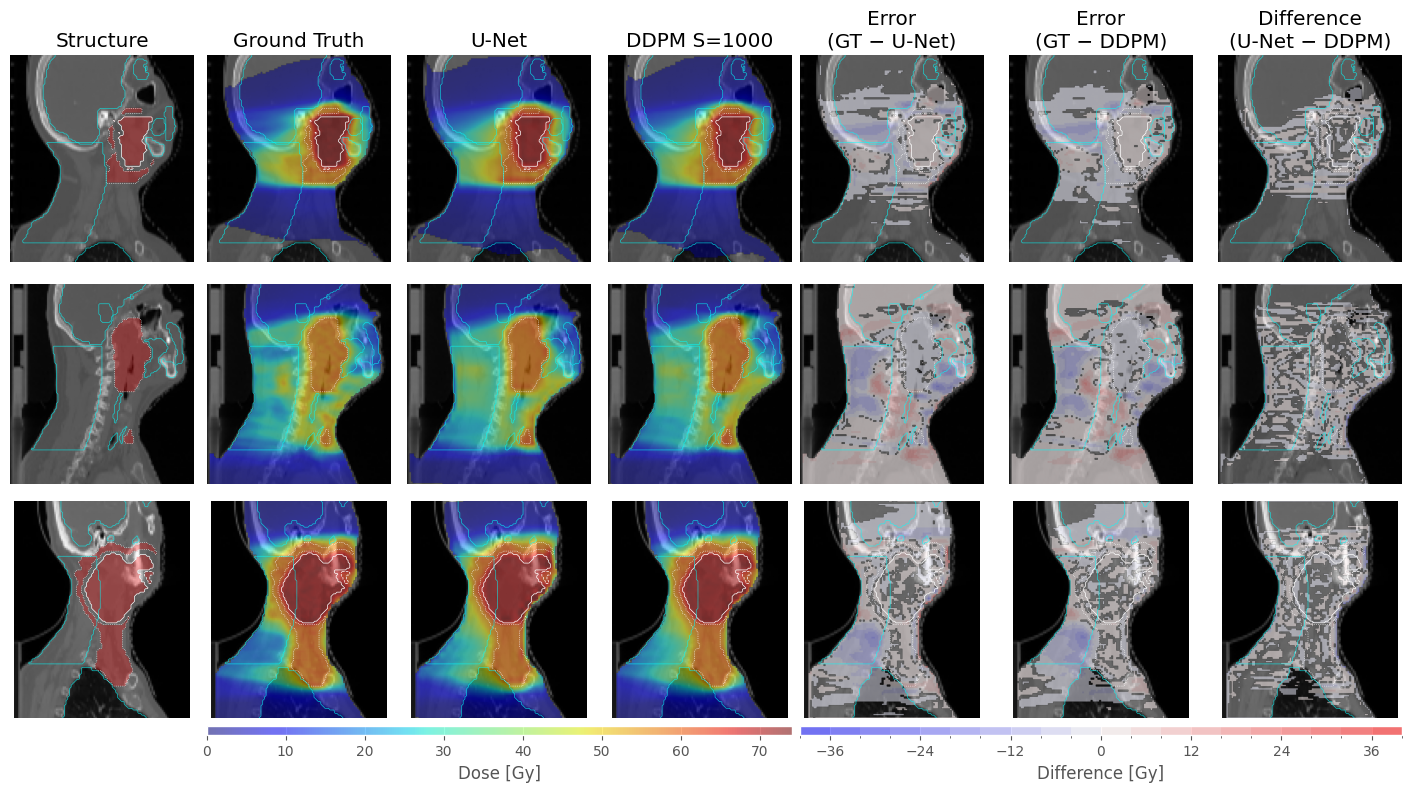

In [103]:
from results import draw_ptv_overlay, draw_ptv_contours, draw_oar_contours
from matplotlib.colors import BoundaryNorm

def visualise_hybrid_effect(
    ws_unet_result,
    ddpm_result,
    slices,
    axis='sagittal',
    dose_cmap='jet',
    dose_alpha=0.5,
    show_oar=True,
    crop_to_body=True,
    crop_padding=0,
    max_error=None,
    dose_range=None,
    n_error_levels=11,
):
    """
    Visualise the hybrid approach effect.
    Columns: Structure | GT | WS-UNet | DDPM S=1000 | Diff(GT - WS-UNet) | Diff(GT - DDPM) | Diff(WS-UNet - DDPM)
    Rows: one per (sample, slice_index) in slices, plus a colorbar row at the bottom.
    """
    n_rows = len(slices)
    n_cols = 7
    row_height = 2.4
    cbar_height_ratios = [1] * n_rows + [0.04]

    fig, all_axes = plt.subplots(
        n_rows + 1, n_cols,
        figsize=(14, row_height * n_rows + 0.6),
        gridspec_kw={'height_ratios': cbar_height_ratios},
        constrained_layout=True,
        squeeze=False,
    )
    axes = all_axes[:n_rows]
    cbar_axes = all_axes[n_rows]
    cbar_axes[0].axis('off')

    # Pre-compute global dose and error ranges
    global_dose_max = 0
    global_error_max = 0
    slice_data = []

    for sample, slice_index in slices:
        ws_sr = ws_unet_result.for_sample(sample)
        ddpm_sr = ddpm_result.for_sample(sample)

        structure_vol, original_dose_vol = ws_sr.load_orig_volume()
        ws_pred_vol = ws_sr.load_pred_volume()
        ddpm_pred_vol = ddpm_sr.load_pred_volume()

        if axis == "sagittal":
            structure = np.flip(structure_vol[:, :, :, slice_index], [1, 2])
            original_dose = np.flip(original_dose_vol[:, :, slice_index])
            ws_pred = np.flip(ws_pred_vol[:, :, slice_index])
            ddpm_pred = np.flip(ddpm_pred_vol[:, :, slice_index])
        elif axis == "axial":
            structure = structure_vol[:, slice_index, :, :]
            original_dose = original_dose_vol[slice_index, :, :]
            ws_pred = ws_pred_vol[slice_index, :, :]
            ddpm_pred = ddpm_pred_vol[slice_index, :, :]
        elif axis == "coronal":
            structure = np.flip(structure_vol[:, :, slice_index, :], 1)
            original_dose = np.flip(original_dose_vol[:, slice_index, :], 0)
            ws_pred = np.flip(ws_pred_vol[:, slice_index, :], 0)
            ddpm_pred = np.flip(ddpm_pred_vol[:, slice_index, :], 0)
        else:
            raise ValueError(f'Invalid axis: {axis}')

        ct_slice = ws_unet_result.dataset.selector.get_ct(structure)[0]
        ptv_doses = ws_unet_result.dataset.selector.get_component(structure, 'ptv_doses')
        oar_masks = ws_unet_result.dataset.selector.get_component(structure, 'oar_v3') if show_oar else None

        ws_error = original_dose - ws_pred
        ddpm_error = original_dose - ddpm_pred
        ws_ddpm_diff = ws_pred - ddpm_pred

        global_dose_max = max(global_dose_max, original_dose.max())
        global_error_max = max(global_error_max, np.abs(ws_error).max(), np.abs(ddpm_error).max(), np.abs(ws_ddpm_diff).max())

        slice_data.append((ct_slice, ptv_doses, oar_masks, original_dose, ws_pred, ddpm_pred, ws_error, ddpm_error, ws_ddpm_diff))

    if dose_range is not None:
        dose_min, dose_max = dose_range
    else:
        dose_min, dose_max = 0, global_dose_max

    if max_error is not None:
        global_error_max = max_error

    error_boundaries = np.linspace(-global_error_max, global_error_max, n_error_levels + 1)
    error_norm = BoundaryNorm(error_boundaries, plt.get_cmap('bwr').N)

    im_dose = None
    im_err = None

    for row, (ct_slice, ptv_doses, oar_masks, original_dose, ws_pred, ddpm_pred, ws_error, ddpm_error, ws_ddpm_diff) in enumerate(slice_data):
        def _draw_contours(ax, _ptv=ptv_doses, _oar=oar_masks):
            draw_ptv_contours(ax, _ptv)
            if show_oar and _oar is not None:
                draw_oar_contours(ax, _oar)

        # Col 0: Structure (CT + PTV + OAR)
        ax = axes[row, 0]
        ax.imshow(ct_slice, cmap='gray')
        draw_ptv_overlay(ax, ptv_doses)
        _draw_contours(ax)
        ax.axis('off')

        # Col 1: Ground Truth dose
        ax = axes[row, 1]
        ax.imshow(ct_slice, cmap='gray')
        dose_masked = np.ma.masked_where(original_dose < 0.01 * dose_max, original_dose)
        im_dose = ax.imshow(dose_masked, cmap=dose_cmap, alpha=dose_alpha, vmin=dose_min, vmax=dose_max)
        _draw_contours(ax)
        ax.axis('off')

        # Col 2: WS-UNet prediction
        ax = axes[row, 2]
        ax.imshow(ct_slice, cmap='gray')
        ws_masked = np.ma.masked_where(ws_pred < 0.01 * dose_max, ws_pred)
        ax.imshow(ws_masked, cmap=dose_cmap, alpha=dose_alpha, vmin=dose_min, vmax=dose_max)
        _draw_contours(ax)
        ax.axis('off')

        # Col 3: DDPM S=1000 prediction
        ax = axes[row, 3]
        ax.imshow(ct_slice, cmap='gray')
        ddpm_masked = np.ma.masked_where(ddpm_pred < 0.01 * dose_max, ddpm_pred)
        ax.imshow(ddpm_masked, cmap=dose_cmap, alpha=dose_alpha, vmin=dose_min, vmax=dose_max)
        _draw_contours(ax)
        ax.axis('off')

        # Col 4: Diff GT - WS-UNet
        ax = axes[row, 4]
        ax.imshow(ct_slice, cmap='gray')
        ws_err_masked = np.ma.masked_where(np.abs(ws_error) < 0.01 * global_error_max, ws_error)
        im_err = ax.imshow(ws_err_masked, cmap='bwr', alpha=dose_alpha, norm=error_norm)
        _draw_contours(ax)
        ax.axis('off')

        # Col 5: Diff GT - DDPM
        ax = axes[row, 5]
        ax.imshow(ct_slice, cmap='gray')
        ddpm_err_masked = np.ma.masked_where(np.abs(ddpm_error) < 0.01 * global_error_max, ddpm_error)
        ax.imshow(ddpm_err_masked, cmap='bwr', alpha=dose_alpha, norm=error_norm)
        _draw_contours(ax)
        ax.axis('off')

        # Col 6: Diff WS-UNet - DDPM
        ax = axes[row, 6]
        ax.imshow(ct_slice, cmap='gray')
        ws_ddpm_masked = np.ma.masked_where(np.abs(ws_ddpm_diff) < 0.01 * global_error_max, ws_ddpm_diff)
        ax.imshow(ws_ddpm_masked, cmap='bwr', alpha=dose_alpha, norm=error_norm)
        _draw_contours(ax)
        ax.axis('off')

        # Crop to body
        if crop_to_body:
            body_mask = ct_slice > ct_slice.min()
            rows_mask = np.any(body_mask, axis=1)
            cols_mask = np.any(body_mask, axis=0)
            rmin, rmax = np.where(rows_mask)[0][[0, -1]]
            cmin, cmax = np.where(cols_mask)[0][[0, -1]]
            rmin = max(0, rmin - crop_padding)
            rmax = min(ct_slice.shape[0] - 1, rmax + crop_padding)
            cmin = max(0, cmin - crop_padding)
            cmax = min(ct_slice.shape[1] - 1, cmax + crop_padding)
            for a in axes[row, :]:
                a.set_xlim(cmin, cmax)
                a.set_ylim(rmax, rmin)

    # Column titles
    titles = ['Structure', 'Ground Truth', 'U-Net', 'DDPM S=1000', 'Error\n(GT − U-Net)', 'Error\n(GT − DDPM)', 'Difference\n(U-Net − DDPM)']
    for col, title in enumerate(titles):
        axes[0, col].set_title(title)

    # Horizontal colorbars in dedicated bottom row
    gs = all_axes[0, 0].get_gridspec()

    # Merge cells 1–3 for dose colorbar
    for ax in cbar_axes[1:4]:
        ax.remove()
    cax_dose = fig.add_subplot(gs[n_rows, 1:4])
    fig.colorbar(im_dose, cax=cax_dose, orientation='horizontal', label='Dose [Gy]')

    # Merge cells 4–6 for error colorbar
    for ax in cbar_axes[4:7]:
        ax.remove()
    cax_err = fig.add_subplot(gs[n_rows, 4:7])
    fig.colorbar(im_err, cax=cax_err, orientation='horizontal', label='Difference [Gy]')

    return fig, axes


visualise_hybrid_effect(
    ws_unet_result=deeplabv3plus_ws_pred,
    ddpm_result=beamdiff_wsd_ddpm_1000_pred,
    slices=[
        ('HNSCC-01-0078+A4Ac+MOS_12319', 110),
        ('HNC_004+A4Ac+MOS_11506', 105),
        ('0522c0723+A4Ac+MOS_2890', 80),
    ],
    crop_to_body=True,
    crop_padding=0,
    max_error=40,
    dose_range=(0, 74),
    n_error_levels=20,
)
plt.show()

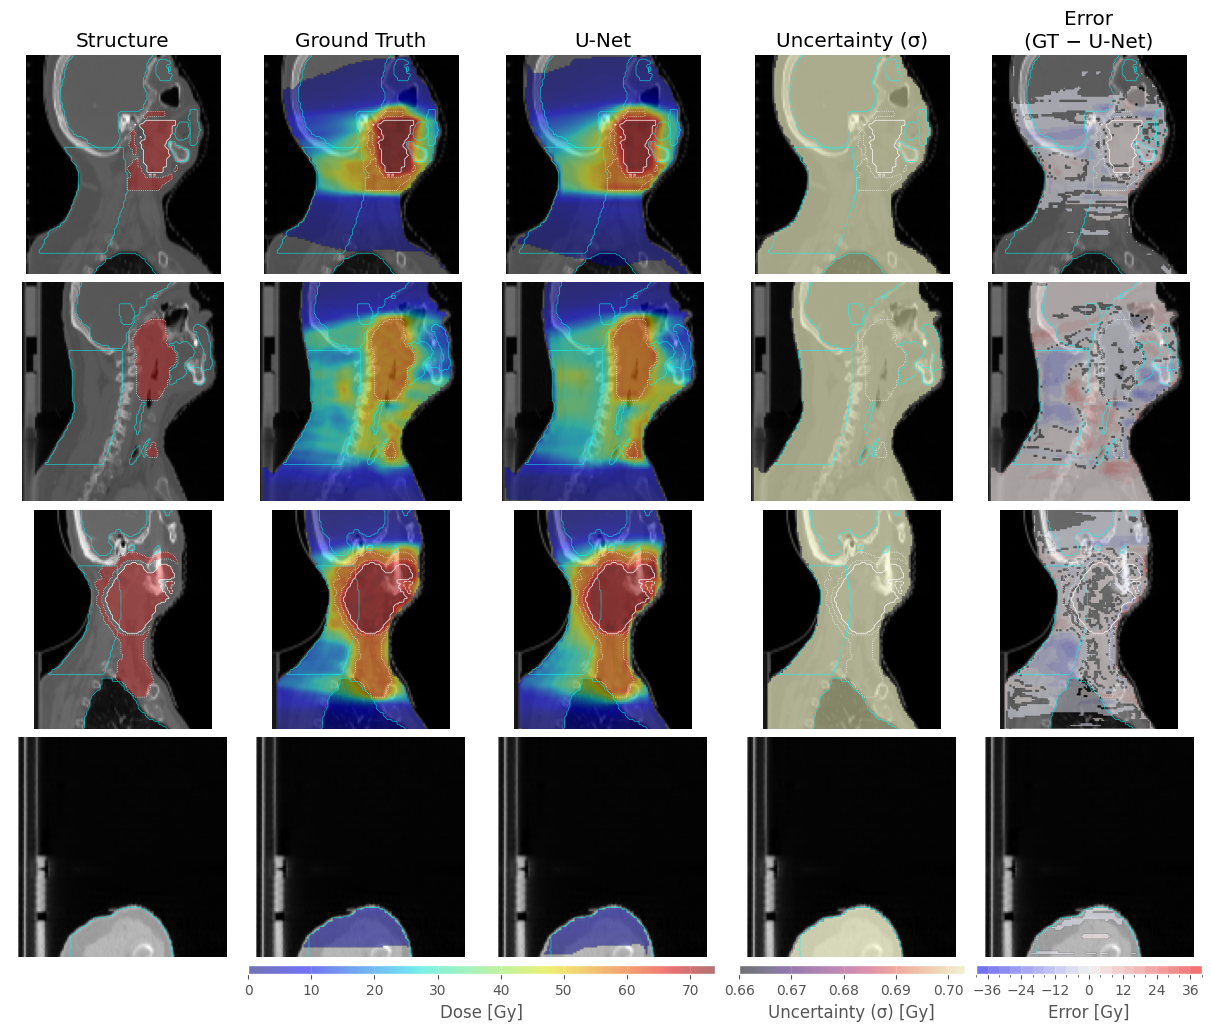

In [ ]:
def visualise_unet_with_uncertainty(
    unet_result,
    slices,
    axis='sagittal',
    dose_cmap='jet',
    dose_alpha=0.5,
    show_oar=True,
    crop_to_body=True,
    crop_padding=0,
    max_error=None,
    dose_range=None,
    n_error_levels=11,
    uncertainty_cmap='magma',
):
    """
    Visualise U-Net predictions with uncertainty.
    Columns: Structure | GT | U-Net | Uncertainty | Error (GT − U-Net)
    Rows: one per (sample, slice_index) in slices, plus a colorbar row at the bottom.
    """
    n_rows = len(slices)
    n_cols = 5
    row_height = 2.4
    cbar_height_ratios = [1] * n_rows + [0.04]

    fig, all_axes = plt.subplots(
        n_rows + 1, n_cols,
        figsize=(12, row_height * n_rows + 0.6),
        gridspec_kw={'height_ratios': cbar_height_ratios},
        constrained_layout=True,
        squeeze=False,
    )
    axes = all_axes[:n_rows]
    cbar_axes = all_axes[n_rows]
    cbar_axes[0].axis('off')

    # Pre-compute global ranges
    global_dose_max = 0
    global_error_max = 0
    global_uncert_max = 0
    slice_data = []

    for sample, slice_index in slices:
        sr = unet_result.for_sample(sample)

        structure_vol, original_dose_vol = sr.load_orig_volume()
        pred_vol = sr.load_pred_volume()
        sigma_vol = np.load(sr.base_path / f'{sr.sample}_sigma.npy')[0]

        if axis == "sagittal":
            structure = np.flip(structure_vol[:, :, :, slice_index], [1, 2])
            original_dose = np.flip(original_dose_vol[:, :, slice_index])
            pred = np.flip(pred_vol[:, :, slice_index])
            sigma = np.flip(sigma_vol[:, :, slice_index])
        elif axis == "axial":
            structure = structure_vol[:, slice_index, :, :]
            original_dose = original_dose_vol[slice_index, :, :]
            pred = pred_vol[slice_index, :, :]
            sigma = sigma_vol[slice_index, :, :]
        elif axis == "coronal":
            structure = np.flip(structure_vol[:, :, slice_index, :], 1)
            original_dose = np.flip(original_dose_vol[:, slice_index, :], 0)
            pred = np.flip(pred_vol[:, slice_index, :], 0)
            sigma = np.flip(sigma_vol[:, slice_index, :], 0)
        else:
            raise ValueError(f'Invalid axis: {axis}')

        ct_slice = unet_result.dataset.selector.get_ct(structure)[0]
        ptv_doses = unet_result.dataset.selector.get_component(structure, 'ptv_doses')
        oar_masks = unet_result.dataset.selector.get_component(structure, 'oar_v3') if show_oar else None

        error = original_dose - pred

        global_dose_max = max(global_dose_max, original_dose.max())
        global_error_max = max(global_error_max, np.abs(error).max())
        global_uncert_max = max(global_uncert_max, sigma.max())

        slice_data.append((ct_slice, ptv_doses, oar_masks, original_dose, pred, sigma, error))

    if dose_range is not None:
        dose_min, dose_max = dose_range
    else:
        dose_min, dose_max = 0, global_dose_max

    if max_error is not None:
        global_error_max = max_error

    error_boundaries = np.linspace(-global_error_max, global_error_max, n_error_levels + 1)
    error_norm = BoundaryNorm(error_boundaries, plt.get_cmap('bwr').N)

    im_dose = None
    im_uncert = None
    im_err = None

    for row, (ct_slice, ptv_doses, oar_masks, original_dose, pred, sigma, error) in enumerate(slice_data):
        def _draw_contours(ax, _ptv=ptv_doses, _oar=oar_masks):
            draw_ptv_contours(ax, _ptv)
            if show_oar and _oar is not None:
                draw_oar_contours(ax, _oar)

        # Col 0: Structure (CT + PTV + OAR)
        ax = axes[row, 0]
        ax.imshow(ct_slice, cmap='gray')
        draw_ptv_overlay(ax, ptv_doses)
        _draw_contours(ax)
        ax.axis('off')

        # Col 1: Ground Truth dose
        ax = axes[row, 1]
        ax.imshow(ct_slice, cmap='gray')
        dose_masked = np.ma.masked_where(original_dose < 0.01 * dose_max, original_dose)
        im_dose = ax.imshow(dose_masked, cmap=dose_cmap, alpha=dose_alpha, vmin=dose_min, vmax=dose_max)
        _draw_contours(ax)
        ax.axis('off')

        # Col 2: U-Net prediction
        ax = axes[row, 2]
        ax.imshow(ct_slice, cmap='gray')
        pred_masked = np.ma.masked_where(pred < 0.01 * dose_max, pred)
        ax.imshow(pred_masked, cmap=dose_cmap, alpha=dose_alpha, vmin=dose_min, vmax=dose_max)
        _draw_contours(ax)
        ax.axis('off')

        # Col 3: Uncertainty (sigma)
        ax = axes[row, 3]
        ax.imshow(ct_slice, cmap='gray')
        uncert_masked = np.ma.masked_where(sigma < 0.01 * global_uncert_max, sigma)
        print(sigma.min(), sigma.max(), uncert_masked.min(), uncert_masked.max())
        im_uncert = ax.imshow(uncert_masked, cmap=uncertainty_cmap, alpha=dose_alpha, vmin=0.66, vmax=global_uncert_max)
        _draw_contours(ax)
        ax.axis('off')

        # Col 4: Error (GT - U-Net)
        ax = axes[row, 4]
        ax.imshow(ct_slice, cmap='gray')
        err_masked = np.ma.masked_where(np.abs(error) < 0.01 * global_error_max, error)
        im_err = ax.imshow(err_masked, cmap='bwr', alpha=dose_alpha, norm=error_norm)
        _draw_contours(ax)
        ax.axis('off')

        # Crop to body
        if crop_to_body:
            body_mask = ct_slice > ct_slice.min()
            rows_mask = np.any(body_mask, axis=1)
            cols_mask = np.any(body_mask, axis=0)
            rmin, rmax = np.where(rows_mask)[0][[0, -1]]
            cmin, cmax = np.where(cols_mask)[0][[0, -1]]
            rmin = max(0, rmin - crop_padding)
            rmax = min(ct_slice.shape[0] - 1, rmax + crop_padding)
            cmin = max(0, cmin - crop_padding)
            cmax = min(ct_slice.shape[1] - 1, cmax + crop_padding)
            for a in axes[row, :]:
                a.set_xlim(cmin, cmax)
                a.set_ylim(rmax, rmin)

    # Column titles
    titles = ['Structure', 'Ground Truth', 'U-Net', 'Uncertainty (σ)', 'Error\n(GT − U-Net)']
    for col, title in enumerate(titles):
        axes[0, col].set_title(title)

    # Horizontal colorbars in dedicated bottom row
    gs = all_axes[0, 0].get_gridspec()

    # Dose colorbar (cols 1-2)
    for ax in cbar_axes[1:3]:
        ax.remove()
    cax_dose = fig.add_subplot(gs[n_rows, 1:3])
    fig.colorbar(im_dose, cax=cax_dose, orientation='horizontal', label='Dose [Gy]')

    # Uncertainty colorbar (col 3)
    cbar_axes[3].remove()
    cax_uncert = fig.add_subplot(gs[n_rows, 3:4])
    fig.colorbar(im_uncert, cax=cax_uncert, orientation='horizontal', label='Uncertainty (σ) [Gy]')

    # Error colorbar (col 4)
    cbar_axes[4].remove()
    cax_err = fig.add_subplot(gs[n_rows, 4:5])
    fig.colorbar(im_err, cax=cax_err, orientation='horizontal', label='Error [Gy]')

    return fig, axes


visualise_unet_with_uncertainty(
    unet_result=deeplabv3plus_ws_pred,
    slices=[
        ('HNSCC-01-0078+A4Ac+MOS_12319', 110),
        ('HNC_004+A4Ac+MOS_11506', 105),
        ('0522c0723+A4Ac+MOS_2890', 80),
        ('HNC_135+A4Ac+MOS_2696', 24)
    ],
    crop_to_body=True,
    crop_padding=0,
    max_error=40,
    dose_range=(0, 74),
    n_error_levels=20,
)
plt.show()

In [ ]:
calc correlation between uncertainty and error (abs diff between GT and prediction) for ws-unet